structure

# Functional Programming 在 AI System 的應用

Functional Programming（FP，函數式程式設計）在 AI System 中其實相當重要。尤其是現在的 AI 系統已經不只是執行單一模型，而是包含資料處理、模型訓練、推論（Inference）、Agent、工具呼叫（Tool Calling）以及分散式運算等多個層次。

一個重要觀念：

**Functional Programming 的價值，不只是讓程式碼變得簡潔，而是讓複雜的 AI 系統更容易組合、測試、平行化與維護。**

以下從六個應用面向來說明。

## 1. Data Pipeline：AI 資料處理流程

AI 系統在訓練模型之前，通常需要經過一連串資料處理：

1. 讀取資料。
2. 清除錯誤資料。
3. 正規化（Normalization）。
4. 特徵轉換（Feature Transformation）。
5. 將資料送入模型。

例如：

```python
def normalize(x):
    return (x - 0) / 100

def square(x):
    return x ** 2

numbers = [10, 20, 30, 40]

result = list(map(square, map(normalize, numbers)))
```

可以用函數組合（Function Composition）理解：

$$
f(x)=x^2
$$

$$
g(x)=\frac{x}{100}
$$

因此：

$$
(f\circ g)(x)=f(g(x))
$$

這種方式將每個資料處理步驟拆成獨立函數。

**FP 的優勢：**

- 每個處理步驟可以獨立測試。
- 容易重新組合資料處理流程。
- 減少共享狀態造成的錯誤。
- 適合建立可重複執行的 Data Pipeline。

## 2. Deep Learning：神經網路與 Functional API

這是 FP 在 AI 領域非常直接的應用。

以神經網路為例，一個簡化的 Neural Network 可以表示為：

$$
y=f_3(f_2(f_1(x)))
$$

其中：

- $f_1$：第一層神經網路。
- $f_2$：第二層神經網路。
- $f_3$：輸出層。

這其實就是 Function Composition（函數組合）。

在 Python 中，PyTorch 提供 Functional API，例如：

```python
import torch
import torch.nn.functional as F

x = torch.randn(32, 128)

W1 = torch.randn(128, 64)
b1 = torch.randn(64)

W2 = torch.randn(64, 10)
b2 = torch.randn(10)

h = F.relu(x @ W1 + b1)
y = F.softmax(h @ W2 + b2, dim=1)
```

這裡的 `F.relu()`、`F.softmax()` 都是函數式操作。

值得注意的是，PyTorch 也有物件導向的 `nn.Module`：

```python
import torch.nn as nn

model = nn.Sequential(
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 10)
)
```

兩種寫法並不衝突。

| 面向 | Functional API | Object-Oriented API |
|---|---|---|
| 表達方式 | 函數組合 | 物件與方法 |
| 模型結構 | 直接描述運算 | 使用 Module 組合 |
| 狀態管理 | 可以明確傳遞參數與狀態 | 通常封裝在物件中 |
| 適用情境 | 自訂運算、研究、模型控制 | 一般模型開發與管理 |

這也說明：

**AI Framework 不一定是純粹的 Functional Programming，但大量使用了 FP 的設計思想。**

## 3. PyTorch：Functional Programming 在 Deep Learning 中的應用

如果要了解 Functional Programming 如何應用於 AI System，PyTorch 是很好的實例。

[PyTorch 官方網站](https://pytorch.org/)

PyTorch 是一個廣泛使用的 Deep Learning Framework，提供 Tensor 運算、Automatic Differentiation、GPU 加速以及神經網路模型建構等功能。

其中，Functional Programming 的思想主要可以從以下幾個方面理解。

### 3.1 Tensor Operations：函數式運算

在 PyTorch 中，許多運算可以直接透過函數完成。

```python
import torch
import torch.nn.functional as F

x = torch.tensor([1.0, 2.0, 3.0])

y = F.relu(x)

print(y)
```

輸出：

```text
tensor([1., 2., 3.])
```

這裡的 `F.relu()` 接收 Tensor，並回傳運算結果。

可以將它理解成：

$$
f(x)=\operatorname{ReLU}(x)
$$

其中：

$$
\operatorname{ReLU}(x)=\max(0,x)
$$

這種將輸入轉換成輸出的方式，與 Functional Programming 的函數運算概念相符。

### 3.2 Function Composition：神經網路的函數組合

一個 Neural Network 可以視為多個函數的組合：

$$
y=f_3(f_2(f_1(x)))
$$

例如：

```python
import torch
import torch.nn.functional as F

x = torch.randn(32, 128)

W1 = torch.randn(128, 64)
b1 = torch.randn(64)

W2 = torch.randn(64, 10)
b2 = torch.randn(10)

h = F.relu(x @ W1 + b1)
y = F.softmax(h @ W2 + b2, dim=1)
```

這裡：

- 第一層：Linear Transformation。
- 第二層：ReLU Activation。
- 第三層：Linear Transformation。
- 第四層：Softmax。

整體可以表示為：

$$
y=
\operatorname{Softmax}
\left(
W_2\operatorname{ReLU}(W_1x+b_1)+b_2
\right)
$$

這是一個很好的例子，說明神經網路可以透過函數組合建立。

### 3.3 Automatic Differentiation：自動微分

PyTorch 最重要的功能之一是 Automatic Differentiation（自動微分）。

例如：

```python
import torch

x = torch.tensor(3.0, requires_grad=True)

y = x ** 2

y.backward()

print(x.grad)
```

輸出：

```text
tensor(6.)
```

數學上：

$$
f(x)=x^2
$$

因此：

$$
f'(x)=2x
$$

當：

$$
x=3
$$

得到：

$$
f'(3)=6
$$

PyTorch 透過 Autograd 機制，自動計算微分。

這是 Deep Learning 中 Gradient Descent 與 Backpropagation 的重要基礎。

### 3.4 Higher-Order Functions：函數作為運算對象

Functional Programming 的另一個重要概念是 Higher-Order Functions（高階函數）。

也就是函數可以接受其他函數作為參數，或回傳另一個函數。

PyTorch 提供 `torch.func`，其中包含：

- `grad()`：計算函數的梯度。
- `vmap()`：對函數進行向量化。
- `jacrev()`：計算 Jacobian Matrix。
- `jacfwd()`：使用 Forward-mode Automatic Differentiation 計算 Jacobian。

例如：

```python
import torch
from torch.func import grad

def f(x):
    return x ** 2

df = grad(f)

x = torch.tensor(3.0)

print(df(x))
```

輸出：

```text
tensor(6.)
```

這裡的 `grad(f)` 接收函數 `f`，並回傳一個新的梯度函數。

數學上可以理解為：

$$
\operatorname{grad}(f)=f'
$$

這是一個非常直接的 Higher-Order Function 實例。

### 3.5 Functional API 與 Object-Oriented API

PyTorch 同時提供 Functional API 與 Object-Oriented API。

例如，使用 Functional API：

```python
import torch
import torch.nn.functional as F

x = torch.randn(32, 128)

W = torch.randn(128, 64)
b = torch.randn(64)

y = F.relu(x @ W + b)
```

使用 Object-Oriented API：

```python
import torch.nn as nn

model = nn.Sequential(
    nn.Linear(128, 64),
    nn.ReLU()
)
```

兩種方式都可以建立神經網路。

| 比較項目 | Functional API | Object-Oriented API |
|---|---|---|
| 主要概念 | 函數運算 | 物件與模組 |
| 模型參數 | 通常明確傳入 | 通常封裝於 Module |
| 運算方式 | 呼叫函數 | 呼叫物件方法 |
| 適用情境 | 自訂運算、研究 | 模型建構與管理 |

值得注意的是，PyTorch 的 Functional API 並不代表所有操作都是純函數（Pure Functions）。例如某些操作會修改輸入 Tensor，或受到外部狀態影響。

### 3.6 PyTorch 在 AI System 中的角色

PyTorch 不只是建立 Neural Network 的工具，也提供 AI System 所需要的底層運算能力。

| 功能 | PyTorch 技術 | AI System 應用 |
|---|---|---|
| Tensor Operations | `torch.Tensor` | 數值運算 |
| Automatic Differentiation | `torch.autograd` | Backpropagation |
| Functional Transformations | `torch.func` | Gradient、Vectorization |
| Neural Network | `torch.nn` | Deep Learning |
| GPU Computing | CUDA、Device Management | GPU 加速 |
| Distributed Computing | `torch.distributed` | Distributed Training |
| Model Compilation | `torch.compile` | 模型執行最佳化 |

因此，PyTorch 可以作為理解 Functional Programming 如何進入現代 AI System 的實際案例。

## 4. Distributed AI：平行運算與分散式計算

大型 AI 模型通常需要 GPU、TPU 等硬體進行平行運算。

FP 的一些特性有助於這類系統設計。

例如：

```python
def square(x):
    return x * x

numbers = [1, 2, 3, 4, 5]

result = list(map(square, numbers))
```

每個元素的計算彼此獨立。

因此可以將運算分配給不同的處理單元。

例如：

- GPU 0 處理一部分資料。
- GPU 1 處理另一部分資料。
- GPU 2 處理另一部分資料。
- 最後整合計算結果。

這種設計與 MapReduce 的思想有關：

$$
\operatorname{Result}
=
\operatorname{Reduce}
\left(
\operatorname{Map}(f,\text{Data})
\right)
$$

其中：

- Map：將運算分配到不同資料。
- Reduce：將運算結果整合。

但需要特別區分：FP 並不會自動讓程式平行化。實際平行執行仍需要 JAX、PyTorch Distributed、Spark 或其他執行環境的支援。

## 5. AI Agent：工具呼叫與工作流程組合

這是近年非常值得注意的應用。

例如，一個 AI Agent 可能需要執行：

1. 接收使用者問題。
2. 搜尋資料庫。
3. 分析搜尋結果。
4. 呼叫外部 API。
5. 整理答案。

如果每個步驟都設計成獨立函數：

```python
def retrieve(question):
    return search_database(question)

def analyze(documents):
    return summarize(documents)

def generate(summary):
    return create_answer(summary)
```

就可以利用函數組合的概念：

```python
def agent_workflow(question):
    documents = retrieve(question)
    summary = analyze(documents)
    answer = generate(summary)

    return answer
```

整體流程可以表示為：

$$
Agent = Generate \circ Analyze \circ Retrieve
$$

當 Agent 的功能越來越多時，這種模組化設計有幾個優點：

- 每個 Tool 可以獨立測試。
- 可以替換不同的 LLM 或 API。
- 可以記錄每個步驟的輸入與輸出。
- 可以重新組合不同的 Agent Workflow。

不過，真實的 Agent 並不一定是單純的函數組合。它可能包含迴圈、條件判斷、記憶、外部副作用，以及非同步操作。

因此，比較適合的設計方式是：

**Functional Core + Imperative Shell**

也就是：

- Functional Core：將資料處理、判斷與計算設計成純函數。
- Imperative Shell：負責 API 呼叫、資料庫存取、網路操作與狀態管理。

這樣可以兼顧 FP 的可測試性與 Agent 所需要的動態行為。

## 6. Reproducibility：AI 實驗的可重現性

這一點在 AI Research 特別重要。

例如，訓練模型時可能需要：

- 不同的資料集。
- 不同的參數。
- 不同的模型架構。
- 不同的訓練策略。

如果程式大量修改 Global State，就容易產生難以追蹤的錯誤。

FP 強調：

1. Pure Function（純函數）。
2. Immutability（不可變性）。
3. Explicit State（明確傳遞狀態）。

例如：

```python
def update_learning_rate(config, new_lr):
    return {
        **config,
        "learning_rate": new_lr
    }

config1 = {
    "learning_rate": 0.01,
    "batch_size": 32
}

config2 = update_learning_rate(config1, 0.001)
```

這裡沒有直接修改 `config1`，而是建立新的設定。

因此：

```python
print(config1["learning_rate"])  # 0.01
print(config2["learning_rate"])  # 0.001
```

這種設計有助於：

- 實驗紀錄。
- 參數管理。
- Debugging。
- 重現訓練結果。

當然，AI 訓練還需要控制 Random Seed、硬體非決定性運算及資料版本等因素，單靠 FP 並不能保證完全可重現。

## 7. 整理：FP 在 AI System 各層的角色

將前面六個應用整理成一張表，可以看出 FP 並不是只存在於 Python 語法層次，而是可以延伸到整個 AI System。

| AI System 層次 | FP 概念 | 代表應用 |
|---|---|---|
| Data Processing | Map、Filter、Reduce | 資料清理與特徵轉換 |
| Deep Learning | Function Composition | Neural Network |
| Automatic Differentiation | Higher-Order Functions | JAX、Gradient Computation |
| Compiler Optimization | Function Transformation | JAX JIT |
| Distributed Computing | MapReduce、Pure Functions | GPU / TPU 平行運算 |
| AI Agent | Function Composition | Tool Calling、Agent Workflow |
| Experiment Management | Immutability、Pure Functions | Reproducibility |

## 8. 建議的學習方向

如果要將這個主題放進 Python 與 AI System 的教學，我會建議依照以下順序：

### 從 Python FP 到 AI System

1. **Python 基礎**
   - `map()`、`filter()`、`reduce()`、`lambda`

2. **List Comprehension 與 Generator**
   - Declarative Programming
   - Lazy Evaluation

3. **Function Composition**
   - Higher-Order Functions
   - Pure Functions
   - Immutability

4. **Functional Deep Learning**
   - PyTorch Functional API
   - JAX
   - Automatic Differentiation

5. **AI System Architecture**
   - Data Pipeline
   - Distributed Computing
   - AI Agent

另外，推薦兩個方向：
- **PyTorch**：理解 Functional Programming 如何與 Automatic Differentiation、Tensor Operations、GPU 運算及 Deep Learning 結合。特別可以觀察 torch.autograd、torch.func 與 torch.nn.functional 等 API。
- **Haskell**：從程式語言設計層面深入理解 Functional Programming，包括 Pure Functions、Immutability、Higher-order Functions、Pattern Matching 與 Type System。




## 9. 最值得思考的一個問題

傳統程式設計常常是：

$$
\text{Input}
\rightarrow
\text{Instructions}
\rightarrow
\text{Output}
$$

而 FP 更強調：

$$
\text{Input}
\rightarrow
f_1
\rightarrow
f_2
\rightarrow
f_3
\rightarrow
\text{Output}
$$

每個函數負責一個明確的轉換，整體系統則透過函數組合建立。

這種思想與現代 AI System 的架構有很好的契合性。

尤其當 AI 系統逐漸從單一模型發展成由多個模型、Tools、Agents 與外部服務組成的系統時，如何將複雜的計算拆解成可組合、可測試、可驗證的單元，就變得非常重要。

**我認為值得讓學生理解的是：**

> Functional Programming 不只是另一種程式語言或程式寫法，而是一種設計複雜計算系統的方法。

這也可以進一步連結到 Rust、Lean 與 AI System Verification：

- **Functional Programming**：著重計算的組合與狀態管理。
- **Rust**：著重型別與記憶體安全。
- **Lean**：可以進一步將數學性質轉化為可由 Kernel 檢查的形式化證明。

三者代表不同但可以互補的軟體正確性設計方向。

# Functional Programming 與大型 AI System 的設計

Functional Programming（FP，函數式程式設計）在 AI System 中具有重要的應用價值。

OpenAI、Anthropic 等公司開發的大型 AI 模型，不只是單一的神經網路，而是涉及模型架構、訓練、推論、分散式運算、Agent、工具呼叫以及安全性驗證等多個層次。

**FP 是 AI 系統設計可以採用的程式設計方法，但 GPT 或 Claude 並不是以 Functional Programming 作為模型架構。**

例如，GPT、Claude 等模型的核心架構主要是 Transformer（程式設計二會提到），而不是 FP。FP、OOP、Distributed Computing、Compiler Technology 等，則可能出現在模型實作、訓練系統、推論服務及 Agent 系統的不同層次。

另外，OpenAI 與 Anthropic 並未完整公開其內部程式碼及所有工程實作

- **公開可確認的技術：** 官方論文、技術文件、開源工具。
- **可以合理理解的工程方法：** 根據大型 AI 系統的運作需求推導。
- **未公開的內部實作：** 不應直接假設某家公司採用了特定語言或程式設計方法。

## 1. AI Model 與 AI System：不同層次的設計

先將一個大型 AI 系統分成幾個層次：

```text
Large-scale AI System Architecture
│
├── AI Application / Agent
│   ├── Tool Calling
│   ├── Planning
│   ├── Memory
│   └── Workflow
│
├── Inference System
│   ├── Token Generation
│   ├── KV Cache
│   ├── Batching
│   └── Scheduling
│
├── Model Architecture
│   ├── Transformer
│   ├── Attention
│   ├── MoE
│   └── Embedding
│
├── Training System
│   ├── PyTorch
│   ├── Automatic Differentiation
│   └── Distributed Training
│
└── Hardware / Compiler / Runtime
    ├── GPU
    ├── TPU
    ├── CUDA
    ├── Compiler
    └── Memory Management
```

這些層次並不是嚴格的軟體分層界線，而是用來理解大型 AI 系統的概念模型。

FP 在這些層次都可能發揮作用，但重要性和使用方式並不相同。

## 2. 大型 AI 模型會使用哪些程式設計思想？

可以從六個主要技術方向來看。

| 技術或設計思想 | 主要用途 | 在 AI System 中的角色 |
|---|---|---|
| Functional Programming | 函數組合、資料轉換 | Tensor Operations、Automatic Differentiation |
| Object-Oriented Programming | 模組化、封裝 | Neural Network、Model Components |
| Imperative Programming | 控制流程與狀態管理 | Training Loop、Inference Runtime |
| Distributed Computing | 分散式運算 | Multi-GPU、Multi-Node Training |
| Compiler Technology | 程式分析與最佳化 | GPU Kernel、Graph Compilation |
| Formal Methods | 正確性與安全性驗證 | Kernel Verification、Protocol Verification |

### 2.1 Functional Programming：函數組合與自動微分

FP 在 Deep Learning 中有幾個重要用途。

**（1）Tensor Operations**

例如 Transformer 中的計算：

$$
Q=XW_Q,\quad K=XW_K,\quad V=XW_V
$$

接著計算 Attention：

$$
\operatorname{Attention}(Q,K,V)
=
\operatorname{softmax}
\left(
\frac{QK^T}{\sqrt{d_k}}
\right)V
$$

這些運算可以拆成獨立的計算函數，再組合成完整的計算圖。

**（2）Automatic Differentiation**

模型訓練需要計算 Loss Function 的梯度：

$$
\theta_{t+1}
=
\theta_t-\eta\nabla_\theta L(\theta_t)
$$

PyTorch 的 Autograd 可以追蹤運算並計算梯度。

**（3）Function Transformation**

例如 PyTorch 的 `torch.func` 可以對函數進行梯度、向量化等轉換。

因此，FP 不只是程式碼的簡化方式，也可以成為數值計算與模型訓練的設計基礎。

### 2.2 Object-Oriented Programming：模型模組化

大型 Neural Network 可以拆成不同的 Module。

例如：

```python
import torch.nn as nn

class TransformerBlock(nn.Module):
    def __init__(self, d_model):
        super().__init__()

        self.attention = nn.MultiheadAttention(
            d_model, num_heads=8
        )

        self.linear = nn.Linear(
            d_model, d_model
        )

    def forward(self, x):
        h, _ = self.attention(x, x, x)
        return self.linear(h)
```

這裡使用 OOP 的概念：

- Class：定義模型元件。
- Object：建立模型實例。
- Encapsulation：封裝模型參數與運算。
- Composition：將多個 Module 組合成完整模型。

這種設計有助於大型模型的模組化、重複使用及維護。

### 2.3 Imperative Programming：訓練與推論流程

即使模型內部大量使用函數式運算，整個訓練過程仍需要命令式控制流程。

例如：

```python
for epoch in range(epochs):

    for x, y in dataloader:

        optimizer.zero_grad()

        prediction = model(x)

        loss = criterion(prediction, y)

        loss.backward()

        optimizer.step()
```

這裡包含：

- Loop：控制訓練迭代。
- State：維護模型參數。
- Mutation：更新模型參數。
- Control Flow：控制訓練程序。

這也說明大型 AI 系統不可能只依賴 FP，通常需要不同程式設計思想共同合作。

### 2.4 Distributed Computing：分散式訓練

大型模型可能需要數百甚至數千個 GPU。

例如，Data Parallelism：

$$
\text{Global Batch}
=
\bigcup_{i=1}^{N}\text{Local Batch}_i
$$

每個 GPU 處理部分資料，再透過 Gradient Synchronization 整合梯度。

這涉及：

- Parallel Computing
- Distributed Systems
- Communication Protocols
- Memory Management
- Fault Tolerance

FP 的純函數與獨立資料轉換有助於設計平行計算，但真正的分散式訓練還需要處理同步、通訊及共享狀態等問題。

### 2.5 Compiler Technology：編譯器與運算最佳化

這是另一個非常重要的方向。

例如 PyTorch 提供：

- `torch.compile`
- TorchDynamo
- TorchInductor

另外，Triton 可以用來撰寫 GPU Kernel。

這些技術會涉及：

1. 擷取程式中的運算。
2. 分析運算結構。
3. 進行 Graph Optimization。
4. 產生更有效率的執行程式。
5. 在 GPU 上執行。

這與 Rust Compiler 有一個共同的研究方向：

**Compiler 不只是將程式碼轉換成 Machine Code，也可以參與程式的分析、最佳化與部分正確性檢查。**

### 2.6 Formal Methods：形式化驗證

大型 AI System 不只有運算效率問題，還有正確性與安全性問題。

例如：

- GPU Kernel 是否符合預期的數學規格？
- 分散式通訊協定是否可能發生錯誤？
- Agent 是否遵守權限與安全限制？
- Cryptographic Protocol 是否具有正確的安全性？

這裡可以連結到 Lean。

例如，Anthropic 公開的可驗證推論研究（Provable Inference），展示了如何使用 Lean 驗證高層次的數學安全性聲明，並搭配 C++ 實作快速驗證器。

這也呼應一個重要觀念：

**AI System 的可靠性不能只依賴測試，也可以透過形式化規格與數學證明建立更強的保證。**

## 3. OpenAI 與 Anthropic：公開資料可以確認什麼？

這部分值得特別比較，因為兩家公司公開的工程資訊並不完全相同。

### 3.1 Anthropic：公開的開發框架

Anthropic 在官方 Transparency Hub 公開了 Claude 模型開發所使用的部分軟體與硬體資訊。

其中包括：

- PyTorch
- JAX
- Triton
- Amazon Web Services
- Google Cloud Platform

官方資料：

- [Anthropic Transparency Hub](https://www.anthropic.com/transparency)

這是很有價值的資料，因為它直接說明了現代大型模型的工程並不是只使用一種 Framework。

| 技術 | 主要角色 | 對應概念 |
|---|---|---|
| PyTorch | Tensor 運算與模型訓練 | FP、OOP |
| JAX | 數值計算與函數轉換 | FP |
| Triton | GPU Kernel 開發 | Compiler、Parallel Computing |
| AWS / GCP | 雲端運算基礎設施 | Distributed Systems |



### 3.2 OpenAI：模型與 Agent 系統的工程設計

OpenAI 公開的技術文件則提供了另一個觀察角度。

例如，在 OpenAI 的 Agent 開發架構中，官方將系統組成描述為：

- Models
- Tools
- State / Memory
- Orchestration

官方文件：

- [OpenAI Building Agents](https://platform.openai.com/docs/guides/agents)

這裡可以看到 FP 思想與其他程式設計方法的結合。

**Function Calling**

```python
def search_database(query):
    return database.search(query)

def summarize(documents):
    return generate_summary(documents)

def answer(question):
    documents = search_database(question)
    return summarize(documents)
```

每個 Tool 都可以設計成獨立的功能單元。

**Agent Orchestration**

Agent 不只是呼叫一個函數，還需要控制整體流程：

```python
while not finished:

    response = model.generate(context)

    if response.has_tool_call():

        result = execute_tool(response.tool_call)

        context = update_context(
            context, result
        )

    else:
        finished = True
```

這裡結合了：

- FP：將 Tool 設計成可組合的功能。
- OOP：封裝 Agent、Model 與 Tool。
- Imperative Programming：控制 Agent Loop。
- Distributed Systems：管理外部服務與多個 Agent。

OpenAI 的官方文件也介紹了 Agent Handoff、Tool Calling、Agent Loop 等機制。

官方文件：

- [OpenAI Agent Orchestration](https://platform.openai.com/docs/guides/agents)

這表示 FP 不只是模型訓練時的技術，在模型之上的 Agent System 也有重要的應用。

### 3.3 OpenAI 與 Anthropic 的比較

| 比較面向 | OpenAI 公開資料 | Anthropic 公開資料 |
|---|---|---|
| 模型架構 | 公開模型技術資料有限 | 公開 Transformer 等模型技術資訊 |
| Deep Learning | 公開 API 與模型使用方式 | 公開 PyTorch、JAX 等框架 |
| Functional Programming | 可從 Agent、Tool 組合觀察相關思想 | JAX、PyTorch Functional API |
| Compiler / GPU | 公開推論與 Agent 工程技術 | 公開 Triton 等技術 |
| Agent Architecture | Responses API、Agents SDK | Claude Agent、Claude Code、MCP |
| Formal Verification | 有相關研究與安全工程 | 有 Provable Inference 與 Lean 研究 |

需要注意：這張表比較的是公開資訊的範圍，不代表兩家公司只使用表列技術。尤其 OpenAI 並未在上述 Agent 文件中完整揭露 GPT 訓練所使用的內部框架，因此不能據此推斷其訓練程式採用哪種程式設計範式。

## 4. 整理：AI System 與程式設計範式的關係

| 程式設計思想 | AI System 中的應用 | 值得學習的技術 |
|---|---|---|
| Functional Programming | 函數組合、自動微分、資料轉換 | Python FP、JAX、PyTorch |
| Object-Oriented Programming | 模型模組化、Agent 封裝 | Python OOP、PyTorch `nn.Module` |
| Imperative Programming | Training Loop、Inference Control | Python、C++ |
| Parallel Programming | GPU、TPU 平行計算 | CUDA、Triton |
| Distributed Computing | 大型模型分散式訓練 | PyTorch Distributed |
| Compiler Technology | Graph Optimization、Kernel Compilation | TorchInductor、Triton |
| Type Systems | 型別安全、介面設計 | Rust、Type Theory |
| Formal Methods | 數學規格與正確性驗證 | Lean、Theorem Proving |

## 5. Programming Paradigms for Modern AI Systems

從程式設計範式到大型 AI 系統工程，可以規劃成五個部分。

### Part 1 — Programming Paradigms

- Imperative Programming
- Object-Oriented Programming
- Functional Programming
- Declarative Programming

### Part 2 — Deep Learning Architecture

- Transformer
- PyTorch
- Automatic Differentiation
- GPU Computing

### Part 3 — AI Infrastructure

- Compiler
- CUDA / Triton
- Distributed Computing
- Memory Management

### Part 4 — AI Agent Architecture

- Tool Calling
- Function Composition
- Agent Orchestration
- State Management

### Part 5 — Correctness and Verification

- Rust Type System
- Ownership and Borrowing
- Lean
- Formal Verification

## 6. 結論：現代 AI System Engineer 需要什麼能力？

未來 AI System Engineer 不只是需要懂得如何使用 AI Model，更需要理解如何設計、組合、最佳化與驗證整個系統。

從這個角度來看，FP、OOP、Rust、Compiler、Lean 並不是彼此競爭的技術，而是處理不同層次問題的方法。

| 技術 | 主要解決的問題 |
|---|---|
| Functional Programming | 如何組合計算 |
| Object-Oriented Programming | 如何組織大型軟體元件 |
| Rust | 記憶體安全與資源管理 |
| Compiler | 如何分析與最佳化程式 |
| Lean | 如何以數學證明驗證規格 |

**核心觀念：**

現代 AI System 並不是由單一程式設計範式所建立，而是結合不同程式設計思想、計算架構與驗證技術的複雜系統。

理解這些技術之間的關係，比單純學習如何呼叫 PyTorch API 或使用某個 AI Model 更能掌握 AI System Engineering 的本質。

Python 是一種 multi-paradigm language，不是純函數式語言（如 Haskell），因此函數式程式設計（Functional Programming, FP）是其中一種風格，而非唯一風格。

參考：簡約的軟體開發思維：用 Functional Programming 重構程式 - 以 JavaScript 為例、那些Functional Programming教我的事（張文鈿）、Introducing to Functional Programming in C#

1. Function as First-Class Object（函式是一等公民）

函式可以：指派給變數、作為引數傳遞、作為回傳值、資料結構成員

OOP:世界是由物件object構成PP：世界是由函式function構成

在Python中函數也是—個物件

In [4]:
def UpperStr(text):
    return text.upper()


In [ ]:
UpperStr('Jack Pan')

'JACK PAN'

In [5]:
#python 的upper()是字串(string)的方法，會將字串中的所有小寫字母轉換成大寫字母，並返回一個新的字串。
#str Python是內建字串型別
UpperStr('Jack Pan') # 輸出: JACK PAN

'JACK PAN'

可以使用物件賦值方式處理此物件，或是說將函數設定給—個變數。

In [ ]:
UpperLetter = UpperStr
UpperLetter('Jack Pan')

'JACK PAN'

函數可以是資料結構成員

將所定義的函數total 與Python 內建的函數min()、max()、sum() 等，當作是串列的元素，然後迭代，內建函數會列出<built-in…>，非內建函數
則列出記憶體位址。

In [ ]:
def calculate_average(scores):
    total = 0
    count = 0

    for score in scores:
        if score != 0:
            total += score
            count += 1

    return total / count


# Test
scores = [80, 75, 90, 0, 60]
print(calculate_average(scores))

76.25


In [6]:
def total(data):               
    return sum(data)           
                               
                               
x = (1,5,10)                   
myList = [min, max, sum, total]
for f in myList:  
             
    print(f)                   

<built-in function min>
<built-in function max>
<built-in function sum>
<function total at 0x10bf3c8b0>


In [7]:
def total(data):               
    return sum(data)           
                               
                               
x = (1,5,10)                   
myList = [min, max, sum, total]
for f in myList:  
             
    print(f(x))                   

1
10
16
16


函數可以當作參數傳遞給其它函數

在Python 中函數也可以當作參數被傳遞給其它函數，當函數當作參數傳遞時，可以不用加上()符號，這樣Python就可以將函數當作物件處理。
如果加上括號，會被視為呼叫這個函數。

In [7]:

def add(x, y):
    return x+y


def mul(x, y):
    return x*y


def running(func, arg1, arg2):
    return func(arg1, arg2)
    
result1 = running(add, 5, 10)       # add函數當作參數
print(result1)
result2 = running(mul, 5, 10)       # mul函數當作參數
print(result2)

15
50


上述第8 列running()函數的第1個參數是函數，第2-3 個參數是—般數值，這個running函數會依所傳遞的第—個參數，才會知道要呼叫add()或mul()' 然後才將arg1 和arg2 傳遞給指定的函數。

在上述程式中， running()函數可以接受其它函數當作參數的函數又稱此為高階函數(Higher-order func廿on)。

In [8]:
def apply(func, x):
    return func(x)

def square(x):
    return x * x

print(apply(square, 5))

25


函數當參數與＊args 不定量的參數

In [ ]:

def mysum(*args):                             
    return sum(args)                          
                                              
                                              
def run_with_multiple_args(func, *args):      
    return func(*args)                        
                                              
                                              
print(run_with_multiple_args(mysum,1,2,3,4,5))
print(run_with_multiple_args(mysum,6,7,8,9))  

15
30


In [8]:

def mysum(*args):                             
    return sum(*args)                          
                                              
                                              
def run_with_multiple_args(func, *args):      
    return func(*args)                        
                                              
                                              
print(run_with_multiple_args(mysum,1,2,3,4,5))
print(run_with_multiple_args(mysum,6,7,8,9))  

TypeError: sum() takes at most 2 arguments (5 given)

嵌套函數

「內部函式」或是「區域函式」(Local function) 或巢狀函式(Nested function) 。

類似於數學的合成函數

所謂的嵌套函數是指函數內部也可以有函數，有時候可以利用這個特性執行複雜的運算。或是嵌套函數也具有可重複使用、封裝，隱藏數據的效果。

In [ ]:
def dist(x1,y1,x2,y2):          # 計算2點之距離函數
    def mySqrt(z):              # 計算開根號值     
        return z ** 0.5                            
    dx = (x1 - x2) ** 2                            
    dy = (y1 - y2) ** 2                            
    return mySqrt(dx+dy)                           
                                                   
                                                   
print(dist(0,0,1,1))                               

上述程式執行第9 列後會進入第2-7 列的d i st()函數，然後先執行第5 和6 列分別計算dx 利dy，當執行第7 列return mySqrt(dx+dy)時，會先執行內部函數mySqrt(dx+dy)，mySqrt(dx+dy)計算完成，最後再執行return mySqrt(dx+dy)。

In [10]:
# Local function的概念            
                                
                                  
def exter(x, y):   # 函式中有函式 
                                  
                                  
    def internal(a, b):           
        #BIF divmod() a//b, a % b 
        return divmod(a, b)       
    return internal(x, y)         
                                  
                                  
#呼叫函式                         
print(exter(25, 7))               

(3, 4)


第一個函式exter()有二個形式參數： x 、y 。
利用return 敘述回傳internal() 函式。

- 第二個函式internal() 也有二個形式參數： a 、b 。
呼叫內建函式divmod () 完成運算後，再以return 敘述回傳。

- 這種函式中有函式，即是區域函式。
所以呼叫exter() 函式時，
引數25 和7 會傳給exter() 函式的x 和y接收，並呼叫內部函式internal()，再把x 、y所接收的值傳給a 和b 。
完成運算( 25 // 7, 25 % 7 ) 後得到緒果「( 3 , 4 ) 」。

「鞣制」(Curry) 是什麼？將接受多個參數的函式轉換成一連串只接受一個參數的函式。

數學上：f(x,y)轉成f(x)(y)

函式不只是執行某件事的程式碼，而是一種可以被建立、傳遞、回傳、組合的值（value）。

In [1]:
def add(x, y):
    return x + y

In [2]:
# 需要兩個參數
add(3, 4)


7

In [ ]:
# Currying（柯里化）後變成：
def add(x):
    def inner(y):
        return x + y
    return inner

In [5]:
f = add(3)
print(f(4))

7


In [6]:
print(add(3)(4))

7


In [ ]:
# Local function                 
                                 
                                 
def Outer(num1):   # 函式中有函式
   def Inner(num2):              
      return num1 ** num2        
   return Inner                  
                                 
                                 
# 呼叫函式                       
result = Outer(5)(3)             
print(result)                    

在介紹什麼是閉包之前，我們先來看「自由變數（Free Variable）」。
來看看以下這段程式碼：
```python
def hi():
    message = "Hello, Kitty!"

    def hey():
        print(message)

    hey()
```
在內層的 hey() 函數沒有定義 message 變數，所以如我們在前面介紹過的 LEGB 順序，它會往外找到在外層 hi() 函數的區域變數 message。像這樣在內層函數本身沒有定義而是使用「外層函數的區域變數」的情況，我們就會稱這樣的變數就叫做「自由變數」。但如果是這樣的話：
```python
message = "Hello, Kitty!"

def hi():
    def hey():
        print(message)

    hey()
```
雖然這段程式碼執行的結果跟上面的一樣，但在內層的 hey() 函數要找外層函數的區域變數的時候找不到，所以 Python 就會接著往外找到全域變數 message，在這種情況下我們就不會稱這個變數為自由變數。

Python 有提供一些方法讓我們可以檢視某個函數的自由變數，例如：
```python
def hi():
    a = 1
    b = 2

    def hey():
        print(a)

hi()
```
每個函數都有個 `__code__` 屬性，它會回傳一個 Code Object，這個介紹 Lambda 的時候也出現過，這是每個函數都有的屬性。這個 Code Object 裡記載了這個函數的相關資訊，例如它有專門記錄自由變數的 co_freevars 屬性，開頭的 co_ 就是 Code Object 的縮寫。如果試著印出 co_freevars 屬性就會得到一個 Tuple ('a',)，表示變數 a 對 hey() 函數來說就是個「自由變數」。相對的，在 hey() 函數裡並沒有用到變數 b，所以它就不會在 co_freevars 屬性裡。

我們先不管自由變數的的自由是在自由什麼，現在大概可以理解的是如果在自己的範圍裡找不到就會往外面找，接下來讓事情變的更複雜一點...

變數帶著走？ 現在大家應該都已經知道在函數裡宣告的區域變數，如果沒有特別使用 global 關鍵字處理的話，只要函數執行結束，裡面的區域變數就會跟著消失而無法再被使用，例如：
```python
def hi():
    a = 1

hi()
print(a)  # 這樣不行！
```
這應該沒問題，再看一下剛剛的例子：
```python
def hi():
    message = "Hello, Kitty!"

    def hey():
        print(message)

    hey()

hi()
```
執行之後會印出 "Hello, Kitty!"，這也沒問題，但如果這裡我不執行，而是把裡面的 hey 函數回傳出來呢？像這樣：
```python
def hi():
    message = "Hello, Kitty!"

    def hey():
        print(message)

    return hey

greeting = hi()
greeting()
```
依照我們目前對函數以及變數 Scope 的認知，在外層的 hi() 函數執行結束之後，沒意外的話 message 變數就會跟著消失。但我們這裡並不是執行函數，而是把函數本身回傳回來，晚點才要執行它，這一樣來待會執行函數的時候，因為變數 message 消失了所以執行應該會有問題。但執行之後竟然不會出錯，這表示區域變數 message 在 hi() 執行結束之後還活著？這就是這個小節要介紹的「閉包」概念了。而之所以會稱之自由變數，「自由」兩字表示這些變數不會受到 Scope 的約束，它是「自由」的存在於程式碼中，可以在不同的地方被引用和賦值。

閉包是指一個函數裡面參考了外部函數的區域變數，這個函數就是閉包。在上面的例子中，hey() 函數參考了 hi() 函數裡面的區域變數 a，所以當 hi() 函數執行結束之後 a 變數還會繼續活著，它最終變成了 hey() 函數的一部分，這就是閉包的概念。

運作原理  參考  為你自己學Python

現在知道 Python 內部會使用 Cell 物件來做這件事之後，我們再回頭看剛才的範例：
```python
def hi():
    message = "Hello, Kitty!"  # 指向 Cell 物件

    def hey():
        print(message)  # 指向 Cell 物件

    return hey

greeting = hi()
greeting()
```
因為在 hi() 以及 hey() 這兩個函數的 Scope 裡都有參照到 message 變數，所以在這兩個 Scope 裡都是指向 Python 偷偷幫我們另外建立的 Cell 物件，因此在 hi() 外要執行 greeting() 函數試著想要印出 message 變數的時候，其實就是去找那個 Cell 物件，然後再找到這個物件對應到的值。這就是 Python 實作閉包的手法，Python 使用了 Cell 物件來做到這個行為，這也是為什麼明明函數執行結束之後本該消失的區域變數竟然還能使用的原因。有興趣的話，可以透過函數的 `__closure__` 屬性可以看到這些 Cell 物件：
```python
greeting.__closure__
(<cell at 0x104b553c0: str object at 0x104ba4c70>,)
```
`__closure__` 屬性是一個 Tuple，裡面放了一個 Cell 物件，再繼續往下挖就可以找到這個 Cell 物件對應到的值：
```python
greeting.__closure__[0].cell_contents
'Hello, Kitty!'
```
透過 `.cell_contents` 屬性就能取得這個 Cell 物件的內容物，也就是原本 message 變數的值 "Hello, Kitty!"。

A closure is a function together with the bindings of the free variables that it references from its enclosing scope.

閉包（Closure）是由函式及其所引用的外層作用域變數的綁定所組成的結構。即使外層函式已經執行完畢，這些變數仍會被保留，使得內部函式可以繼續存取它們。

Nested function（巢狀函式）不一定形成 closure；只有當內部函式引用了外部函式的變數，而且這些變數在外層函式返回後仍需保留時，才形成 closure。

生命週期（Lifetime）

```python
def f():
    x = 100
    print(x)

f()
```
執行完f()之後，x就不存在了。

Closure 改變了生命週期

```python
def Outer(num1):   
   def Inner(num2):              
      return num1 ** num2        
   return Inner    
```
執行完
```python
f = Outer(5)
```             
之後，Outer已經結束。但
```python
num1 = 5 
```
仍然存在。

因為f還有Inner，而Inner需要存取num1。因此，Closure 會延長被捕獲（captured）的區域變數num1生命週期。

參考文獻

Python 官方文件中和 Closure 最相關的幾個頁面如下：

1. Python FAQ: Why do lambdas defined in a loop with different values all return the same result?

這是官方 FAQ 中最常見的 closure 說明，討論內部函式如何捕獲（capture）外部變數。

<https://docs.python.org/3/faq/programming.html#why-do-lambdas-defined-in-a-loop-with-different-values-all-return-the-same-result>

2. Python Tutorial: Scopes and Namespaces

官方教學文件中的作用域（scope）說明。

<https://docs.python.org/3/tutorial/classes.html#python-scopes-and-namespaces>

其中介紹：

Plain Text
Local
Enclosing
Global
Built-in

也就是著名的 LEGB Rule。

3. Python Language Reference: Naming and Binding

比較正式的語言規格文件。

<https://docs.python.org/3/reference/executionmodel.html#naming-and-binding>

其中定義：

Plain Text
free variable

以及巢狀作用域（nested scopes）的行為。

4. Closure Variable（官方詞彙）

在 Python 文件中有一個正式術語：

closure variable

官方定義可見：

<https://docs.python.org/3/glossary.html#term-closure-variable>

A free variable referenced from a nested scope that is defined in an outer scope rather than being resolved at runtime from the globals or builtin namespaces.

比如上面的例子，num1 定義在 Outer，Inner 使用了 num1，num1 是 free variable，因此 num1 是 closure variable。

資料->產生函式->再處理資料

In [7]:
def multiply(x):
    def multiplier(y):
        return x * y
    return multiplier

In [ ]:
double = multiply(2)
triple = multiply(3)
quadruple = multiply(4)

In [9]:
print(double(10))
print(triple(10))
print(quadruple(10))

20
30
40


#### Closure 的應用

所以，閉包有什麼用途？因為宣告在函數裡的變數在外面是無法直接取用的，也就是說可以透過閉包用來建立一個私有的變數，就不會像全域變數那樣不小心被改到。

閉包可以記住函數被定義時環境中的自由變數，利用這個特性可以用來實現一些有趣的功能，例如可以寫個簡單的計數器：
```python
def create_counter():
    count = 0

    def inner():
        nonlocal count
        count += 1
        return count

    return inner
```
我在 create_counter() 函數裡設定了一個 count 變數，它會變成 inner() 函數的自由變數，這裡也會發生閉包的行為。透過這個函數可以建立獨立的計數器，而且它們有各別的狀態：

counter1 = create_counter()
counter2 = create_counter()

print(counter1())  # 印出 1
print(counter1())  # 印出 2
print(counter1())  # 印出 3

print(counter2())  # 印出 1
print(counter2())  # 印出 2

print(counter1())  # 印出 4

這樣就可以建立多個獨立的計數器，裡面的數值不會互相影響。而且接下來要介紹的「函數裝飾器」，就是利用閉包的特性來實現的。

##### 裝飾器(Decorator)

裝飾器（Decorator）」，這在 Python 裡算是很常使用的手法，特別是在一些套件或網站開發框架例如 Flask 以及 Django 都有用上。

在程式設計時我們會設計—些函數，有時候我們想在函數內增加—些功能，但是又不想更改原先的函數，這時可以使用Python 所提供的裝飾器（ decorator）。裝飾器其實也是一種函數，基本上此函數會接收一個函數， 然會回傳另一個函數。下列是一個簡單列印所傳遞的字串然後輸出的實例：
```python
def greeting(string):
    return string

greeting(`Hello! iPhone`)
```
假設我們不想更改greeting() 函數內容， 但是希望可以將輸出改成大寫， 此時就是使用裝飾器的時機。

裝飾器函數的基本操作， 這個程式將設計一個upper() 裝飾器， 這個程式除了將所輸入字串改成大寫，同時也列出所裝飾的函數名稱，以及函數
所傳遞的參數。

In [ ]:
#step 1
def upper(func):                # 裝飾器    
        pass            
    return newFunc                          
                                            
                                            
def greeting(string):           # 問候函數  
    return string                           
                                            
                                            
mygreeting = upper(greeting)    # 手動裝飾器
print(mygreeting('Hello! iPhone'))          

In [ ]:
#step 2
def upper(func):                # 裝飾器    
    #為了要return,必須寫出new function的定義
    def newFunc(args):
     
        pass            
    return newFunc    #等同於mygreeting = upper(greeting)    # 手動裝飾器                      
                                            
                                            
def greeting(string):           # 問候函數  
    return string                           
                                            
                                            
mygreeting = upper(greeting)    # 手動裝飾器
print(mygreeting('Hello! iPhone'))          

In [ ]:
#step 3
def upper(func):                # 裝飾器    
    #為了要return,必須寫出new function的定義
    def newFunc(args):
        #Hello iPhone是greeting argu
        pass            
    return newFunc    #等同於mygreeting = upper(greeting)    # 手動裝飾器                      
                                            
                                            
def greeting(string):           # 問候函數  
    return string                           
                                            
                                            
mygreeting = upper(greeting)    # 手動裝飾器
print(mygreeting('Hello! iPhone'))          

In [ ]:
#step 4
def upper(func):                # 裝飾器    
    #為了要return,必須寫出new function的定義
    def newFunc(args):
        #Hello iPhone是greeting args
        #greeting的輸出
        oldresult = func(args) # Hello iPhone
        #將Hello iPhone轉換成大寫
        pass            
    return newFunc    #等同於mygreeting = upper(greeting)    # 手動裝飾器                      
                                            
                                            
def greeting(string):           # 問候函數  
    return string                           
                                            
                                            
mygreeting = upper(greeting)    # 手動裝飾器
print(mygreeting('Hello! iPhone'))          

In [ ]:
#step 4
def upper(func):                # 裝飾器    
    #為了要return,必須寫出new function的定義
    def newFunc(args):
        #Hello iPhone是greeting args
        #greeting的輸出
        oldresult = func(args) # Hello iPhone
        #將Hello iPhone轉換成大寫
        newresult = oldresult.upper() # HELLO IPHONE
        return newresult
    return newFunc    #等同於mygreeting = upper(greeting)    # 手動裝飾器                      
                                            
                                            
def greeting(string):           # 問候函數  
    return string                           
                                            
                                            
mygreeting = upper(greeting)    # 手動裝飾器
print(mygreeting('Hello! iPhone'))          

In [ ]:
# final version
def upper(func):                # 裝飾器    
    def newFunc(args):                      
        oldresult = func(args)              
        newresult = oldresult.upper()       
        print('函數名稱 : ', func.__name__) 
        print('函數參數 : ', args)          
        return newresult                    
    return newFunc                          
                                            
                                            
def greeting(string):           # 問候函數  
    return string                           
                                            
                                            
mygreeting = upper(greeting)    # 手動裝飾器
print(mygreeting('Hello! iPhone'))          

上述程式第14 列是手動設定裝飾器，第15 列是呼叫裝飾器和列印。

裝飾器設計的原則是有—個函數當作參數，然後在裝飾器內重新定義—個含有裝飾功能的新函數，可參考第3-8 列。第4 列是獲得原函數greeting()的結果，第5 列是將greeting()的結果裝修成新的結果，也就是將字串轉成大寫。第6 列是列印原函數的名稱，在這裡我們使用了`func._name_`， 這是函數名稱變數。第7 列是列印所傳遞參數內容，第8 列是傳回新的結果。

上述第14 列是手動設定裝飾器，在Python 可以在欲裝飾的函數前面加上`@decorator`，decorator 是裝飾器名稱，下列實例是用`@upper` 直接定義裝飾器。

In [ ]:

def upper(func):                # 裝飾器    
    def newFunc(args):                      
        oldresult = func(args)              
        newresult = oldresult.upper()       
        print('函數名稱 : ', func.__name__) 
        print('函數參數 : ', args)          
        return newresult                    
    return newFunc                          
@upper                          # 設定裝飾器
def greeting(string):           # 問候函數  
    return string                           
                                            
                                            
print(greeting('Hello! iPhone'))            

裝飾器另—個常用觀念是為—個函數增加除錯的檢查功能，例如有—個除法函數如下：

In [1]:
def mydiv(x, y) :
    return x/y

mydiv(6,2)
mydiv(6,0)

ZeroDivisionError: division by zero

很明顯若是d iv() 的第2 個參數是0 時，將造成除法錯誤，不過我們可以使用裝飾器編修此除法功能。

In [ ]:
def errcheck(func):             # 裝飾器    
    def newFunc(*args):                     
        if args[1] != 0:                    
            result = func(*args)            
        else:                               
            result = "除數不可為0"          
        print('函數名稱 : ', func.__name__) 
        print('函數參數 : ', args)          
        print('執行結果 : ', result)        
        return result                       
    return newFunc                          
@errcheck                       # 設定裝飾器
def mydiv(x, y):                # 函數      
    return x/y                              
                                            
                                            
print(mydiv(6,2))                           
print(mydiv(6,0))                           

在上述程式第3 列的newFunc(*args) 中出現`*args`，這會接收所傳遞的參數同時以元組(tuple) 方式儲存，第4 列是檢查除數是否為0 ，如果不為0 則執行第5 列除法運算，設定除法結果在result變數。如果第4 列檢查除數是0 則執行第7 列，設定result變數內容是＂除數不可為0" 。

－個函數可以有2 個以上的裝飾器，方法是在函數上方設定裝飾器函數即可，當有多個裝飾器函數時，會由下往上次序—次執行裝飾器，這個觀念又稱裝飾器堆疊(decorator stacking)。

擴充程式，主要是為greeting()函數增加`@bold` 裝飾器函數，這個函數會在字串前後增加bold 字串。
另—個需注意的是，`@bold`裝飾器是在`@upper` 裝飾器的上方。

In [ ]:
def upper(func):                # 大寫裝飾器          
    def newFunc(args):                                
        oldresult = func(args)                        
        newresult = oldresult.upper()                 
        return newresult                              
    return newFunc                                    
def bold(func):                 # 加粗體字串裝飾器    
    def wrapper(args):                                
        return 'bold' + func(args) + 'bold'           
    return wrapper                                    
                                                      
                                                      
@bold                           # 設定加粗體字串裝飾器
@upper                          # 設定大寫裝飾器      
def greeting(string):           # 問候函數            
    return string                                     
                                                      
                                                      
print(greeting('Hello! iPhone'))                      

上述程式會先執行下方的`@upper` 裝飾器，這時可以得到字串改為大寫，然後再執行`@bold` 裝飾器，最後得到字串前後增加bold 字串。
裝飾器位置改變也將改變執行結果，可參考下列實例。

In [ ]:
def upper(func):                # 裝飾器                  
    def newFunc(args):                                    
        oldresult = func(args)                            
        newresult = oldresult.upper()                     
        return newresult                                  
    return newFunc                                        
def bold(func):                                           
    def wrapper(args):                                    
        return 'bold' + func(args) + 'bold'               
    return wrapper                                        
                                                          
                                                          
@upper                          # 設定大寫裝飾器          
@bold                           # 設定加粗體字串大寫裝飾器
def greeting(string):           # 問候函數                
    return string                                         
                                                          
                                                          
print(greeting('Hello! iPhone'))                          

課堂練習

https://pythonbook.cc/chapters/basic/function-advanced

函數裝飾器

—般程式設計時有關使用區域變數需注意下列事項，否則程式會有錯誤產生。

- 區域變數內容無法在其它函數引用。
- 區域變數內容無法在主程式引用。
- 如果要在函數內要存取或修改全域變數值，需在函數內使用global 宣告此變數。

如果全域變數在函數內可能更改內容時，需在函數內使用global 宣告這個全域變數，程式才不會有錯。

In [10]:
def printmsg():                       
    global msg                        
    msg = "Java"        # 更改全域變數
    print(f"函數列印  :更改後: {msg}")
msg = "Python"                        
print(f"主程式列印:更改前: {msg}")    
printmsg()                            
print(f"主程式列印:更改後: {msg}")    

主程式列印:更改前: Python
函數列印  :更改後: Java
主程式列印:更改後: Java


locals() 和globals()

Python 有提供函數讓我們了解目前變數名稱與內容。

- locals() :可以用字典方式列出所有的區域變數名稱與內容。
- globals() : 可以用字典方式列出所有的全域變數名稱與內容。

In [11]:
def printlocal():                  
    lang = "Java"                  
    print(f"語言 : {lang}")        
    print(f"區域變數 : {locals()}")
msg = "Python"                     
printlocal()                       
print(f"語言 : {msg}")             
print(f"全域變數 : {globals()}")   

語言 : Java
區域變數 : {'lang': 'Java'}
語言 : Python
全域變數 : {'__name__': '__main__', '__doc__': 'Automatically created module for IPython interactive environment', '__package__': None, '__loader__': None, '__spec__': None, '__builtin__': <module 'builtins' (built-in)>, '__builtins__': <module 'builtins' (built-in)>, '_ih': ['', 'def add(x, y):\n    return x + y', '# 需要兩個參數\nadd(3, 4)', 'f = add(3)\nprint(f(4))', '# 柯里化後變成：\ndef add(x):\n    def inner(y):\n        return x + y\n    return inner', 'f = add(3)\nprint(f(4))', 'print(add(3)(4))', 'def multiply(x):\n    def multiplier(y):\n        return x * y\n    return multiplier', 'double = multiply(2)\ntriple = multiply(3)\nquadruple = multiply(4)', 'print(double(10))\nprint(triple(10))\nprint(quadruple(10))', 'def printmsg():                       \n    global msg                        \n    msg = "Java"        # 更改全域變數\n    print(f"函數列印  :更改後: {msg}")\nmsg = "Python"                        \nprint(f"主程式列印:更改前: {msg}")    \nprintmsg()       

使用區域函式的作法，加nonlocal 關鍵字， 讓oneFun() 函式能讀取外部的total 變數，運算式「total += item 」的指派動作才能持續。

In [12]:
#定義函式 total = 0                                 
def allNums(total):                                 
                                                    
   def oneFun(item, step):                          
                                                    
                                                    
      nonlocal total   # 未加 nonlocal，程式會有異常
                                                    
      print('數值:', end = '')                      
      for item in range(1, item + 1, step):         
         print(f'{item:3d}', end = '')              
         total += item                              
      print()                                       
      return total   # 回傳加總結果                 
   return oneFun     # 回傳函式物件                 
                                                    
                                                    
# 呼叫函式 allNums                                  
star = allNums(0) #total = 0                        
                                                    
                                                    
# 呼叫函式oneFun，star配合range(1, 20, 3)函式做加總 
print('合計:', star(20, 3))                         

數值:  1  4  7 10 13 16 19
合計: 70


在數學上，Functional Programming 起源由 Alonzo Church 提出 **Lambda Calculus（λ演算）**。
在 λ 演算裡只有：函式、函式呼叫、變數。例如：$\lambda x.x+1$ 就是匿名函式（anonymous function）。

考慮兩變數函式 f(x,y) 在 Lambda Calculus 中通常寫成 $\lambda x.(\lambda y.(x+y))$ 。也就是說
```text
接受 x
    ↓
回傳函式
    ↓
接受 y
    ↓
得到結果
```
這正是Currying。

```python
def Outer(num1):

    def Inner(num2):
        return num1 ** num2

    return Inner
```
可以改寫成：

```python
def Outer(num1):
    return lambda num2: num1 ** num2
```
因為Inner這名字重要嗎？由此可知，lambda 可以建立函式，而且這個函式還能記住外層變數，也就是 Closure。

補充：

# Lean 的設計理念與理論基礎

Lean 採用**依賴型別理論（Dependent Type Theory）**作為其邏輯基礎，並維持一個精簡且可信任的邏輯核心（Small Trusted Kernel）。

依賴型別理論將命題與型別（Types）建立密切的關係，使得數學命題可以表示為型別，而該命題的證明則可以表示為此型別的一個項（Term）。這種觀點稱為 **Curry–Howard Correspondence**，也就是：

- 命題即型別（Propositions as Types）。
- 證明即項（Proofs as Terms）。

在 Lean 中，使用者可以透過 Tactics、自動化工具及其他輔助機制協助建構證明，但最終產生的證明項（Proof Term）仍須交由核心進行型別檢查（Type Checking），以確認證明的正確性。

這種設計將複雜的證明建構機制與最終的正確性檢查分離，縮小可信任計算基礎（Trusted Computing Base, TCB），進而提升形式化數學證明與程式碼驗證的可靠性。

## 一、Lean 的基本架構

Lean 的設計可以從理論基礎、證明建構與核心驗證三個層次來理解。

```mermaid
flowchart TD
    A["Dependent Type Theory<br/>依賴型別理論"]
    B["Curry–Howard Correspondence<br/>命題即型別、證明即項"]
    C["Proof Construction<br/>Tactics / Automation"]
    D["Proof Terms<br/>形式化證明項"]
    E["Small Trusted Kernel<br/>精簡且可信任的核心"]
    F["Type Checking<br/>型別檢查"]
    G["Verified Proof<br/>通過驗證的證明"]

    A --> B
    B --> C
    C --> D
    D --> E
    E --> F
    F --> G

    style A fill:#dbeafe,stroke:#2563eb,color:#1e3a8a
    style B fill:#dbeafe,stroke:#2563eb,color:#1e3a8a
    style C fill:#fef3c7,stroke:#d97706,color:#78350f
    style D fill:#fef3c7,stroke:#d97706,color:#78350f
    style E fill:#dcfce7,stroke:#16a34a,color:#14532d
    style F fill:#dcfce7,stroke:#16a34a,color:#14532d
    style G fill:#bbf7d0,stroke:#16a34a,color:#14532d
```

## AI 與 Lean：數學研究的新發展

Lean 的重要性不僅在於數學家可以利用它進行形式化證明，也在於它逐漸成為人工智慧（Artificial Intelligence, AI）進行數學研究時的重要驗證工具。

2026 年 10 月，OpenAI 公布了一項引人注目的數學研究成果。在這項研究中，OpenAI 使用內部開發的前沿 AI 模型，嘗試解決約 4,000 個數學問題，並公開了 722 篇數學論文稿件，涵蓋 372 個成果群組（Result Families），涉及高維幾何、編碼理論、數論、群論及極值組合學等領域。

值得注意的是，OpenAI 不僅公開 AI 所產生的數學論證，也提供了其中許多證明的 Lean 形式化版本（Lean Formalizations）。這使得部分數學論證可以進一步透過 Lean 的核心進行機器檢查（Machine Checking）。

不過，必須區分數學論證的產生與形式化驗證兩個階段。並非所有公開的論文稿件都已完成 Lean 形式化，也不能僅因為某項形式化證明通過 Lean 檢查，就直接認定其所對應的原始數學論文已經獲得完整的數學驗證。仍須確認形式化的命題與原始研究結果一致，並由數學界進一步審查其正確性、創新性及重要性。

這項發展呈現出 AI 與 Lean 之間一種值得關注的分工：

1. **AI：** 探索數學問題、尋找證明策略及產生數學論證。
2. **Lean：** 將數學論證轉化為形式化證明，並透過可信任核心進行機器檢查。
3. **Human Mathematicians：** 理解證明、檢查數學論證的意義，並評估結果的正確性與學術價值。

因此，Lean 不只是數學證明的形式化工具，也可能成為 AI 時代連結數學探索與機器驗證的重要橋梁。

參考資料：

- OpenAI, [Sharing AI progress in mathematics](https://openai.com/index/sharing-ai-progress-in-mathematics/), October 6, 2026.
- OpenAI, [Ten advances in mathematics and theoretical computer science](https://openai.com/index/ten-advances-in-mathematics/), August 1, 2026.

## 二、三個重要概念的關係

### 1. Dependent Type Theory

依賴型別理論是 Lean 的重要理論基礎。在這種理論中，型別不僅可以描述資料的種類，也可以依賴某個值。

### 2. Curry–Howard Correspondence

Curry–Howard Correspondence 建立了邏輯與型別理論之間的對應關係：

$$
\boxed{\text{Propositions as Types}}
$$

$$
\boxed{\text{Proofs as Terms}}
$$

例如，假設 \(P\) 是一個命題：

$$
p:P
$$

表示 \(p\) 是型別 \(P\) 的一個項，也就是 \(p\) 是命題 \(P\) 的一個證明。

### 3. Small Trusted Kernel

Lean 的核心負責檢查形式化證明項是否合法。即使使用者透過複雜的 Tactics 或自動化工具建構證明，最後仍須通過核心的型別檢查。

這個設計的重點是：

**不需要完全信任所有協助建構證明的工具，而是讓精簡的核心負責最後的正確性檢查。**

因此，可以縮小 Trusted Computing Base（TCB），降低整個形式化驗證系統的信任負擔。

## 三、為什麼稱為依賴型別？

一般型別系統中，型別通常不會直接依賴某個值。例如：

```lean
def x : Nat := 5
```

其中 `Nat` 表示自然數型別。

但在依賴型別理論中，型別可以依賴值。

例如，Lean 中的向量（Vector）可以將長度納入型別：

```lean
Vector Nat 3
```

表示一個元素型別為 `Nat`、長度恰好為 3 的向量。

因此，長度不只是執行時的資料，也成為型別的一部分。這使得某些性質可以在型別檢查階段得到保證。

這也是 Lean 特別適合數學形式化與程式正確性驗證的重要原因。

## 四、從數學邏輯到 Lean

從數學系教材的角度，可以按照以下順序介紹：

1. **Lambda Calculus**：函數與計算的數學基礎。
2. **Type Theory**：型別系統與形式化推理。
3. **Dependent Type Theory**：型別可以依賴值。
4. **Curry–Howard Correspondence**：命題即型別、證明即項。
5. **Lean Kernel**：透過核心進行形式化證明的檢查。

參考影音：How Lean Works 

https://www.youtube.com/watch?v=STMP2kFx3fw&list=PLCKW73PRfmKo

## AI 與形式化驗證：從數學證明到軟體工程

Lean 的應用並不侷限於數學定理的形式化。隨著 AI 模型在程式碼生成與推理能力上的進步，形式化驗證（Formal Verification）也逐漸成為提升軟體可靠性的重要技術。

2026 年 10 月 27 日，Calpa 發表了一篇文章，介紹兩項值得關注的 AI 與軟體工程發展。

### 1. Anthropic + Claude + Rocq：1.8 億行形式化證明

Anthropic 與 Theorem 合作，利用 Claude 對 123 個開源函式庫進行形式化驗證，產生約 1.8 億行的 Rocq 證明程式碼。

Rocq 是原本 Coq 的新名稱，同樣是一種互動式定理證明器（Interactive Theorem Prover），與 Lean 具有相似的目標，但採用不同的形式化系統。

這項工作的驗證目標，是在特定執行環境與輸入條件下，透過數學證明檢查程式是否會發生特定的崩潰或記憶體安全錯誤。研究過程中也發現了數百個 Bug，其中一些問題已存在超過十年。

這個案例呈現出 AI 在軟體工程中的另一種應用：不只是產生程式碼，也能協助產生用來驗證程式碼正確性的形式化證明。

### 2. Lean 與 AI：數學證明的機器驗證

另一方面，OpenAI 在數學研究方面也展示了 AI 與 Lean 結合的可能性。

AI 模型可以探索數學問題、尋找證明策略並產生數學論證，再將其中的證明轉換為 Lean 的形式化表示。

Lean 的核心負責檢查這些證明項是否符合依賴型別理論的規則，讓數學證明能夠接受機器檢查（Machine Checking）。

這與前述 Claude + Rocq 的案例有相似的精神：利用 AI 協助建構形式化證明，再透過可信任的證明系統進行檢查。

### 3. AI 時代的軟體工程：從 Code Generation 到 Verification

這兩項發展顯示，AI 時代的軟體工程正在出現一個重要轉變：

| 傳統軟體開發 | AI 時代的發展方向 |
|---|---|
| 人工撰寫程式碼 | AI 協助產生程式碼 |
| 人工進行 Code Review | AI 協助分析與檢查 |
| 使用測試尋找錯誤 | 利用形式化方法驗證特定性質 |
| 依賴測試結果與人工審查 | 透過機器可檢查的證明提供額外的正確性證據 |

然而，形式化驗證並不代表整個軟體系統絕對沒有錯誤。證明的保證範圍取決於形式規格、模型假設、驗證範圍及可信任的工具鏈。

因此，未來軟體工程的重要能力，可能不再只是撰寫程式碼，而是能夠定義正確的規格（Specification）、產生可驗證的實作（Implementation），並建立可信任的驗證機制（Verification）。

這也帶出一個值得深入思考的問題：

**Who Verifies the Verifier?**

當 AI 能夠撰寫程式碼，甚至能夠產生驗證程式碼的證明時，我們如何確定驗證機制本身值得信任？

Lean 與 Rocq 的小型可信任核心（Small Trusted Kernel），正是回應這個問題的重要設計理念。

參考資料：

- Calpa, [1.8 億行數學證明：當 AI 開始檢查 AI 寫的程式](https://calpa.me/blog/180-million-lines-of-mathematical-proofs/), October 27, 2026.
- OpenAI, [Sharing AI progress in mathematics](https://openai.com/index/sharing-ai-progress-in-mathematics/), October 6, 2026.

## Lean Kernel 的可靠性與信任問題：Who Verifies the Verifier?

Lean 的設計理念是維持一個精簡且可信任的邏輯核心（Small Trusted Kernel），由 Kernel 負責檢查所有形式化證明項（Proof Terms）的正確性。然而，這並不代表 Kernel 本身絕對不會有程式錯誤。

2026 年 8 月 1 日，Lean 創始人 Leonardo de Moura 發表了一篇技術事故分析文章：

**Postmortem for Kernel Soundness Bug #14576**

這篇文章揭露了一個值得注意的事件：2026 年 7 月，有研究者利用 AI 協助產生了一個聲稱可以反駁 Collatz Conjecture（考拉茲猜想）的 Lean 證明。然而，這並不是真正有效的數學證明，而是利用 Lean Kernel 在處理 Nested Inductive Types（巢狀歸納型別）時的一個 Soundness Bug。

這個漏洞使得某些不符合型別規則的證明項可能通過 Kernel 的檢查，甚至讓系統接受一個 `False` 的證明。

這項問題後來被發現並修正，也促使 Lean 團隊進一步檢查 Kernel 的實作。

### 1. Independent Kernel：獨立的證明檢查器

為了提高形式化證明的可靠性，除了 Lean 官方 Kernel，也可以使用獨立實作的證明檢查器。

例如，**nanoda** 是一個使用 Rust 開發的 Lean 證明與型別檢查器。

然而，這次事件也發現 nanoda 當時存在另一個獨立的 Bug。因此，官方 Kernel 與 nanoda 曾經同時接受一個無效的證明。

這說明即使使用不同的程式實作進行交叉檢查，也不能保證絕對沒有錯誤。不同的 Checker 仍需要持續測試、更新與驗證。

### 2. AI 協助檢查 Lean Kernel

這次事件還有一個有趣的發展。

OpenAI 的 Daniel Selsam 協助 Lean FRO，使用專門針對 Cybersecurity 的 AI，進一步尋找 Lean Kernel 中其他的程式實作錯誤。這些問題也陸續被修正。

因此，AI 不只是協助產生數學證明，也開始協助檢查負責驗證數學證明的系統本身。

### 3. Who Verifies the Verifier?

這次事件帶出一個重要的形式化驗證問題：

**如果負責檢查證明的系統本身存在 Bug，那麼我們如何確定驗證結果值得信任？**

這個問題可以從幾個方向思考：

- **Small Trusted Kernel**：盡可能縮小需要信任的核心程式碼。
- **Independent Kernel**：使用不同實作的 Checker 交叉檢查。
- **Verified Kernel**：透過形式化數學證明，驗證 Kernel 的實作符合其理論規格。
- **AI-assisted Code Analysis**：利用 AI 協助尋找 Kernel 或 Checker 中可能存在的程式錯誤。

這些方法各有其限制，但可以共同提升形式化驗證系統的可靠性。

值得注意的是，形式化驗證的可信度不只取決於數學理論，也取決於實際執行驗證的軟體實作。

因此，Lean 的設計理念不應被理解為 Kernel 永遠不會出錯，而是透過精簡核心、獨立檢查及持續驗證，降低整個系統的信任風險。

參考資料：

- Leonardo de Moura, [Postmortem for Kernel Soundness Bug #14576](https://leodemoura.github.io/blog/2026-8-1-postmortem-for-kernel-soundness-bug-14576/), August 1, 2026.
- [Lean Issue #14576](https://github.com/leanprover/lean4/issues/14576).

# PyTorch 中的 Lambda Function 與 OOP

PyTorch 大量使用 OOP（Object-Oriented Programming），也經常使用 Lambda Function。尤其是 OOP，是 PyTorch 設計架構的重要部分。

## 一、Lambda Function 在 PyTorch 的應用

Lambda 是 Python 的匿名函數（Anonymous Function），常用於簡短的運算或資料處理。

### 1. 使用 Lambda 進行資料轉換

例如，在建立資料轉換（Transform）時：

```python
import torch
from torchvision import transforms

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x * 2)
])
```

這裡：

```python
lambda x: x * 2
```

表示將輸入的 Tensor 乘以 2。

### 2. 使用 Lambda 搭配 map()

```python
values = [1, 2, 3, 4]

result = list(map(lambda x: x**2, values))

print(result)
```

輸出：

```text
[1, 4, 9, 16]
```

### 3. 使用 Lambda 進行 Tensor 運算

```python
import torch

f = lambda x: torch.relu(x)

x = torch.tensor([-2.0, 0.0, 3.0])

print(f(x))
```

輸出：

```text
tensor([0., 0., 3.])
```

這個例子使用 Lambda 將 ReLU 函數封裝成一個匿名函數。

## 二、OOP 在 PyTorch 的應用

PyTorch 的核心設計大量採用物件導向程式設計。

最重要的例子是建立神經網路模型時使用的 `nn.Module`。

### 1. 建立自訂神經網路模型

```python
import torch
import torch.nn as nn

class MyModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.linear = nn.Linear(2, 1)

    def forward(self, x):
        return self.linear(x)


model = MyModel()

x = torch.tensor([[1.0, 2.0]])

output = model(x)

print(output)
```

### 2. Python OOP 與 PyTorch 的對應

| Python OOP | PyTorch 中的應用 |
|---|---|
| Class | 定義神經網路模型 |
| Inheritance | 繼承 `nn.Module` |
| Constructor | `__init__()` |
| Method | `forward()` |
| Object | `model = MyModel()` |
| Composition | 將 `nn.Linear` 組合進模型 |

特別注意：

```python
class MyModel(nn.Module):
```

表示 `MyModel` 繼承 PyTorch 的 `nn.Module`。

而：

```python
self.linear = nn.Linear(2, 1)
```

則是將另一個物件組合到目前的模型中。

## 三、Lambda 與 OOP 在 PyTorch 的結合

例如，可以利用 `nn.Sequential` 組合多個神經網路層：

```python
model = nn.Sequential(
    nn.Linear(2, 4),
    nn.ReLU(),
    nn.Linear(4, 1)
)
```

也可以使用 `nn.Module` 自訂模型，將不同的運算封裝成物件。

不過，PyTorch 的 `nn.Sequential` 並不是以 Lambda 為核心，而是以 Module 物件組合為主。

## 四、從 Python 語言學習的角度來看

從學習 Python，並進一步進入 PyTorch，我會建議以下順序：

| 學習階段 | 主要內容 |
|---|---|
| 1. Python 基礎 | Function、Lambda、List、Dictionary、Iterable |
| 2. OOP | Class、Object、Inheritance、Composition、Method |
| 3. NumPy / Tensor | Array、Tensor、Broadcasting、Vectorization |
| 4. PyTorch | `nn.Module`、`forward()`、Autograd、Optimizer |
| 5. Deep Learning | CNN、RNN、Transformer、Training |

## 五、延伸思考：Functional Programming 與 OOP

PyTorch 不只是深度學習套件，也是一個很好的 OOP 實際應用教材。

學過 Class、Inheritance、Composition 之後，可以透過 `nn.Module` 了解如何將數學模型轉換成軟體架構。

而 Lambda 則可以理解 Functional Programming 的概念。

這也能進一步連結 Lambda Calculus、Type Theory 與 Lean：

- **Lambda Calculus**：研究函數抽象（Function Abstraction）與函數應用（Function Application）。
- **Functional Programming**：以函數作為主要的程式設計組織方式。
- **OOP**：透過物件、類別及封裝組織軟體系統。
- **Type Theory**：研究型別系統及其數學基礎。
- **Lean**：結合函數式程式語言與依賴型別理論，支援形式化數學證明。

這些概念雖然屬於不同層次，但都涉及函數、型別與計算的數學觀念。

## 六、PyTorch 與 AI 硬體架構：GPU、TPU 與 LPU

PyTorch 不只是深度學習框架，也扮演連結 AI 模型與 AI 加速硬體的重要角色。

當我們使用 PyTorch 建立神經網路時，主要是在描述模型架構、Tensor 運算及訓練流程。至於實際的運算工作，則可以透過不同的 Backend、Compiler 與 Runtime，交由不同的 AI 加速器執行。

### 1. PyTorch 在 AI 系統中的位置

```mermaid
flowchart TD
    A["Python / PyTorch"]
    B["Backend / Compiler / Runtime"]
    C["GPU"]
    D["TPU"]
    E["LPU"]

    A --> B
    B --> C
    B --> D
    B --> E

    C --> F["Parallel Computing"]
    D --> G["Tensor Computing"]
    E --> H["Low-latency AI Inference"]

    style A fill:#dbeafe,stroke:#2563eb,color:#1e3a8a
    style B fill:#fef3c7,stroke:#d97706,color:#78350f
    style C fill:#dcfce7,stroke:#16a34a,color:#14532d
    style D fill:#dcfce7,stroke:#16a34a,color:#14532d
    style E fill:#dcfce7,stroke:#16a34a,color:#14532d
```

### 2. GPU、TPU、LPU 與 PyTorch 的關係

| AI 硬體 | 主要設計方向 | PyTorch 的角色 |
|---|---|---|
| GPU（NVIDIA） | 大規模平行運算 | 透過 CUDA、cuDNN 執行 Tensor 運算、訓練與推論 |
| TPU（Google） | 矩陣及 Tensor 運算加速 | 透過 TorchTPU 或 PyTorch/XLA 執行模型 |
| LPU（Groq） | 低延遲、高吞吐量的 AI 推論 | 將 PyTorch 模型轉換及編譯後部署至 LPU |

### 3. GPU：透過 CUDA 執行運算

NVIDIA GPU 是目前 PyTorch 最常見的硬體平台之一。

```python
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

x = torch.randn(1000, 1000, device=device)
y = torch.randn(1000, 1000, device=device)

z = torch.matmul(x, y)
```

這裡的 `device="cuda"` 代表將 Tensor 放到 GPU 上執行。

PyTorch 負責模型與運算，CUDA 負責與 NVIDIA GPU 溝通及執行運算。

### 4. TPU：Google 的 AI 加速器

TPU（Tensor Processing Unit）是 Google 設計的 AI 專用晶片。

現在也可以使用 PyTorch 在 TPU 上執行模型。2026 年 Google 與 PyTorch 團隊共同推動 TorchTPU，提供原生 PyTorch Backend。

```python
import torch

device = torch.device("tpu")

x = torch.randn(4, 4, device=device)
y = torch.ones(4, 4, device=device)

z = torch.matmul(x, y)

print(z)
```

過去常見的方式是 PyTorch/XLA；目前新專案可以優先參考 TorchTPU。

官方文件：

https://docs.pytorch.org/xla/

### 5. LPU：Groq 的 AI 推論晶片

LPU（Language Processing Unit）是 Groq 所提出的 AI 晶片架構，特別著重大型語言模型的推論（Inference）。

PyTorch 在這裡主要扮演模型開發及訓練的角色。模型可以經過轉換與編譯，再部署至 Groq LPU。

典型流程如下：

```mermaid
flowchart TD
    A["PyTorch Model"]
    B["ONNX"]
    C["Groq Compiler"]
    D["Groq Runtime"]
    E["Groq LPU"]
    F["AI Inference"]

    A --> B
    B --> C
    C --> D
    D --> E
    E --> F

    style A fill:#dbeafe,stroke:#2563eb,color:#1e3a8a
    style C fill:#fef3c7,stroke:#d97706,color:#78350f
    style E fill:#dcfce7,stroke:#16a34a,color:#14532d
    style F fill:#dcfce7,stroke:#16a34a,color:#14532d
```

因此，PyTorch 可以是模型開發的起點，但不代表 LPU 直接執行一般的 PyTorch 程式碼。

### 6. 從軟體框架到 AI 硬體

這裡可以整理出一個重要觀念：

- **PyTorch**：負責建立及訓練 AI 模型。
- **Backend**：負責將 PyTorch 運算連結到不同硬體。
- **Compiler**：將模型或運算圖轉換成適合特定硬體執行的形式。
- **Runtime**：負責在實際硬體上執行運算。
- **GPU / TPU / LPU**：實際執行 AI 運算的硬體。

這也說明了為什麼學習 AI 不應只停留在使用 PyTorch API，還需要理解 Compiler、Runtime、Memory Architecture 與 Hardware Architecture。

參考資料：

- PyTorch, [Additional Platforms](https://pytorch.org/get-started/additional-platforms/).
- Google, [PyTorch on Cloud TPU](https://docs.pytorch.org/xla/).
- Groq, [GroqWare Suite](https://www.groq.com/GroqDocs/Product%20Spec%20Sheet%20-%20GroqWare%E2%84%A2%20Suite.pdf).

**NPU（Neural Processing Unit，神經網路處理器）** 是一種專門針對神經網路運算設計的 AI 加速器。它與 GPU、TPU、LPU 一樣，都屬於硬體層，但 NPU 這個名稱不像 TPU 或 LPU 那樣通常指向特定廠商的產品，而是比較廣泛的硬體類別名稱。

最重要的觀念是：

PyTorch 負責描述與執行模型運算；NPU 負責加速其中適合由它處理的神經網路運算。

## 1. NPU 的主要用途

NPU 的設計通常著重於神經網路中的矩陣運算、Tensor 運算及低精度運算，例如 INT8、FP16 等。

它特別適合：

- AI Inference（推論）：影像辨識、語音辨識、物件偵測。
- Edge AI（邊緣 AI）：在手機、筆電、IoT 裝置上直接執行 AI。
- On-device AI（裝置端 AI）：減少對雲端的依賴，降低延遲與耗電。

例如，手機可以利用 NPU 執行相機影像處理、背景模糊、語音降噪等工作，而不必把所有資料送到雲端。

[image](https://www.google.com/s2/favicons?domain=https://aws.amazon.com\&sz=32)

AWS+2



## 2. NPU、GPU、TPU、LPU 的比較

| 硬體  | 主要設計方向         | 常見應用                  |
| --- | -------------- | --------------------- |
| GPU | 大規模平行運算        | AI 訓練、推論、科學計算         |
| TPU | 專門加速 Tensor 運算 | 大規模 AI 訓練與推論          |
| NPU | 神經網路專用運算       | 裝置端 AI、低功耗推論，也有資料中心用途 |
| LPU | 低延遲 AI 推論      | 即時語言模型推論              |

這裡有一個值得注意的地方：TPU、LPU 與 NPU 並不是完全互斥的分類。

NPU 是比較廣泛的硬體類別；TPU 是 Google 使用的特定產品名稱；LPU 則是 Groq 的產品名稱。從廣義來看，它們都屬於 AI 加速器。

## 3. PyTorch 如何使用 NPU？

這裡可以用華為的 Ascend 作為例子。

華為提供 `TorchNPU`，讓 PyTorch 可以使用 Ascend NPU。

[DeepSeek V4 Challenges AI Hardware Industry Reliance on Nvidia - AI CERTs News](https://images.openai.com/static-rsc-4/166ZMpiGKu1W9WPseVH6bcIKD6JhQ4VtOygrz5cJ01O4XQh-weE2jkxbVF_0rviK4kML5HV2QMtbWJtJbxojr8M7wqeXLHVdygokmqgxNiB8JxcElG4TqoeiPv3cevzaDttoLj7bUj_Go8bYxQvRbC3yqjpSyTe3NK8EAvsYJcU?purpose=inline)

[aicerts.ai](https://www.aicerts.ai/news/deepseek-v4-challenges-ai-hardware-industry-reliance-on-nvidia/?utm_source=chatgpt.com)

其軟體架構大致如下：

PyTorch

Model / Tensor / Autograd

TorchNPU

PyTorch 與 NPU 之間的適配層

CANN

Compute Architecture for Neural Networks

Huawei Ascend NPU

實際執行 AI 運算

[image](https://www.google.com/s2/favicons?domain=https://www.hiascend.com\&sz=32)

hiascend.com+2

例如：

```
import torchimport torch_npux = torch.randn(2, 2, device="npu")y = torch.randn(2, 2, device="npu")z = torch.matmul(x, y)print(z)
```

這段程式與使用 GPU 的概念相似，都是將 Tensor 放到指定的運算裝置上。

不過要注意：不是所有 NPU 都能直接使用 `device="npu"`。 不同廠商需要各自的 Driver、Runtime、Backend 或模型轉換工具。上述程式是針對已正確安裝 TorchNPU 與相容 Ascend 軟體環境的情況。

[image](https://www.google.com/s2/favicons?domain=https://docs.pytorch.org\&sz=32)

PyTorch+1



## 4. PyTorch 與 AI Hardware：

1. CPU：General-purpose Computing
2. GPU：Parallel Computing
3. TPU：Tensor Processing
4. NPU：Neural Network Acceleration
5. LPU：Low-latency AI Inference

但在教材中，更重要的是理解這個分層：

AI Application Layer

Computer Vision、NLP、LLM

AI Framework Layer

PyTorch、TensorFlow

Compiler / Runtime / Backend

CUDA、CANN、XLA、Groq Compiler 等

AI Hardware Layer

GPU、TPU、NPU、LPU

這樣就能理解：學習 PyTorch 不只是學習一套 Python API，而是在學習如何透過軟體框架、Compiler 與 Runtime，讓不同架構的硬體執行 AI 運算。

延伸參考：

- [PyTorch 官方：Additional Platforms](https://docs.pytorch.org/get-started/additional-platforms/?utm_source=chatgpt.com)
- [Huawei Ascend：TorchNPU GitHub](https://github.com/Ascend/pytorch?utm_source=chatgpt.com)
- [AWS：What Is an NPU?](https://aws.amazon.com/what-is/npu/?utm_source=chatgpt.com)

#### 匿名函數lambda

所謂的匿名函數 (anonymous function) 是指一個沒有名稱的函數，適合使用在程式中只存在—小段時間的情況。
Python 是使用def定義—般函數，匿名函數則是使用lambda 來定義，有的人稱之為 lambda 表達式，也可以將匿名函數稱lambda 函數。
有時會將匿名函數與Python 的內建函數fiter() 、map()、reduce()等共同使用，此時匿名函數將只是這些函數的參數。

匿名函數lambda 的語法

匿名函數最大特色是可以有許多的參數，但是只能有—個程式碼表達式，然後可以將執行結果傳回。

```python
lambda argl[, arg2, ••• argn] :expression # arg1 是參數，可以有多個參數
```
上述expression 就是匿名函數lambda 表達式的內容。

- 參數串列使用逗黠隔開，運算式之前的冒號不能省略。
- lambda() 函式只會有一行敘述。
- 運算式不能使用return 敘述。

In [13]:
# 使用一般函數    
def square(x):    
    value = x ** 2
    return value  
                  
                  
# 輸出平方值      
print(square(10)) 

100


In [ ]:
# 定義lambda函數
square = lambda x: x ** 2

# 輸出平方值
print(square(10))

In [ ]:
# 定義lambda函數
product = lambda x, y: x * y

# 輸出相乘結果
print(product(5, 10))

一個lambda 更佳的使用時機是存在—個函數的內部

下面是一個2x+b 方程式，有2 個變數，第5 列定義linear 時，才確定lambda 方程式是2x+5，所以第6 列可以得到25 。



In [14]:

def func(b):
    return lambda x : 2 * x + b 

linear  = func(5)       # 5將傳給lambda的 b
print(linear(10))       # 10是lambda的 x

25


重新設計上面的程式碼，使用－個函數但是有2 個方程式。

In [ ]:
def func(b):
    return lambda x : 2 * x + b 

linear  = func(5)       # 5將傳給lambda的 b
print(linear(10))       # 10是lambda的 x

linear2 = func(3)
print(linear2(10))



匿名函數—般是用在不需要函數名稱的場合，例如：一些高階函數 (Higher-order func廿on) 的部分參數是函數，這時就很適合使用匿名函數，同時讓程式變得更簡潔。下面是使用一般函數當作函數參數的實例。

In [ ]:

def mycar(cars,func):
    for car in cars:
        print(func(car))
def wdcar(carbrand):
    return "My dream car is " + carbrand.title()
    
dreamcars = ['porsche','rolls royce','maserati']
mycar(dreamcars, wdcar)


上述第9 列呼叫mycar() 使用2 個參數，第1 個參數是dreamcars 字串，第2 個參數是wdcar() 函數， wdcar() 函數的功能是結合字串"My dream car is" 利將dreamcars串列元素的字串第1 個字母用大寫。
其實上述wdcar() 函數就是使用匿名函數的好時機。

In [ ]:
def mycar(cars,func):
    for car in cars:
        print(func(car))
    
dreamcars = ['porsche','rolls royce','maserati']
mycar(dreamcars, lambda carbrand:"My dream car is " + carbrand.title())

重新設計上面程式，使用匿名函數取代wdcar() 。

In [15]:
def mycar(cars,func):                                                  
    for car in cars:                                                   
        print(func(car))                                               
                                                                       
dreamcars = ['porsche','rolls royce','maserati']                       
mycar(dreamcars, lambda carbrand:"My dream car is " + carbrand.title())

My dream car is Porsche
My dream car is Rolls Royce
My dream car is Maserati


## Structured Programming vs. Functional Programming

Structured Programming 建立在 Imperative Programming 的基礎上，強調透過三種基本控制結構來組織程式：

1. **Sequence（循序）**：依照指定順序執行指令。
2. **Selection（選擇）**：根據條件決定執行不同的程式路徑。
3. **Iteration（重複）**：透過迴圈重複執行某些指令。

這三種控制結構通常透過 `Sequence`、`if-else`、`for`、`while` 等語法實現。

Functional Programming（FP）也能表達相同的計算邏輯，但它採取不同的設計觀點：不以修改狀態及控制指令的執行流程為核心，而是以 **Expression、Function Composition、Recursion 及 Immutable Data** 等概念組織程式。




兩種程式設計典範可以作以下對照：


| Structured / Imperative Programming | Functional Programming | 核心概念 |
|---|---|---|
| Sequence | Function Composition | 透過函數組合建立計算順序 |
| Selection | Conditional Expression / Pattern Matching | 根據條件或資料結構選擇結果 |
| Iteration | Recursion / Higher-Order Functions | 透過遞迴或高階函數處理資料 |
| Loop Transformation | Map | 將函數套用至每個元素，產生新的資料序列 |
| Loop Filtering | Filter | 根據 Predicate 篩選符合條件的元素 |
| Loop Accumulator | Fold (Reduce) | 將多個值逐步累積為單一結果 |
| Mutable State Variables | Immutability | 避免直接修改既有資料狀態 |
| Assignment | Function Application | 以函數套用產生新值，而非修改舊值 |
| State Changes | Value Transformation | 將輸入值轉換為輸出值 |
| Procedure Call | Function Application | 透過函數套用進行計算 |
| Procedures | Functions | 將程式組織為可組合的函數 |
| Step-by-step Execution | Expression Evaluation | 關注表達式的求值結果 |


兩者最大的差異在於：

```text
Imperative Programming
----------------------
How to do it?

描述計算過程
強調控制流程
強調狀態改變
```

```text
Functional Programming
----------------------
What to compute?

描述計算關係
強調函數組合
強調值轉換
```

因此可以將兩種典範簡要概括為：

```text
Structured / Imperative Programming
    Program = State + Control Flow
```

```text
Functional Programming
    Program = Functions + Expressions
```

Structured Programming 與 Functional Programming 並不是兩種互不相容的控制方式，而是從不同角度組織計算。
                                                                                                       
                                                                                                       
- **Imperative Programming：** 描述如何透過指令、狀態變化與控制流程完成計算（How to compute）。        
- **Functional Programming：** 透過函數、運算式與資料轉換描述計算結果（What to compute）。             
                                                                                                       
                                                                                                       
值得注意的是，Functional Programming 並不是沒有控制流程，而是採用不同的抽象方式來表達控制流程。

### 1. Sequence → Function Composition                                

結構化程式：                                                 
                                                             
                                                             
```python                                                    
x = f(x)                                                     
x = g(x)                                                     
x = h(x)                                                     
```                                                          
做法：先做 f、再做 g、再做 h                                 
```                                                          
                                                             
                                                             
FP 使用　h ∘ g ∘ f                                           
                                                             
                                                             
例如：                                                       
                                                             
                                                             
```python                                                    
def double(x):                                               
    return 2*x                                               
                                                             
                                                             
def add1(x):                                                 
    return x+1                                               
```                                                          
                                                             
                                                             
概念上：`double(add1(x))`，Function Composition數學味道很濃。
                                                             
                                                             

### 2. Selection → Conditional Expression / Pattern Matching

Structured Programming：描述控制流程                                  
                                                                  
                                                                      
例如：                                                                
                                                                      
                                                                      
```python                                                             
if score >= 60:                                                       
    result = "Pass"                                                   
else:                                                                 
    result = "Fail"                                                   
```                                                                   
                                                                      
                                                                      
這種寫法的核心思想是：                                                
                                                                      
                                                                      
1. 檢查條件。                                                         
2. 選擇執行路徑。                                                     
3. 將結果指定給變數。                                                 
                                                                      
                                                                      
這是典型的 Structured Programming，使用 `if-else` 建構程式的控制流程。
                                                                      
                                                                      
它強調的是：                                                          
                                                                      
                                                                      
\[                                                                    
\text{Condition}                                                      
\longrightarrow                                                       
\text{Control Flow}                                                   
\longrightarrow                                                       
\text{Assignment}                                                     
\]                                                                    
                                                                      
                                                                      
這種寫法並沒有問題，而且在 Python、C、Java 等語言中非常普遍。                                                                            

Functional Programming：Expression-oriented

在 Functional Programming 中，會更傾向將運算視為一個 expression。     
                                                                      
                                                                      
例如 Python：                                                         
                                                                      
                                                                      
```python                                                             
result = "Pass" if score >= 60 else "Fail"                            
```                                                                   
                                                                      
                                                                      
這裡有一個重要差異：                                                  
                                                                      
                                                                      
| 傳統寫法 | Expression-oriented |                                    
|---|---|                                                             
| `if-else` 是控制流程 | `if-else` 是運算式 |                         
| 分支中執行 assignment | 整個運算式產生一個值 |                      
| 強調執行哪一段程式 | 強調計算結果是什麼 |                           
                                                                      
                                                                      
數學上可以理解為定義一個分段函數：                                        
                                                                      
                                                                      
\[                                                                    
f(x)=                                                                 
\begin{cases}                                                         
\text{Pass}, & x\geq 60,\\                                            
\text{Fail}, & x<60.                                                  
\end{cases}                                                           
\]                                                                    
                                                                      
                                                                      
因此：                                                                
                                                                      
                                                                      
```python                                                             
result = "Pass" if score >= 60 else "Fail"                            
```                                                                   
可以理解為：$result=f(score)$                                                                    
這是 Functional Programming 很重要的思考方式：                        
                                                                      
                                                                      
**不是先決定要執行哪一段程式，而是描述輸入經過計算後應該得到什麼值。**

進而延伸到 Pattern Matching 不是單純判斷布林條件，而是：       
                                                          
                                                          
**根據輸入資料的結構或形式，決定應該採用哪一種處理方式。**                                             
                                                          

## 1. 定義 Student 資料結構      
                                 
                                 
```python                        
from dataclasses import dataclass
                                 
                                 
@dataclass                       
class Student:                   
    name: str                    
    score: int                   
```                              
                                 
                                 
建立學生資料：                   
                                 
                                 
```python                        
student = Student("Alice", 85)   
```                              
                                 
                                 
這個物件包含兩個欄位：           
                                 
                                 
- `name`：學生姓名。             
- `score`：學生成績。            
                                 
                       
```python                             
def getGrade(student):                
                                      
                                      
    if student.score >= 90:           
        return student.name + ": A"   
                                      
                                      
    elif student.score >= 80:         
        return student.name + ": B"   
                                      
                                      
    elif student.score >= 60:         
        return student.name + ": Pass"
                                      
                                      
    else:                             
        return student.name + ": Fail"
```                                   

## 2. 使用 Pattern Matching

Functional Programming 如何看待資料與計算？

在傳統的 Imperative Programming 中，我們通常直接存取物件的屬性，再透過 if-elif-else 判斷條件。

在 Functional Programming 中，則經常利用 Pattern Matching，根據輸入資料的結構進行匹配（Matching），並在匹配過程中解構（Destructuring）資料，取得所需的欄位。

Pattern Matching 不只是比較數值，也可以比對資料結構，並且在比對成功時取得其中的資料。
Guard（守衛條件）是附加在 Pattern Matching 後面的條件判斷。只有當資料符合 Pattern，並且 Guard 條件也成立時，才會執行該分支。
Python 使用 if 表示 Guard。

例如：

| 比較項目 | 傳統寫法 | Pattern Matching |
|---|---|---|
| 條件選擇 | `if-elif-else` | `match-case` |
| 資料存取 | `student.name` | `name` |
| 資料存取 | `student.score` | `score` |
| 資料處理方式 | 直接存取屬性 | 匹配並解構資料 |
| 條件判斷 | `if` | Guard：`if score >= 90` |


| Pattern 類型 | 中文名稱 | 主要用途 |
|---|---|---|
| Literal Pattern | 字面值模式 | 比對固定值 |
| Capture Pattern | 捕捉模式 | 將比對到的值指定給變數 |
| Wildcard Pattern | 萬用字元模式 | 接受任何值，不保留變數 |
| Sequence Pattern | 序列模式 | 比對 List、Tuple 等序列 |
| Mapping Pattern | 映射模式 | 比對 Dictionary |
| Class Pattern | 類別模式 | 比對物件型別與屬性 |
| OR Pattern | 或模式 | 多種模式符合其中之一即可 |
| AS Pattern | 別名模式 | 比對成功後，同時保留整個物件 |
| Guard | 條件守衛 | 比對成功後，再增加條件判斷 |

```python
def getGrade(student):

    match student:
        case Student(name, score) if score >= 90:
            return name + ": A"

        case Student(name, score) if score >= 80:
            return name + ": B"

        case Student(name, score) if score >= 60:
            return name + ": Pass"

        case Student(name, score):
            return name + ": Fail"
```
```python
s1 = Student("Alice", 85)
s2 = Student("Bob", 95)
s3 = Student("Carol", 45)

print(getGrade(s1))
print(getGrade(s2))
print(getGrade(s3))
```

輸出：

```text
Alice: B
Bob: A
Carol: Fail
```
```python
case Student(name, score) if score >= 90:
```
可以拆成兩個部分：
- Student(name, score)：Pattern Matching，匹配 Student 結構並取得欄位。
- if score >= 90：Guard，進一步檢查條件是否成立。
因此，這個例子其實同時展示了 Pattern Matching + Guard。

因為 Python 的 dataclass 預設會產生 __match_args__，因此可以使用：

```python
case Student(name, score):
```
是 Position-based Pattern Matching。也可以寫成

```python
case Student(name=name, score=score) if score >= 90:
```
是 Keyword-based Pattern Matching。更明確地指出匹配的是哪個欄位，對初學者理解資料結構可能更有幫助。

## 3. Pattern Matching 在這個例子中做了什麼？

```python
case Student(name, score) if score >= 90:
```
這裡同時進行兩個動作：

### （1）Structure Matching

```python
Student(name, score)
```

檢查輸入物件是否符合 `Student` 這個資料結構。

### （2）Data Destructuring

將物件內部的資料取出：

```python
name = student.name
score = student.score
```

也就是說，Pattern Matching 不只是檢查條件，還可以直接將資料結構解構（Destructuring），並將欄位綁定到變數。

## 4. 與傳統 Python 寫法比較


| 傳統寫法 | Pattern Matching |
|---|---|
| `if-elif-else` | `match-case` |
| 直接存取 `student.name` | 解構取得 `name` |
| 直接存取 `student.score` | 解構取得 `score` |
| 條件導向 | 結構匹配與條件判斷結合 |

## 5. 不同資料結構

Pattern Matching 的優勢，在處理不同資料結構時會更加明顯。

例如：

```python
def describe(data):

    match data:
        case []:
            return "Empty list"

        case [x]:
            return f"One element: {x}"

        case [x, y]:
            return f"Two elements: {x}, {y}"

        case [x, *xs]:
            return f"Head: {x}, Tail: {xs}"
```
```python
print(describe([]))
print(describe([10]))
print(describe([10, 20]))
print(describe([10, 20, 30]))
```

輸出：

```text
Empty list
One element: 10
Two elements: 10, 20
Head: 10, Tail: [20, 30]
```

Pattern Matching 不只是 `if-else` 的另一種寫法，而是可以根據輸入資料的**形狀（Shape）與結構（Structure）**選擇處理方式。

注意：

**Python 的 `match-case` 並不代表 Python 變成純函式語言，而是 Python 也提供了 Functional Programming 常見的 Pattern Matching 能力。** 


| 程式語言 | Programming Paradigm | Pattern Matching |
|---|---|---|
| Haskell | Functional | 支援 |
| OCaml | Functional | 支援 |
| Rust | Multi-paradigm | 支援 |
| Scala | Multi-paradigm | 支援 |
| Python | Multi-paradigm | Python 3.10 起支援 |
| Java | Object-oriented / Multi-paradigm | Java 16 起逐步引入相關功能 |
| C | Procedural | 不支援原生 Pattern Matching |
| C++ | Multi-paradigm | 尚無標準化的完整 Pattern Matching 語法 |
| C# | Object-oriented / Multi-paradigm | C# 7.0 起支援，後續版本持續擴充 |
| Lean 4 | Functional / Theorem Proving | 原生支援，並與 Inductive Types、Dependent Types 結合 |


補充說明：

1. C 語言的 switch-case 是條件分支機制，不等同於 Structural Pattern Matching。
2. C++ 可以透過 std::variant、std::visit 等機制實現類似效果，但尚未有正式標準化的完整 Pattern Matching 語法。目前 WG21 的 P2688R6 提案以 C++29 為目標。
3. C# 支援 Constant、Type、Property、Positional、List 等多種 Pattern。

上表可以知道：Pattern Matching 並不是 Functional Programming 專屬的功能，而是逐漸被不同 Programming Paradigm 的語言採用的一種重要語言特性。

另外現代程式語言逐漸重視 Pattern Matching，可以從三個方向理解：               
                                                                   
1. Data Structure：不只是檢查資料的值，也能檢查資料的結構。               
2. Type Safety：可以將型別與資料結構的檢查整合在一起。                    
3. Exhaustiveness Checking：部分語言可以在編譯階段檢查是否遺漏可能的情況。

## 6. Pattern Matching 的核心動機


可以歸納成以下幾個方面：


| 動機 | 說明 |
|---|---|
| 表達簡潔 | 減少大量 `if-else` 或巢狀條件 |
| 結構導向 | 直接根據資料結構決定處理方式 |
| 資料解構 | 同時匹配資料並取出內部欄位 |
| 遞迴自然化 | 特別適合處理 List、Tree 等遞迴資料 |
| 程式正確性 | 可以透過 Exhaustiveness Checking 檢查是否涵蓋所有情況 |


其中最後一點非常重要。


## Exhaustiveness Checking（完整性檢查）

Exhaustiveness Checking 是指檢查 Pattern Matching 是否涵蓋所有可能的資料情況。

例如，在 Haskell 中：

```haskell
describeList [] = "Empty"
```

如果沒有處理非空 List，編譯器可以對不完整的 Pattern 發出警告。

### 1. Python 的 Exhaustiveness Checking

相較之下，Python 的 `match-case` 並沒有內建完整性檢查機制。

例如：

```python
def describe_list(data):
    match data:
        case []:
            return "Empty"
```

上述程式只處理空 List。當輸入非空 List 時，不會執行任何 `case`，函式最後會隱含地回傳 `None`。

### 2. 使用 Wildcard Pattern 補足情況

可以使用 `_` 處理其他尚未匹配的情況：

```python
def describe_list(data):
    match data:
        case []:
            return "Empty"
        case _:
            return "Non-empty"
```

這樣就涵蓋了所有輸入情況。

### 3. 使用 Type Checker 輔助檢查

Python 雖然沒有內建完整性檢查，但可以透過靜態型別檢查工具，例如 Pyright、Mypy，搭配 `typing.assert_never()`，對部分可判定的型別分支進行檢查。

例如：

```python
from typing import assert_never

def describe(value: bool):
    match value:
        case True:
            return "Yes"
        case False:
            return "No"
        case _:
            assert_never(value)
```

如果未來增加其他可能的型別，或 Pattern 沒有涵蓋所有型別，支援 Exhaustiveness Checking 的 Type Checker 可以發出警告。

注意：這種檢查主要依賴靜態型別資訊，並不是 Python 執行環境本身提供的保證。

### 4. 不同程式語言的比較

| 程式語言 | Exhaustiveness Checking |
|---|---|
| Haskell | 支援，對不完整 Pattern 發出警告 |
| OCaml | 支援，對不完整 Pattern 發出警告 |
| Rust | 支援，編譯時檢查是否涵蓋所有情況 |
| Scala | 支援，對部分不完整 Pattern 發出警告 |
| Python | 沒有內建完整性檢查，可透過 Type Checker 輔助 |

### 5. 重要觀念

相較於傳統的條件判斷，Pattern Matching 可以讓程式設計師更明確地表達：

- 哪些資料情況已經被處理。
- 哪些情況尚未處理。
- 是否涵蓋所有可能的資料情況。

Pattern Matching 不僅是描述如何比對資料，也涉及如何確保所有可能的資料情況都已經被妥善處理。

進一步搭配 Exhaustiveness Checking，就能將部分程式正確性的檢查提前到編譯或靜態分析階段。

這也是 Pattern Matching 在 Haskell、OCaml、Rust、Scala 等語言中受到重視的原因。

## Lean 4 的 Pattern Matching

Lean 4 不但支援 Pattern Matching，還將它視為定義函數、處理 Inductive Types，以及進行數學證明的重要機制。

更值得注意的是，Lean 的 Pattern Matching 與 Exhaustiveness Checking（完整性檢查）有非常密切的關係。

Lean 還具有一個重要特色：**Pattern Matching 可以與 Dependent Types（相依型別）及 Theorem Proving（定理證明）結合。**

### 1. Lean 4 的 Pattern Matching

Lean 使用 `match ... with` 語法。

例如，判斷自然數：

```lean
def describe (n : Nat) : String :=
  match n with
  | 0 => "Zero"
  | 1 => "One"
  | _ => "Other"
```

也可以直接在函數定義中使用 Pattern Matching：

```lean
def factorial : Nat → Nat
  | 0 => 1
  | n + 1 => (n + 1) * factorial n

#eval factorial 5
```

輸出：

```text
120
```

這種寫法與 Haskell 的 Function Pattern Matching 非常接近。

### 2. Lean 的 List Pattern

Lean 的 List 使用 Inductive Type 定義，其結構有兩種可能：

- `[]`：空 List。
- `x :: xs`：由一個元素 `x` 和剩餘的 List `xs` 組成。

例如：

```lean
def describeList : List Nat → String
  | [] => "Empty"
  | x :: xs => "Non-empty"
```

這裡的 Pattern Matching 直接描述 List 的結構。

也可以利用遞迴計算 List 長度：

```lean
def myLength : List α → Nat
  | [] => 0
  | _ :: xs => 1 + myLength xs

#eval myLength [10, 20, 30]
```

輸出：

```text
3
```

### 3. Lean 與 Exhaustiveness Checking

這是 Lean 特別值得介紹的地方。

例如，定義一個具有三種 Constructor 的 Inductive Type：

```lean
inductive Color where
  | red
  | green
  | blue
```

如果函數只處理兩種情況：

```lean
def describeColor : Color → String
  | Color.red => "Red"
  | Color.green => "Green"
```

Lean 會在編譯時指出 Pattern Matching 不完整，因為沒有處理 `Color.blue`。

必須補足：

```lean
def describeColor : Color → String
  | Color.red => "Red"
  | Color.green => "Green"
  | Color.blue => "Blue"
```

這就是 Exhaustiveness Checking 的重要性：Lean 可以利用 Inductive Type 的 Constructor 資訊，檢查是否遺漏可能的情況。

### 4. Lean 的 Pattern Matching 與數學證明

Lean 還可以在 Theorem Proving 中使用 Pattern Matching。

例如，命題邏輯中的 Disjunction：

```lean
example (p q : Prop) : p ∨ q → q ∨ p := by
  intro h
  match h with
  | Or.inl hp => exact Or.inr hp
  | Or.inr hq => exact Or.inl hq
```

這裡：

- `Or.inl hp`：表示左側命題 `p` 成立。
- `Or.inr hq`：表示右側命題 `q` 成立。

透過 Pattern Matching，可以將證明分成兩種情況。

這不只是一般程式設計中的資料比對，而是利用命題的結構進行 Case Analysis（分類討論）。

### 5. Pattern Matching 在不同語言中的角色

| 程式語言 | Pattern Matching 的主要角色 |
|---|---|
| Python / C# | 根據資料的值、型別及結構，決定執行哪一段程式 |
| Haskell / OCaml | 將資料結構與函數定義結合，透過 Pattern Matching 表達不同情況的運算 |
| Rust | 結合 Enum、型別安全及編譯期完整性檢查 |
| Lean 4 | 除了上述功能，還可以利用 Pattern Matching 對數學物件及命題進行分類討論，並與形式化證明結合 |

### 6. 重要觀念：Pattern Matching 與形式化證明

Pattern Matching 在 Lean 不只是程式設計的語法工具，而是連結三個重要概念的橋梁：

1. **Inductive Types**：描述數學物件與資料結構。
2. **Pattern Matching**：依據 Constructor 分析不同情況。
3. **Theorem Proving**：透過 Case Analysis 建立數學證明。

這也可以連結 Lean Kernel 的概念：Pattern Matching 所產生的運算與證明，最終仍必須符合 Lean 的型別系統及核心的正確性檢查。
可以逐漸理解：                    
                                                                                             
                                                                                             
**Pattern Matching 不只是程式語法上的便利功能，也可以成為形式化數學與程式正確性的重要基礎。**

# Lean 4 線上環境與基本操作（Lean 4 Online Playground）

Lean 4 不只是數學定理證明工具，也是一種 Functional Programming Language。學生可以透過瀏覽器直接撰寫 Lean 程式，不需要先安裝 Lean、VS Code 或設定 Mathlib。

## 1. Lean 4 線上操作環境

以下介紹幾個值得使用的線上環境。

### (1) Lean 4 Web Editor

網址：[https://live.lean-lang.org/](https://live.lean-lang.org/)

- 不需要安裝 Lean，直接在瀏覽器中操作。
- 可以撰寫 Lean 程式、執行運算及進行定理證明。
- 可以觀察程式的型別資訊及證明目標（Goal）。
- 適合初學者進行小型程式與數學證明練習。

### (2) leanlab

網址：[https://leanlab.dev/](https://leanlab.dev/)

- 提供 Lean 語法教學、互動式 Playground 及練習題。
- 使用 WebAssembly 在瀏覽器中執行 Lean。
- 第一次使用會下載約 46 MB 的 Lean 編譯器。
- 預設環境沒有附帶 Mathlib。

### (3) Lean 官方入門文件

網址：[https://lean-lang.org/lean4/doc/](https://lean-lang.org/lean4/doc/)

可以參考官方文件，進一步了解 Lean 4 的語法、型別系統及定理證明。

## 2. 線上編輯器的基本操作

以 Lean 4 Web Editor 為例，基本操作流程如下：

1. 開啟線上編輯器。
2. 在程式編輯區輸入 Lean 程式碼。
3. 按下 Run 或使用 `Ctrl + Enter` 執行。
4. 查看程式執行結果或錯誤訊息。
5. 如果是定理證明，可以觀察目前尚未完成的 Goal（證明目標）。

## 3. 第一個 Lean 程式

先讓學生了解 Lean 不只是證明工具，也是一種 Functional Programming Language。

```lean
def square (n : Nat) : Nat :=
  n * n

#eval square 5
```

輸出：

```text
25
```

其中：

| 語法 | 意義 |
|---|---|
| `def` | 定義函數或常數 |
| `square` | 函數名稱 |
| `n : Nat` | 輸入參數為自然數 |
| `: Nat` | 回傳型別為自然數 |
| `#eval` | 執行運算並顯示結果 |

## 4. 使用 Lean 練習 Pattern Matching

可以直接將前面 Python 的 Pattern Matching 例子轉換成 Lean。

### 範例一：自然數的 Pattern Matching

```lean
def describe (n : Nat) : String :=
  match n with
  | 0 => "Zero"
  | 1 => "One"
  | _ => "Other"

#eval describe 0
#eval describe 1
#eval describe 10
```

### 範例二：List Pattern

```lean
def describeList : List Nat → String
  | [] => "Empty"
  | x :: xs => "Non-empty"

#eval describeList []
#eval describeList [1, 2, 3]
```

Lean 的 List 使用 Inductive Type 定義，其結構有兩種可能：

- `[]`：空 List。
- `x :: xs`：由一個元素 `x` 和剩餘的 List `xs` 組成。

### 範例三：遞迴與 Pattern Matching

```lean
def myLength : List Nat → Nat
  | [] => 0
  | _ :: xs => 1 + myLength xs

#eval myLength [10, 20, 30]
```

輸出：

```text
3
```

這三個例子可以讓學生觀察 Lean 如何利用 Pattern Matching 描述資料結構與遞迴運算。

## 5. Lean 不只是程式設計，也可以進行數學證明

例如，證明：

\[
2+3=5
\]

```lean
theorem simple_proof : 2 + 3 = 5 := by
  rfl
```

`rfl` 是 Reflexivity（自反性），當等式兩側經過定義展開後相同，就可以完成證明。

也可以使用：

```lean
#check Nat.add_comm
```

查看自然數加法交換律的型別。

```lean
#check Nat.add_assoc
```

查看自然數加法結合律的型別。

這裡可以讓學生理解 Lean 的幾種用途：

| 用途 | Lean 語法 | 功能 |
|---|---|---|
| Programming | `def` | 定義函數 |
| Evaluation | `#eval` | 執行程式 |
| Type Checking | `#check` | 查看型別 |
| Theorem Proving | `theorem` | 定義數學定理 |
| Proof | `by` | 開始撰寫證明 |

## 6. 線上操作與本機安裝的差異

| 比較項目 | 線上 Lean Editor | VS Code + Lean 4 |
|---|---|---|
| 安裝需求 | 不需要本機安裝 | 需要安裝 Lean 工具鏈 |
| 基本程式練習 | 支援 | 支援 |
| Pattern Matching | 支援 | 支援 |
| 數學證明 | 支援 | 支援 |
| Mathlib | 依平台而定 | 可以設定 |
| 大型專案 | 較不適合 | 適合 |
| 專案管理 | 功能有限 | 可使用 Lake |
| 適合對象 | 初學者、課堂示範 | 進階學習、研究 |

Lean 官方建議使用 VS Code 搭配 Lean 4 Extension 作為正式開發環境。

## 7. 建議的課堂練習

可以讓學生直接在瀏覽器完成以下練習：

| Exercise | 練習主題 | 學習目標 |
|---|---|---|
| 1 | `def` 與 `#eval` | 定義及執行函數 |
| 2 | `match` 與 `Nat` | 自然數 Pattern Matching |
| 3 | `List` Pattern | 空 List 與非空 List |
| 4 | Recursive Function | 使用 Pattern Matching 實作遞迴 |
| 5 | Inductive Type | 自行定義資料型別 |
| 6 | Exhaustiveness Checking | 觀察不完整 Pattern 的錯誤 |
| 7 | Simple Theorem | 使用 `rfl` 證明簡單等式 |

## 8. 從 Python 到 Lean：比較 Pattern Matching

同一個問題，可以使用不同程式語言解決。

### Python

```python
def describe_list(data):
    match data:
        case []:
            return "Empty"
        case [x, *xs]:
            return "Non-empty"
```

### Lean 4

```lean
def describeList : List Nat → String
  | [] => "Empty"
  | x :: xs => "Non-empty"
```

兩者都使用 Pattern Matching，但 Lean 進一步將資料型別、函數定義及數學證明整合在同一個環境中。

LEAN最重要的特色之一是 **Self-hosting（自我宿主）**，也就是 Lean 4 的編譯器大部分是使用 Lean 4 自己實作的。
不過，Lean 4 的不同組成部分使用了不同的程式語言，因此需要區分 Compiler、Kernel 與 Runtime。

### 1. Lean 4 的實作語言

| 組成部分 | 主要實作方式 | 功能 |
|---|---|---|
| Compiler | Lean 4 | 負責編譯 Lean 程式 |
| Parser | Lean 4 | 分析 Lean 語法 |
| Elaborator | Lean 4 | 將使用者撰寫的程式轉換成核心表示形式 |
| Tactics | Lean 4 | 協助建構定理證明 |
| Trusted Kernel | C++ | 檢查定理證明是否正確 |
| Runtime | C++ | 提供記憶體管理、執行緒及基本執行環境 |
| Code Generator | Lean 4 | 將程式轉換成較低階的表示形式，並產生 C 程式碼 |

Lean 4 的大部分程式碼是以 Lean 自己撰寫的，這種設計稱為 **Self-hosting**。

### 2. Lean 4 的編譯流程

Lean 4 的編譯流程可以簡化如下：

```text
Lean Source Code
       |
       v
    Parser
       |
       v
 Macro Expansion
       |
       v
   Elaborator
       |
       v
  Kernel Checking
       |
       v
 Intermediate Representation (IR)
       |
       v
  C Code Generation
       |
       v
    C Compiler
     (Clang)
       |
       v
 Native Executable
```

其中有幾個重要概念：

- **Parser**：分析 Lean 程式的語法。
- **Elaborator**：處理型別推導、語法糖及隱含參數等，將程式轉換成核心表示形式。
- **Kernel**：檢查定理證明是否符合 Lean 的型別理論。
- **Code Generator**：將程式轉換成中間表示，再產生 C 程式碼。
- **C Compiler**：例如 Clang，將產生的 C 程式碼編譯成原生執行檔。

需要特別注意：**Lean 4 產生 C 程式碼，不代表 Lean 4 本身是用 C 寫成的。**

### 3. 為什麼 Lean 4 要使用 C++ 實作 Kernel？

Lean 的核心特色是 Formal Verification（形式化驗證）。

當使用者撰寫一個定理時，例如：

```lean
theorem simple_proof : 2 + 3 = 5 := by
  rfl
```

Lean 會透過 Elaborator 與 Tactics 建構證明，最後交由 Trusted Kernel 檢查。

其基本概念是：

```text
User's Proof
     |
     v
Elaborator / Tactics
     |
     v
Proof Term
     |
     v
Trusted Kernel
     |
     v
Proof Accepted / Rejected
```

Kernel 是 Lean 信任基礎（Trusted Computing Base, TCB）的重要部分。它負責確認證明項（Proof Term）是否具有正確的型別。

因此，即使 Elaborator 或 Tactics 出現錯誤，只要 Kernel 本身正確，錯誤的證明仍然不應該被接受。

這也說明了為什麼 Lean 將證明建構與證明檢查分開。

### 4. Self-hosting 與 Bootstrapping

既然 Lean 4 的編譯器是使用 Lean 4 撰寫的，就會產生一個有趣的問題：

> 如果 Lean 4 編譯器本身是用 Lean 4 寫的，那麼最初是如何編譯出 Lean 4 編譯器的？

這個問題稱為 **Bootstrapping（自舉）**。

其基本概念是：

1. 先有一個可以運作的 Lean 編譯器版本。
2. 使用這個版本編譯 Lean 4 的原始碼。
3. 建立新版 Lean 編譯器。
4. 再使用新版編譯器編譯自身，逐步完成建置。

這種方式使得程式語言可以使用自己來實作自己的編譯器。

### 5. Lean 3 與 Lean 4 的差異

| 比較項目 | Lean 3 | Lean 4 |
|---|---|---|
| 主要實作方式 | C++ | 大部分使用 Lean 4 自身 |
| Self-hosting | 不具備 Lean 4 這種程度的自我宿主設計 | 是 |
| Kernel | C++ | C++ |
| Runtime | C++ | C++ |
| 編譯輸出 | 依 Lean 3 的編譯架構 | 可產生 C 程式碼，再透過 C Compiler 編譯 |

### 6. 從 Lean 4 可以學到什麼？

Lean 4 不只是定理證明工具，也是一個很好的軟體工程案例。

它讓我們看到幾個重要的軟體設計概念：

| 概念 | 說明 |
|---|---|
| Programming Language | 定義程式語言的語法與語意 |
| Compiler | 將高階程式轉換成可執行的形式 |
| Self-hosting | 使用程式語言本身實作其編譯器 |
| Bootstrapping | 建立最初的編譯器，再逐步建置自身 |
| Trusted Kernel | 建立可信任的核心，檢查證明的正確性 |
| Formal Verification | 使用數學與邏輯方法驗證程式或定理 |

**值得注意的是：** Lean 4 的設計將程式語言、編譯器、型別理論與形式化驗證緊密結合。這不僅是數學證明工具的設計，也提供了一個理解可信任軟體系統（Trustworthy Software Systems）的案例。

篩選序列，它的語法格式如下：

filter(func, iterable)

上述函數將依次對iterable (可以重複執行，例如：字串string、串列 list 或元組 tuple) 的元素 (item) 放入func(item) 內，然後將func() 函數執行結果是 True 的元素 (item) 組成新的篩選物件 (filter object) 傳回。

In [ ]:
def oddfn(x):
    return x if (x % 2 == 1) else None

mylist = [5, 10, 15, 20, 25, 30]
filter_object = filter(oddfn, mylist)     # 傳回filter object

# 輸出奇數串列
print("奇數串列: ",[item for item in filter_object])

In [ ]:
mylist = [5, 10, 15, 20, 25, 30]

oddlist = list(filter(lambda x: (x % 2 == 1), mylist))

# 輸出奇數串列
print("奇數串列: ",oddlist)

函數map()它的語法格式如下：

map(func, iterable)

上述函數將依次對iterable 重複執行，例如：字串string、串列list或元組 (tuple)
的元素 (item) 放入func(item) 內，然後將func() 函數執行結果傳回。

In [ ]:
mylist = [5, 10, 15, 20, 25, 30]

squarelist = list(map(lambda x: x ** 2, mylist))

# 輸出串列元素的平方值
print("串列的平方值: ",squarelist)

## 3. Iteration → Recursion → Map / Filter / Fold

在 Structured Programming 中，程式設計師經常使用 `for` 或 `while` 迴圈處理資料。然而，從 Functional Programming 的角度來看，我們可以進一步觀察迴圈內部的操作，將常見的資料處理模式抽象化。

### (1) Iteration：使用迴圈處理資料

例如，將串列中的每個數字平方：

```python
numbers = [1, 2, 3, 4, 5]
result = []

for x in numbers:
    result.append(x ** 2)

print(result)
```

輸出：

```text
[1, 4, 9, 16, 25]
```

這種方式需要程式設計師自行處理迴圈控制、逐一取值以及結果儲存。

### (2) Recursion：使用遞迴處理重複計算

Functional Programming 也經常使用 Recursion（遞迴）表達重複計算。

例如，計算串列中所有元素的總和：

```python
def total(numbers):
    if not numbers:
        return 0
    return numbers[0] + total(numbers[1:])

print(total([1, 2, 3, 4]))
```

輸出：

```text
10
```

這裡透過函數呼叫自身，逐步縮小問題規模，直到符合 Base Case。

### (3) 將 Iteration 抽象化：Map、Filter 與 Fold

觀察傳統迴圈的常見用途，可以發現許多資料處理操作可以歸納為三種基本模式。

| Iteration 的操作 | Functional Programming | 核心概念 |
|---|---|---|
| Transformation | Map | 將函數套用至每個元素，產生新的資料序列 |
| Filtering | Filter | 根據 Predicate 篩選符合條件的元素 |
| Accumulation | Fold (Reduce) | 將多個值逐步累積為單一結果 |

**A. Map：Transformation（資料轉換）**

Google 有—篇大數據領域著名的論文MapReduce:Simplified Data Processing on Large Clusters,

map()語法格式如下：
```python
map(func, iterable)
```
上述函數將依次對iterable（重複執行，例如：字串string、串列list或元組tupie的元素）item 放入func(item) 內，然後將func() 函數執行結果傳回。

使用匿名函數對串列元素執行計算平方運算。

```python
numbers = [1, 2, 3, 4, 5]

result = list(map(lambda x: x ** 2, numbers))

print(result)
```

輸出：

```text
[1, 4, 9, 16, 25]
```

**B. Filter：Filtering（資料篩選）**

filter）篩選序列，它的語法格式如下：
```python
fi lter(func, iterable)
```
上述函數將依次對iterable(可以重複執行，例如：字串string、串列list或元組、tuple)的元素item 放入func(item) 內，然後將func() 函數執行結果是True 的元素item組成新的篩選物件（filter object）傳回。

根據 Predicate（判斷函數）決定哪些元素應該保留。

```python
numbers = [1, 2, 3, 4, 5, 6]

result = list(filter(lambda x: x % 2 == 0, numbers))

print(result)
```

輸出：

```text
[2, 4, 6]
```

**C. Fold：Accumulation（資料累積）**

使用 `functools.reduce()` 將多個元素逐步組合成一個結果。

```python
from functools import reduce

numbers = [1, 2, 3, 4]

result = reduce(lambda x, y: x + y, numbers)

print(result)
```

輸出：

```text
10
```

其運算過程可以表示為：

\[
\operatorname{reduce}(f,[a,b,c,d])
=
f(f(f(a,b),c),d)
\]

### (4) 為什麼可以將迴圈操作抽象化？

Map、Filter 與 Fold 分別代表三種常見的資料處理需求：

| 模式 | 核心問題 | 操作 |
|---|---|---|
| Map | 每個元素要如何轉換？ | Transformation |
| Filter | 哪些元素應該保留？ | Selection |
| Fold | 如何將多個元素組合成結果？ | Aggregation |

這三種模式並不是所有 Iteration 的完整分類，而是從大量迴圈操作中歸納出來的常見抽象模式。

Functional Programming 的重要思想，是將重複出現的計算模式抽象化，讓程式設計師可以專注於描述運算規則，而不必每次都自行撰寫迴圈控制與資料處理細節。

因此，Map、Filter 與 Fold 不只是 Python 的函數，也是跨語言的 Functional Programming 核心概念。


## 3. Iteration → Recursion → Map / Filter / Fold

在 **Imperative Programming** 中，通常使用 `for` 或 `while` 迴圈，透過更新變數來累積計算結果。

### (1) Iteration：使用 for loop

```python
total = 0

for x in [1, 2, 3, 4]:
    total += x

print(total)  # 10
```

這種寫法的特徵是：迭代

- 使用變數 `total` 保存目前的計算結果。
- 每次迴圈都更新 `total`。
- 透過改變變數的狀態（State），逐步完成計算。

### (2) Recursion：使用遞迴

所謂的遞迴(Recursion )，就是利用函式，自己呼叫自己。它有兩種情形：「基本情況」(Base case) : 用來終止遞迴的呼叫。
「遞迴情況」( Recursive base) : 呼叫自己函式，進行遞迴。這對應到數學歸納法的Basis step和Induction step。

在 Functional Programming 中，可以使用 Recursion，將問題分解成較小的子問題。

例如，計算 List 中所有元素的總和：

```python
def my_sum(xs):
    if not xs:
        return 0

    return xs[0] + my_sum(xs[1:])


print(my_sum([1, 2, 3, 4]))  # 10
```

其數學概念可以表示為：

$$
\operatorname{sum}([])=0
$$

$$
\operatorname{sum}([x]+xs)
=x+\operatorname{sum}(xs)
$$

其中：

- **Base Case**：當 List 為空時，回傳 0。
- **Recursive Case**：取出第一個元素，並將剩餘的 List 交給遞迴函數處理。

例如：

$$
\begin{aligned}
\operatorname{sum}([1,2,3,4])
&=1+\operatorname{sum}([2,3,4])\\
&=1+2+\operatorname{sum}([3,4])\\
&=1+2+3+\operatorname{sum}([4])\\
&=1+2+3+4+\operatorname{sum}([])\\
&=10
\end{aligned}
$$

### (3) Fold：使用 functools.reduce()

Functional Programming 進一步將逐步組合資料的模式抽象化，稱為 Fold。
Haskell 提供 foldl 與 foldr，分別代表 Left Fold 與 Right Fold。
Python 則可以使用標準函式庫 functools 中的 reduce()，實現類似 Left Fold 的功能。
Fold 不只是把 for 迴圈改寫成 reduce()，而是將「如何逐步組合資料」抽象成一個運算規則。
這個觀念是 Functional Programming 中非常重要的抽象化（Abstraction）思想。

reduce()，它的語法格式如下：
```python
reduce(func, iterable) # func 必需有2 個參數
```
它會先對可迭代物件的第1 利第2 個元素操作，結果再利第3 個元素操作，直到最後—個元素。
假設iterable 有4 個元素，可以用下列方式解說。
```python
reduce(f, [a, b, c, d]) = f(f(f(a, b), c), d)
```
早期reduce() 是內建函數，現在被移至funtools 模組，所以在使用前需在程式前方加上下列import。
```python
from functools import reduce ＃ 導入red uce()
```
Fold 的核心概念是：使用同一個二元函數（Binary Function），反覆將資料組合起來，最後將整個資料集合歸約（Reduce）成一個結果。

Fold 的抽象化思想可以從三個層次理解：

| 層次 | 思考方式 |
|---|---|
| Iteration | 如何使用迴圈逐一處理元素？ |
| Recursion | 如何將問題分解成較小的子問題？ |
| Fold | 如何定義一個函數，將所有元素逐步組合成一個結果？ |

Fold 並不要求 \(f\) 必須滿足交換律（Commutative Property）或結合律（Associative Property）。它只要求能夠依照指定的組合順序執行。
Fold 是一種高階函數（Higher-order Function），透過反覆套用二元函數，將資料結構中的元素逐步組合，最後產生一個累積結果。
Functional Programming 的一個發展：從重覆執行迭代（Iteration），到遞迴（Recursion），再到將遞迴模式抽象化（Fold）。

```python
from functools import reduce

numbers = [1, 2, 3, 4]

total = reduce(lambda x, y: x + y, numbers, 0)

print(total)  # 10
```

其中：

- `lambda x, y: x + y`：定義如何組合兩個值。
- `numbers`：要處理的 List。
- `0`：Initial Value（初始值）。

其計算過程為：

$$
\begin{aligned}
0+1 &= 1\\
1+2 &= 3\\
3+3 &= 6\\
6+4 &= 10
\end{aligned}
$$

也可以將它寫成：

$$
\operatorname{reduce}(+, [1,2,3,4],0)
=10
$$




### (4) 使用 Python 的 sum()

事實上，Python 已經提供 `sum()`，可以直接完成相同的工作：

```python
numbers = [1, 2, 3, 4]

total = sum(numbers)

print(total)  # 10
```

`sum()` 是針對加總這個特定需求所提供的高階抽象，不需要自行撰寫遞迴或 `reduce()`。

---

## 4. 三種方法的比較

| 比較項目 | Iteration | Recursion | Fold |
|---|---|---|---|
| 主要概念 | 重複執行 | 將問題分解成子問題 | 將資料逐步組合 |
| 常見語法 | `for`, `while` | Function calling itself | `reduce()` |
| 狀態管理 | 更新變數 | 透過函數呼叫傳遞 | 透過累積結果傳遞 |
| 計算方式 | 逐次迭代 | 逐層遞迴 | 逐步組合 |
| Functional Programming | 不一定 | 常見 | 常見 |

---

## 5. Fold 的進一步理解

Fold 不只可以用來計算總和，也可以將 List 中的元素組合成不同形式的結果。

### (a) 計算乘積

```python
from functools import reduce

numbers = [1, 2, 3, 4]

result = reduce(lambda x, y: x * y, numbers, 1)

print(result)  # 24
```

### (b) 找出最大值

```python
numbers = [3, 8, 2, 10, 5]

result = reduce(lambda x, y: x if x > y else y,
                numbers)

print(result)  # 10
```

### (c) 將 List 中的字串連接起來

```python
words = ["Functional", "Programming", "Python"]

result = reduce(lambda x, y: x + " " + y,
                words)

print(result)
```

輸出：

```text
Functional Programming Python
```

內建函數reduce()它的語法格式如下：

reduce(func, iterable) \# func 必需有2 個參數

它會先對可迭代物件的第1 利第2 個元素操作，結果再利第3 個元素操作，直到
最後—個元素。假設iterable 有4 個元素，可以用下列方式解說。

reduce(f, [a, b, c, d]) = f(f(f(a, b), c), d)

早期reduce() 是內建函數，現在被移至funtools 模組，所以在使用前需在程式前
方加上下列import。

from functools import reduce \# 導入reduce()

設計字串轉整數的函數，為了驗證轉整數正確，將此字
串加10 ，最後再輸出。

In [ ]:
# 設計字串轉整數的函數
from functools import reduce                                                  
def strToInt(s):                                                              
    def func(x, y):                                                           
        return 10*x+y                                                         
    def charToNum(s):                                                         
        print("s = ", type(s), s)                                             
        mydict = {'0':0,'1':1,'2':2,'3':3,'4':4,'5':5,'6':6,'7':7,'8':8,'9':9}
        n = mydict[s]                                                         
        print("n = ", type(n), n)                                             
        return n                                                              
    return reduce(func,map(charToNum,s))                                      
                                                                              
                                                                              
string = '5487'                                                               
x = strToInt(string) + 10                                                     
print("x = ", x)                                                              

In [ ]:
from functools import reduce                                                
def strToInt(s):                                                            
    def func(x, y):                                                         
        return 10*x+y                                                       
    def charToNum(s):                                                       
        print("s = ", type(s), s)                                           
        n = {'0':0,'1':1,'2':2,'3':3,'4':4,'5':5,'6':6,'7':7,'8':8,'9':9}[s]
        print("n = ", type(n), n)                                           
        return n                                                            
    return reduce(func,map(charToNum,s))                                    
                                                                            
                                                                            
string = '5487'                                                             
x = strToInt(string) + 10                                                   
print("x = ", x)                                                            

In [ ]:
from functools import reduce                                                   
def strToInt(s):                                                               
    def func(x, y):                                                            
        return 10*x+y                                                          
    def charToNum(s):                                                          
        return {'0':0,'1':1,'2':2,'3':3,'4':4,'5':5,'6':6,'7':7,'8':8,'9':9}[s]
    return reduce(func,map(charToNum,s))                                       
                                                                               
                                                                               
string = '5487'                                                                
x = strToInt(string) + 10                                                      
print("x = ", x)                                                               

In [ ]:
# 使用lambda簡化
from functools import reduce                                                   
def strToInt(s):                                                               
    def charToNum(s):                                                          
        return {'0':0,'1':1,'2':2,'3':3,'4':4,'5':5,'6':6,'7':7,'8':8,'9':9}[s]
    return reduce(lambda x,y:10*x+y, map(charToNum,s))                         
                                                                               
                                                                               
string = '5487'                                                                
x = strToInt(string) + 10                                                      
print("x = ", x)                                                               


## 4. Mutable State → Immutability

在 **Imperative Programming** 中，通常透過修改變數的值來維持程式狀態（State）。

例如：

```python
x = 10
x = x + 1

print(x)  # 11
```

這裡的 `x` 原本是 10，經過指派後變成 11。

Functional Programming 則傾向使用 **Immutable Data（不可變資料）**，不直接修改既有資料，而是產生新的值。

例如：

```python
x = 10
y = x + 1

print(x)  # 10
print(y)  # 11
```

這裡的 `x` 沒有被修改，而是透過計算產生新的變數 `y`。

需要注意的是，Python 的變數名稱可以重新綁定（Rebinding），因此 `x = x + 1` 並不代表修改了整數物件本身，而是讓名稱 `x` 指向新的整數物件。

### (1) Mutable Data：可以修改的資料

Python 的 `list` 是 Mutable Data，可以直接修改其中的元素。

```python
numbers = [1, 2, 3]

numbers[0] = 100

print(numbers)  # [100, 2, 3]
```

原本的 List 被直接修改。

另一個例子是使用函數：

```python
def add_item(items):
    items.append(4)

numbers = [1, 2, 3]

add_item(numbers)

print(numbers)  # [1, 2, 3, 4]
```

雖然函數沒有使用 `return`，但外部的 `numbers` 已經發生改變。

這種情況就是一種 Side Effect。

### (2) Immutable Data：不可修改的資料

Python 的 `tuple` 與整數（`int`）、字串（`str`）都是 Immutable Objects。

例如：

```python
numbers = (1, 2, 3)

# numbers[0] = 100  # TypeError
```

如果希望產生新的資料，可以建立一個新的 Tuple：

```python
numbers = (1, 2, 3)

new_numbers = (100,) + numbers[1:]

print(numbers)      # (1, 2, 3)
print(new_numbers)  # (100, 2, 3)
```

這裡沒有修改原本的 `numbers`，而是建立新的 Tuple。

### (3) Mutable State 與 Immutable Data 的比較

| 比較項目 | Mutable Data | Immutable Data |
|---|---|---|
| 資料是否可以修改 | 可以 | 不可以 |
| 常見 Python 型態 | `list`, `dict`, `set` | `int`, `float`, `str`, `tuple`, `frozenset` |
| 修改方式 | 直接修改原物件 | 建立新的物件 |
| 狀態管理 | 可能改變既有狀態 | 保留原有資料 |
| 程式推理 | 需要追蹤資料是否被修改 | 較容易追蹤資料變化 |

---

## 5. Side Effect（副作用）

什麼是副作用？

一般而言，函數可以視為：

$$
y=f(x)
$$

給定輸入 $x$，函數產生輸出 $y$。

如果函數除了產生輸出之外，還改變了其他可觀察的狀態，就可能產生 Side Effect。

例如：

### Example 1：沒有修改外部資料

```python
def add_one(x):
    return x + 1

a = 10
b = add_one(a)

print(a)  # 10
print(b)  # 11
```

這個函數只根據輸入計算結果，沒有修改外部資料。

### Example 2：修改外部資料

```python
def add_item(items):
    items.append(4)

numbers = [1, 2, 3]

add_item(numbers)

print(numbers)  # [1, 2, 3, 4]
```

這個函數除了執行操作，也修改了外部的 List。

兩者的差異：

| 比較項目 | Example 1 | Example 2 |
|---|---|---|
| 函數是否回傳結果 | 是 | 否 |
| 是否修改外部資料 | 否 | 是 |
| 是否產生 Side Effect | 沒有上述副作用 | 有 |
| 是否容易預測結果 | 較容易 | 需要考慮外部狀態 |

### 其他常見的 Side Effects

副作用不只是修改 List，也包括：

1. 修改全域變數（Global Variables）。
2. 寫入檔案或資料庫。
3. 印出訊息（`print()`）。
4. 發送網路請求。
5. 修改共享物件（Shared Objects）。

例如：

```python
balance = 1000

def withdraw(amount):
    global balance
    balance -= amount

withdraw(200)

print(balance)  # 800
```

`withdraw()` 不只是計算金額，也修改了外部的 `balance`。

這種設計在銀行交易、資料庫系統等應用中非常常見，但需要妥善管理狀態變化。

---

## 6. Why Immutability Helps Reasoning?

為什麼 Functional Programming 強調 Immutability？

主要原因之一是：**減少狀態變化，讓程式更容易推理（Reasoning）。**

例如：

```python
def calculate(x):
    return x * 2

a = 10

b = calculate(a)
c = calculate(a)

print(b)  # 20
print(c)  # 20
```

因為 `calculate()` 沒有修改外部狀態，所以相同的輸入會得到相同的輸出。

這個特性稱為 **Referential Transparency（參照透明性）**。

簡單來說，如果：

$$
f(x)=y
$$

那麼在相同條件下，每次使用 $f(x)$，都可以用 $y$ 取代，而不影響程式的行為。

反過來看，如果函數會修改外部狀態：

```python
count = 0

def increment():
    global count
    count += 1
    return count

print(increment())  # 1
print(increment())  # 2
```

相同的函數呼叫，因為外部狀態不同，會得到不同結果。

因此，推理程式時就必須考慮：

- 目前的 `count` 是多少？
- 函數之前被呼叫過幾次？
- 其他函數是否也修改了 `count`？

這會增加程式分析的複雜度。

### Immutability 對程式設計的幫助

| 優點 | 說明 |
|---|---|
| Easier Reasoning | 不必擔心既有資料在其他地方被意外修改 |
| Predictability | 函數輸入相同，輸出較容易預測 |
| Fewer Side Effects | 減少共享狀態所造成的副作用 |
| Easier Testing | 測試函數時較容易隔離輸入與輸出 |
| Concurrency Safety | 減少多個執行緒同時修改共享資料所造成的問題 |

---

## 7. 核心觀念

可以用以下表格總結這個單元：

| 概念 | Imperative Programming | Functional Programming |
|---|---|---|
| State | 經常透過修改變數維持狀態 | 傾向減少狀態變化 |
| Data | 經常使用 Mutable Data | 傾向使用 Immutable Data |
| Function | 可以修改外部狀態 | 傾向使用 Pure Functions |
| Side Effect | 常見，需要管理 | 盡量減少與控制 |
| Reasoning | 需要追蹤狀態變化 | 較容易根據輸入與輸出推理 |

**特別值得強調的一點：**

Functional Programming 並不是完全不能修改資料，也不是完全不能有 Side Effect。

例如，Python 的 Functional Programming 程式仍然可能需要：

- 讀取檔案。
- 寫入資料庫。
- 顯示畫面。
- 與使用者互動。

真正的設計思想是：

**盡可能讓核心計算（Core Logic）保持 Pure Function，將必要的 Side Effects 集中在程式的邊界（Program Boundaries）。**

這樣可以讓程式的核心邏輯更容易測試、分析與驗證。

這個觀念也能進一步連結到 Rust：Rust 透過 Ownership、Borrowing 與編譯器的規則，協助管理資料的所有權與可變性（Mutability），減少共享資料遭到不當修改的問題。這是理解現代程式語言如何從語言設計層面協助 Software Correctness 的一個很好的例子。


## 5. Procedure Call → Function Application

在 **Imperative Programming** 中，程式通常透過 Procedure Call 執行一系列指令（Statements），並可能改變程式的狀態或產生副作用（Side Effects）。

例如：

```python
print("Hello")
```

`print()` 執行輸出操作，將文字顯示在螢幕上。它的主要目的不是計算並回傳一個有意義的結果，而是產生 Side Effect。

另一個例子：

```python
numbers = [1, 2, 3]

numbers.append(4)

print(numbers)  # [1, 2, 3, 4]
```

`append()` 透過修改原本的 List，完成資料更新。

### (1) Function Application：函數套用

Functional Programming 則強調 **Function Application**，也就是將參數（Arguments）套用到函數（Function），產生計算結果。

例如，定義一個平方函數：

```python
def square(x):
    return x * x

result = square(5)

print(result)  # 25
```

其數學表示為：

$$
f(x)=x^2
$$

將 $x=5$ 套用到函數：

$$
f(5)=5^2=25
$$

在這個例子中：

- `square` 是函數名稱。
- `5` 是傳入的 Argument。
- `x` 是函數的 Parameter。
- `return x * x` 定義函數的計算結果。
- `square(5)` 是一次 Function Application。

### (2) Procedure 與 Function 的差異

在傳統程式設計中，通常可以區分 Procedure 與 Function：

- **Procedure**：執行一系列操作，主要目的可能是產生 Side Effect。
- **Function**：接受輸入，經過計算後回傳結果。

例如：

```python
# Procedure-like operation
def display_message():
    print("Hello")

# Function
def square(x):
    return x * x

display_message()

result = square(5)
print(result)
```

| 比較項目 | Procedure-like Operation | Function |
|---|---|---|
| 主要目的 | 執行操作 | 計算結果 |
| 輸入參數 | 可以有，也可以沒有 | 可以有，也可以沒有 |
| 回傳值 | 不一定有有意義的回傳值 | 通常回傳計算結果 |
| Side Effect | 常見 | Pure Function 盡量避免 |
| 使用方式 | 執行操作 | Function Application |

注意：Python 並沒有像某些程式語言一樣，將 Procedure 與 Function 定義成兩種不同的語法結構。Python 的函數即使沒有明確寫出 `return`，也會自動回傳 `None`。

### (3) Function Application 與 Pure Function

Functional Programming 特別重視 Pure Function。

例如：

```python
def add(x, y):
    return x + y

a = add(3, 4)
b = add(3, 4)

print(a)  # 7
print(b)  # 7
```

這個函數具有兩個特性：

1. **Deterministic**：相同的輸入會產生相同的輸出。
2. **No Side Effects**：不修改外部狀態，也不產生其他可觀察的副作用。

因此：

$$
\operatorname{add}(3,4)=7
$$

可以直接將 `add(3, 4)` 視為數值 `7`。

這個特性也與前面介紹的 Referential Transparency（參照透明性）有關。

### (4) Function Application 與 Higher-order Function

Functional Programming 不只將函數視為計算工具，也可以將函數當作參數傳遞，或由函數回傳另一個函數。

這稱為 **Higher-order Function（高階函數）**。

例如：

```python
def square(x):
    return x * x

def cube(x):
    return x * x * x

def apply_function(func, value):
    return func(value)

print(apply_function(square, 5))  # 25
print(apply_function(cube, 5))    # 125
```

這裡的 `apply_function()` 接受另一個函數作為參數，並將 `value` 套用到該函數。

因此，函數不只是執行指令的工具，也可以成為程式中的資料（First-class Functions）。



### 5. Procedure Call 與 Function Application 的比較

| 比較項目 | Procedure Call | Function Application |
|---|---|---|
| 核心觀念 | 執行一系列操作 | 將參數套用到函數 |
| 主要目的 | 執行指令或產生副作用 | 產生計算結果 |
| 程式設計思維 | How to perform an operation | How to compute a value |
| 狀態變化 | 可能修改外部狀態 | Pure Function 傾向避免狀態變化 |
| 常見例子 | `print()`, `append()` | `square(5)`, `add(3, 4)` |



Functional Programming 並不是完全不使用 Procedure Call，也不是禁止 Side Effects。

真正重要的觀念是：

1. 將計算盡量表示為 Function Application。
2. 將複雜問題分解成小型函數。
3. 透過 Higher-order Functions 與 Function Composition 組合函數。
4. 將必要的 Side Effects 與核心計算分開管理。

因此，可以將 Functional Programming 的基本思維概括為：

**Instead of describing a sequence of commands, describe a computation through the application and composition of functions.**

也就是說，從「如何執行一連串指令」，轉變為「如何透過函數套用與組合來描述計算」。


- **Function Application**：如何將參數套用到一個函數，產生結果。
- **Function Composition**：如何將多個函數組合成一個新的函數。

可以把兩者的關係理解為：**Function Application 是基本運算，Function Composition 則是組合多個基本運算的方式。**

## 1. Function Application：函數套用

假設有一個函數：

```python
def square(x):
    return x * x
```

將數值 5 套用到函數：

```python
result = square(5)

print(result)  # 25
```

數學表示：

$$
f(5)=25
$$

這裡關心的是：

- 給定一個函數。
- 傳入參數。
- 執行函數計算。
- 得到結果。

這是 Functional Programming 最基本的計算方式。

## 2. Function Composition：函數組合

如果有兩個函數：

```python
def double(x):
    return 2 * x

def add1(x):
    return x + 1
```

可以先執行 `add1`，再執行 `double`：

```python
x = 5

x = add1(x)
x = double(x)

print(x)  # 12
```

數學表示：

$$
f(x)=x+1
$$

$$
g(x)=2x
$$

因此：

$$
(g\circ f)(x)=g(f(x))
$$

也就是：

$$
g(f(5))=g(6)=12
$$

在 Python 中，可以直接寫成：

```python
result = double(add1(5))

print(result)  # 12
```

這裡的重點不只是呼叫兩個函數，而是將兩個函數組合成一個新的計算關係。

## 3. 兩者的差異

| 比較項目 | Function Application | Function Composition |
|---|---|---|
| 中文 | 函數套用 | 函數組合 |
| 核心概念 | 將參數套用到函數 | 將多個函數組合 |
| 數學表示 | $f(x)$ | $g\circ f$ |
| 使用數量 | 一個函數即可 | 通常兩個或以上 |
| 目的 | 計算結果 | 建立新的函數 |
| Python 例子 | `square(5)` | `double(add1(5))` |

## 4. 從結構化程式到 Functional Programming

這裡可以將兩個概念放在同一個例子中理解。

假設要執行三個步驟：

1. 加 1。
2. 乘以 2。
3. 平方。

### Imperative Programming

```python
x = 5

x = x + 1
x = x * 2
x = x ** 2

print(x)  # 144
```

### Functional Programming

```python
def add1(x):
    return x + 1

def double(x):
    return x * 2

def square(x):
    return x ** 2

result = square(double(add1(5)))

print(result)  # 144
```

數學表示：

$$
(h\circ g\circ f)(5)
$$

其中：

$$
\begin{aligned}
f(x)&=x+1\\
g(x)&=2x\\
h(x)&=x^2
\end{aligned}
$$

所以：

$$
(h\circ g\circ f)(5)=144
$$

這裡有兩個層次：

- `add1(5)`、`double(6)`、`square(12)`：Function Application。
- `square(double(add1(5)))`：將多個函數組合起來的計算方式。

Functional Programming 概念層次：

$$
\boxed{
\text{Function Application}
\longrightarrow
\text{Function Composition}
\longrightarrow
\text{Higher-order Functions}
}
$$

也就是從函數的基本使用，進一步理解函數的組合，再進入以函數作為參數或回傳值的抽象化設計。


#### Actions, Calculations, and Data

在 Functional Programming（FP）中，一個非常重要的設計觀念，是將程式碼區分為三種類型：

1. **Actions**：動作、操作或行為。
2. **Calculations**：計算、運算。
3. **Data**：資料、數據。

這個分類常見於 Eric Normand 的 Functional Programming 教學，其核心思想是：將程式碼中的動作、計算與資料分離，盡可能減少 Actions，讓程式主要由 Calculations 和 Data 組成。

### 4.1 三種程式碼分類

| 類型 | 中文意義 | 特徵 | 例子 |
|---|---|---|---|
| Actions | 動作、操作或行為 | 執行時機或執行次數會影響結果 | 讀取檔案、寫入資料庫、傳送 Email |
| Calculations | 計算、運算 | 相同輸入通常產生相同輸出，不依賴外部狀態 | 數學運算、資料轉換、函數計算 |
| Data | 資料、數據 | 描述事實或資訊，本身不執行運算 | 數字、字串、List、Dictionary |

### 4.2 Actions：動作

Actions 是會與外部環境互動，或受到執行時機、執行次數影響的程式碼。

例如：

```python
import datetime

print("Hello")

now = datetime.datetime.now()

with open("data.txt", "w") as file:
    file.write("Hello World")
```

這些操作具有共同特徵：

- `print()`：對外輸出資訊。
- `datetime.now()`：取得當下時間。
- `file.write()`：修改外部檔案。

同樣的程式碼，在不同時間或不同執行情境下，可能產生不同結果。

### 4.3 Calculations：計算

Calculations 是根據輸入資料進行運算，並產生結果。

例如：

```python
def square(x):
    return x ** 2


def calculate_total(price, tax):
    return price * (1 + tax)
```

這些函數具有以下特徵：

- 不需要修改外部狀態。
- 不需要與外部環境互動。
- 相同輸入會產生相同輸出。

這與 Functional Programming 中的 Pure Function（純函數）概念密切相關。

### 4.4 Data：資料

Data 是程式所處理的資訊，本身不負責執行動作。

例如：

```python
student = {
    "name": "Amy",
    "score": 90
}

numbers = [1, 2, 3, 4, 5]
```

Data 可以是：

- Integer、Float
- String
- List、Tuple
- Dictionary
- 自訂資料結構

FP 的重要觀念之一，就是盡可能將資料與操作資料的程式碼分離。

### 4.5 三者之間的關係

可以用一個學生資料處理的例子來說明。

假設我們要讀取學生資料、計算平均成績，最後將結果輸出。

```python
# Data
scores = [80, 90, 70, 100]

# Calculation
def average(numbers):
    return sum(numbers) / len(numbers)

# Action
result = average(scores)
print(result)
```

這裡可以區分：

| 程式碼 | 分類 | 原因 |
|---|---|---|
| `scores = [80, 90, 70, 100]` | Data | 儲存學生資料 |
| `average(numbers)` | Calculation | 根據輸入計算平均值 |
| `print(result)` | Action | 對外輸出結果 |

注意：`result = average(scores)` 本身是函數套用與結果綁定，計算的核心仍然是 Calculation。

### 4.6 Functional Programming 為什麼重視這種分類？

傳統程式設計中，Actions、Calculations 和 Data 經常混合在同一段程式碼中。

例如：

```python
total = 0

for score in scores:
    total += score

print(total / len(scores))
```

這段程式碼同時包含：

- Data：`scores`
- Calculation：累加與平均計算
- State Change：`total += score`
- Action：`print()`

FP 希望盡可能將這些概念分離。

例如：

```python
def average(numbers):
    return sum(numbers) / len(numbers)


scores = [80, 90, 70, 100]

result = average(scores)

print(result)
```

這樣就可以將計算邏輯獨立出來，讓它更容易：

1. 測試（Testing）。
2. 重複使用（Reusability）。
3. 推理與驗證（Reasoning）。
4. 組合（Composition）。

### 4.7 與 Map、Filter、Fold 的關係

之前介紹的 Map、Filter、Fold，也可以從 Actions、Calculations 和 Data 的角度來理解。

| Functional Programming 概念 | Actions / Calculations / Data 分類 |
|---|---|
| `map()` | 通常是 Calculation |
| `filter()` | 通常是 Calculation |
| `reduce()` | 通常是 Calculation |
| Pure Function | Calculation |
| List、Tuple、Dictionary | Data |
| `print()`、檔案寫入 | Action |
| 資料庫讀取與寫入 | Action |

例如：

```python
from functools import reduce

numbers = [1, 2, 3, 4, 5, 6]

# Calculation
even_numbers = filter(lambda x: x % 2 == 0, numbers)

# Calculation
squared_numbers = map(lambda x: x ** 2, even_numbers)

# Calculation
total = reduce(lambda x, y: x + y, squared_numbers)

# Action
print(total)
```

這個例子將資料處理的計算邏輯與最後的輸出行為分開。

不過要注意，Python 的 `map()`、`filter()`、`reduce()` 並不保證傳入的函數是 Pure Function；如果傳入的函數有副作用，整個操作也可能產生副作用。

### 4.8 Functional Programming 的設計思想

可以將三種概念整理如下：

| 類型 | 主要目的 | 設計方向 |
|---|---|---|
| Data | 描述事實與資訊 | 盡可能採用不可變資料（Immutability） |
| Calculations | 將資料轉換成新的資料 | 盡可能使用 Pure Functions |
| Actions | 與外部世界互動 | 集中管理副作用（Side Effects） |

核心設計目標：

**Separate Calculations from Actions**

將計算邏輯與外部副作用分離。

Functional Programming 並不是要求程式完全沒有副作用，而是希望將副作用限制在適當的位置，讓大部分程式邏輯能以純函數與資料轉換的方式表達。

# Functional Programming（FP）的重要設計觀念

如果從程式設計的角度來看，可以將 FP 的核心概念整理成幾個不同的面向。這樣比較容易理解每個概念究竟在解決什麼問題。

## 1. Functional Programming 的重要設計觀念

| 設計觀念 | 核心問題 | 主要概念 |
|---|---|---|
| Pure Functions | 如何讓計算具有可預測性？ | 純函數、無副作用 |
| Immutability | 如何避免資料被意外修改？ | 不可變資料 |
| Higher-Order Functions | 如何抽象化重複的操作？ | Map、Filter、Fold |
| Function Composition | 如何組合多個計算？ | Function Composition |
| Lazy Evaluation | 什麼時候才需要計算？ | 惰性求值 |
| Referential Transparency | 如何讓運算結果可以安全替換？ | 引用透明性 |
| Recursion | 如何描述重複性問題？ | 遞迴 |
| Pattern Matching | 如何根據資料結構決定處理方式？ | 模式比對 |
| Side-effect Management | 如何管理外部世界的操作？ | IO、Monads、Effects |


### (1) Pure Functions：純函數

核心問題：**相同的輸入，是否永遠產生相同的輸出？**

```python
def square(x):
    return x * x
```

這是一個純函數：

- 輸入相同，輸出一定相同。
- 不會修改外部變數。
- 不會產生額外的副作用。

相對而言：

```python
total = 0

def add(x):
    global total
    total += x
    return total
```

這個函數會修改外部狀態，因此不是純函數。

### (2) Immutability：不可變性

核心問題：**資料建立之後，是否應該避免直接修改？**

例如：

```python
numbers = [1, 2, 3]

numbers.append(4)
```

這會直接修改原本的 List。

FP 通常偏好建立新的資料：

```python
numbers = [1, 2, 3]

new_numbers = numbers + [4]

print(numbers)      # [1, 2, 3]
print(new_numbers)  # [1, 2, 3, 4]
```

這種設計可以降低資料共享時產生的副作用。

### (3) Function Composition：函數組合

核心問題：**如何將多個小函數組合成一個較大的計算？**

假設有三個函數：

```python
def f(x):
    return x + 1

def g(x):
    return x * 2

def h(x):
    return x ** 2
```

可以依序執行：

```python
x = f(3)
x = g(x)
x = h(x)
```

也可以從數學觀點表示：

\[
h \circ g \circ f
\]

也就是：

\[
h(g(f(x)))
\]

這種方式可以將複雜的計算拆解成多個簡單、可重複使用的函數。

### (4) Referential Transparency：引用透明性

核心問題：**一個運算式是否可以直接用它的計算結果取代？**

例如：

```python
x = 3 + 4
y = (3 + 4) * 2
```

因為 `3 + 4` 永遠等於 `7`，因此可以安全地改寫：

```python
y = 7 * 2
```

這種特性使程式更容易推理、測試與進行數學式的等價轉換。

### (5) Side-effect Management：副作用管理

核心問題：**如何將計算與外部世界的操作分開？**

例如：

- 讀取檔案
- 寫入資料庫
- 網路請求
- 顯示畫面
- 修改外部狀態

FP 並不是完全不允許副作用，而是希望將副作用集中管理。

這也可以與三種類型連結：

| 類型 | 特性 | 例子 |
|---|---|---|
| Data | 描述資料 | List、Dictionary |
| Calculations | 純粹的計算 | 純函數、Map、Filter |
| Actions | 與外部世界互動 | 讀寫檔案、資料庫、IO |

---

## 2. 將 FP 的設計觀念整理成架構

### Functional Programming：設計觀念

#### 1. 資料與狀態（Data & State）

- Immutability
- Data Transformation
- Algebraic Data Types

#### 2. 計算與組合（Computation & Composition）

- Pure Functions
- Higher-Order Functions
- Map / Filter / Fold
- Function Composition
- Recursion

#### 3. 求值策略（Evaluation Strategy）

- Lazy Evaluation
- Eager Evaluation
- Short-circuit Evaluation
- Memoization

#### 4. 副作用管理（Effect Management）

- Referential Transparency
- IO
- Monads
- Effect Systems

## 3. Lazy Evaluation 以外的求值策略

這一部分可以與 Python 的實際操作結合。

| 概念 | 說明 | Python 例子 |
|---|---|---|
| Eager Evaluation | 立即計算 | List Comprehension |
| Lazy Evaluation | 需要時才計算 | Generator |
| Short-circuit Evaluation | 根據條件決定是否繼續計算 | `and`、`or` |
| Memoization | 儲存先前的計算結果 | `functools.cache` |

例如：

```python
# Eager Evaluation
numbers = [x * 2 for x in range(10)]

# Lazy Evaluation
numbers = (x * 2 for x in range(10))

# Short-circuit Evaluation
result = False and (1 / 0)

# Memoization
from functools import cache

@cache
def fib(n):
    if n <= 1:
        return n
    return fib(n - 1) + fib(n - 2)
```


**Lazy Evaluation、Memoization 與 Short-circuit Evaluation 是不同的概念**，雖然都涉及計算何時發生或如何執行。

---

## 4. 精神

FP 的核心精神濃縮成以下五個問題：

1. **What to compute?** — 使用 Pure Functions 描述計算。
2. **How to compose?** — 使用 Function Composition、Map、Filter、Fold 組合計算。
3. **How to manage data?** — 使用 Immutability 管理資料。
4. **When to compute?** — 使用 Lazy Evaluation 控制計算時機。
5. **How to interact?** — 使用 IO、Monads 或 Effect Systems 管理副作用。

https://www.instagram.com/reels/DfHOWHRIdPY/

## 5. Lazy Evaluation（惰性求值）

Lazy Evaluation（惰性求值）是 Functional Programming 中非常重要的概念，尤其在 Haskell 等純函數式語言中扮演重要角色。

不過要注意的是Lazy Evaluation 並不是 Functional Programming 專屬的技術，其他程式語言也可以支援。

### 5.1 Lazy Evaluation 是什麼？

Lazy Evaluation 的意思是：

> 延遲計算表達式，直到真正需要其結果時，才進行求值。

與之相對的是 Strict Evaluation（嚴格求值），也稱 Eager Evaluation（急切求值）。

例如：

```python
def square(x):
    print(f"Calculating {x}")
    return x ** 2
```

**Eager Evaluation：**

```python
numbers = [square(x) for x in range(1, 4)]

print("Start")
print(numbers)
```

輸出：

```text
Calculating 1
Calculating 2
Calculating 3
Start
[1, 4, 9]
```

在建立 List 時，所有元素就已經計算完成。

**Lazy Evaluation：**

```python
numbers = map(square, range(1, 4))

print("Start")
print(next(numbers))
```

輸出：

```text
Start
Calculating 1
1
```

這裡 `map()` 並沒有立即計算所有元素，而是在呼叫 `next()` 需要下一個元素時才執行計算。






例如，Generator Expression：

```python
numbers = (x ** 2 for x in range(1, 6))

print(next(numbers))
print(next(numbers))
```

輸出：

```text
1
4
```

只有在需要下一個元素時，才進行相應的計算。

### 5.3 Lazy Evaluation 與 Functional Programming 的關係

Lazy Evaluation 與 FP 有幾個重要的關聯：

| 概念 | 主要思想 | 關聯 |
|---|---|---|
| Pure Function | 相同輸入產生相同輸出 | 讓延遲計算更容易推理 |
| Immutability | 避免修改既有資料 | 降低延遲求值時的狀態變化問題 |
| Higher-Order Functions | 將函數作為參數或回傳值 | 支援延遲執行的資料處理流程 |
| Lazy Evaluation | 需要時才進行計算 | 避免不必要的運算 |
| Infinite Data Structures | 表達無限資料序列 | 可以逐步取得所需元素 |

例如 Haskell 可以定義無限串列：

```haskell
numbers = [1..]
```

雖然這個串列在概念上是無限的，但可以只取前五個元素：

```haskell
take 5 numbers
```

結果：

```haskell
[1,2,3,4,5]
```

這就是 Lazy Evaluation 很有特色的應用。

### 5.4 Lazy Evaluation 的優點

1. **避免不必要的計算**：只計算真正需要的結果。
2. **節省記憶體**：不必一次建立完整的資料集合。
3. **支援無限資料序列**：可以處理理論上無限的資料。
4. **改善資料處理流程**：可以將多個轉換與篩選操作串接。

例如：

```python
numbers = range(1, 1000000)

result = map(
    lambda x: x ** 2,
    filter(lambda x: x % 2 == 0, numbers)
)

print(next(result))
```

這裡不需要先建立一百萬個數字的 List，也不需要預先計算所有平方結果。

### 5.5 Lazy Evaluation 與其他 Functional Programming 概念

Map、Filter、Fold 是在回答「如何抽象化資料處理」；Lazy Evaluation 則是在回答「什麼時候才需要進行計算」。

| 概念 | 核心問題 | 主要目的 |
|---|---|---|
| Map | 每個元素如何轉換？ | Transformation |
| Filter | 哪些元素應該保留？ | Selection |
| Fold | 如何組合多個元素？ | Aggregation |
| Lazy Evaluation | 什麼時候才需要計算？ | Deferred Computation |

兩者結合，可以讓學生理解 Functional Programming 不只是改變程式碼的寫法，更改變了我們思考計算與資料處理的方式。

# Python 如何支援 Lazy Evaluation？

**Lazy Evaluation 並不是一種特定的語法，而是一種求值策略（Evaluation Strategy）：延遲計算，直到真正需要結果時才執行。**

Python 並不是純粹的 Lazy Language（惰性語言），而是以 Eager Evaluation 為預設，再透過 Iterator、Generator 等機制提供惰性計算能力。

## 1. Python 支援 Lazy Evaluation 的主要方式

| Python 工具／機制 | 求值方式 | 說明 |
|---|---|---|
| `map()` | Lazy | 需要元素時才套用函數，回傳 Iterator |
| `filter()` | Lazy | 需要元素時才進行條件判斷，回傳 Iterator |
| Generator Function | Lazy | 使用 `yield` 逐步產生資料 |
| Generator Expression | Lazy | 逐步產生運算結果 |
| Iterator | 視實作而定 | 透過 `next()` 逐一取得元素 |
| `itertools` | 多數是 Lazy | 提供惰性的迭代運算工具 |
| `zip()` | Lazy | 延遲組合多個 Iterable |
| `enumerate()` | Lazy | 延遲產生索引與元素 |
| `range()` | Lazy-like | 不預先建立完整整數序列，按需提供數值 |
| List Comprehension | Eager | 立即建立完整 List |
| `reduce()` | Eager | 呼叫時立即完成整個累積運算 |
| `sorted()` | Eager | 必須取得全部元素才能完成排序 |
| `any()` | Short-circuit | 找到第一個真值即停止 |
| `all()` | Short-circuit | 找到第一個假值即停止 |
| `and`、`or` | Short-circuit | 根據前面的運算結果決定是否繼續計算 |
| Conditional Expression | 選擇性求值 | 只計算被選中的條件分支 |
| Async Generator | Lazy | 使用 `yield` 非同步逐步產生資料 |

補充說明：
1. range() 嚴格來說是惰性序列（Lazy Sequence），不是 Iterator 或 Generator。
2. reduce() 雖然會逐一處理元素，但會在函數呼叫期間完成整個累積運算，因此屬於 Eager。
3. any()、all() 的短路特性與 Lazy Evaluation 有關，但兩者不完全相同。
4. Iterator 本身不保證 Lazy，必須視其實作方式而定。


## 2. 各種 Lazy Evaluation 的實際例子

### (1) `map()`：延遲執行資料轉換

```python
numbers = [1, 2, 3, 4, 5]

result = map(lambda x: x ** 2, numbers)

print(result)
# <map object ...>

print(list(result))
# [1, 4, 9, 16, 25]
```

重點：

- `map()` 不會立即計算所有元素。
- 只有在呼叫 `next()` 或透過 `list()` 取出元素時，才執行計算。
- `list()` 會一次取完所有元素，因此又回到 Eager Evaluation 的效果。

### (2) `filter()`：延遲執行條件篩選

```python
numbers = [1, 2, 3, 4, 5, 6]

result = filter(lambda x: x % 2 == 0, numbers)

print(next(result))  # 2
print(next(result))  # 4
print(next(result))  # 6
```

`filter()` 不會預先建立所有符合條件的元素，而是在需要下一個結果時才繼續搜尋。

### (3) Generator Expression：生成器運算式

這是 Python 中非常典型的 Lazy Evaluation。

```python
numbers = [1, 2, 3, 4, 5]

result = (x ** 2 for x in numbers)

print(next(result))  # 1
print(next(result))  # 4
print(next(result))  # 9
```

與 List Comprehension 比較：

```python
# Eager Evaluation
result1 = [x ** 2 for x in range(5)]

# Lazy Evaluation
result2 = (x ** 2 for x in range(5))
```

| 比較 | List Comprehension | Generator Expression |
|---|---|---|
| 語法 | `[]` | `()` |
| 計算時機 | 建立時立即計算 | 需要時才計算 |
| 儲存方式 | 建立完整 List | 逐一產生元素 |
| 記憶體使用 | 通常較多 | 通常較少 |
| 是否可重複迭代 | 可以 | 不可以直接重複使用已消耗的 Generator |

### (4) Generator Function：生成器函數

使用 `yield` 可以讓函數暫停執行，等到下一次需要元素時再繼續。

```python
def numbers():
    print("Start")
    yield 1

    print("Continue")
    yield 2

    print("End")
    yield 3


g = numbers()

print("Generator created")

print(next(g))
print(next(g))
print(next(g))
```

執行結果：

```text
Generator created
Start
1
Continue
2
End
3
```

這裡有一個重要觀念：

一般函數使用 `return` 回傳結果後，函數就結束；Generator Function 使用 `yield` 則可以暫停並保留執行狀態。

### (5) `itertools`：惰性迭代工具

Python 的 `itertools` 模組提供許多適合 Lazy Evaluation 的工具。

```python
from itertools import count, islice, takewhile

# 建立無限序列
numbers = count(1)

print(next(numbers))  # 1
print(next(numbers))  # 2
print(next(numbers))  # 3
```

`count()` 可以產生無限序列，但不會一次建立所有數字。

再看一個例子：

```python
from itertools import count, islice

numbers = count(1)

result = islice(numbers, 5)

print(list(result))
# [1, 2, 3, 4, 5]
```

這裡透過 `islice()`，只取得需要的前五個元素。  

其他常用工具：                                 
                                            
| 函數 | 功能 |                                
|---|---|                                      
| `count()` | 建立無限遞增序列 |               
| `cycle()` | 無限重複一個 Iterable |          
| `repeat()` | 重複產生指定元素 |              
| `chain()` | 串接多個 Iterable |              
| `islice()` | 擷取指定範圍的元素 |            
| `takewhile()` | 條件成立時持續取值 |         
| `dropwhile()` | 丟棄條件成立的元素 |         
| `starmap()` | 將 Tuple 元素展開作為函數參數 |

### (6) `zip()`：延遲組合多個 Iterable                               
                                                                     
```python                                                            
names = ["Amy", "Bob", "Cindy"]                                      
scores = [80, 90, 95]                                                
result = zip(names, scores)                                          
print(next(result))                                                  
# ('Amy', 80)                                                        
print(next(result))                                                  
# ('Bob', 90)                                                        
```                                                                  
                                                                    
`zip()` 不會立即建立完整的 Tuple List，而是在需要時才取得下一組元素。

### (7) `enumerate()`：延遲產生索引                        
                                                           
```python                                                  
names = ["Amy", "Bob", "Cindy"]                            
result = enumerate(names, start=1)                         
print(next(result))                                        
# (1, 'Amy')                                               
print(next(result))                                        
# (2, 'Bob')                                               
```                                                        
`enumerate()` 也是 Iterator，可以逐一產生索引與元素的組合。

### (8) `range()`：不預先建立完整序列                                                                            
                                                                                                                 
```python                                                                                                        
numbers = range(1000000000)                                                                                      
print(next(iter(numbers)))                                                                                       
# 0                                                                                                              
```                                                                                                              
`range()` 不會預先建立十億個整數，而是透過序列資訊按需提供數值。                                                 
嚴格來說，`range` 是惰性序列（lazy sequence），不是 Generator，也不是 Iterator 本身；但它具有延遲產生元素的特性。

## 3. 其他與 Lazy Evaluation 有關的 Python 機制                           
除了上述 Iterator 與 Generator，還有幾個值得補充的概念。                  
                                                                         
### (9) Short-circuit Evaluation：短路求值                                
                                                                          
Python 的 `and`、`or` 不一定會計算所有運算式。                            
                                                                          
```python                                                                 
def test():                                                               
    print("Function executed")                                            
    return True                                                           
                                                                          
result = False and test()                                                 
print(result)                                                             
```                                                                       
輸出：                                                                    
                                                                          
```text                                                                   
False                                                                     
```                                                                       
                                                                          
`test()` 根本沒有執行，因為 `False and ...` 已經可以確定結果是 `False`。  
                                                                          
                                                                          
另一個例子：                                                              
                                                                          
                                                                          
```python                                                                 
result = True or test()                                                   
```                                                                       
                                                                          
                                                                          
同樣不會執行 `test()`。                                                   
                                                                          
                                                                          
這是一種重要的延遲求值策略，但與 Generator 的 Lazy Evaluation 不完全相同。
                                                                          
                                                                          
### (10) `any()` 和 `all()`：短路式迭代                                   
                                                                          
                                                                          
這兩個函數可以搭配 Generator 使用。                                       
                                                                          
                                                                          
```python                                                                 
numbers = [1, 3, 5, 6, 7, 9]                                              
                                                                          
                                                                          
result = any(x % 2 == 0 for x in numbers)                                 
                                                                          
                                                                          
print(result)                                                             
# True                                                                    
```                                                                       
                                                                          
                                                                          
當 `any()` 找到第一個符合條件的元素時，就停止繼續計算。                   
                                                                          
                                                                          
同樣地：                                                                  
                                                                          
                                                                          
```python                                                                 
numbers = [2, 4, 6, 7, 8]                                                 
                                                                          
                                                                          
result = all(x % 2 == 0 for x in numbers)                                 
                                                                          
                                                                          
print(result)                                                             
# False                                                                   
```                                                                       
                                                                          
                                                                          
當 `all()` 找到第一個不符合條件的元素時，就停止計算。                     
                                                                          
                                                                          
這裡結合了兩種觀念：                                                      
                                                                          
                                                                          
1. Generator Expression：逐一產生元素。                                   
2. Short-circuit Evaluation：找到足以決定結果的元素後停止。               
                                                                          
### (11) Conditional Expression：條件運算式                                                                          
                                           
                                           
Python 的條件運算式只會計算被選中的分支。  
                                           
                                           
```python                                  
x = 10                                     
                                           
                                           
result = "Positive" if x > 0 else 1 / 0    
                                           
                                           
print(result)                              
# Positive                                 
```                                        
                                           
                                           
由於條件成立，Python 不會執行 `1 / 0`。    
                                           
                                           
這也是一種按需求值的行為。                 

### (12) Async Generator：非同步生成器        
                                              
                                              
Python 也支援非同步生成器：                   
                                              
                                              
```python                                     
async def numbers():                          
    for i in range(3):                        
        yield i                               
```                                           
                                              
                                              
使用方式：                                    
                                              
                                              
```python                                     
async def main():                             
    async for x in numbers():                 
        print(x)                              
```                                           
                                              
                                              
Async Generator 可以逐步提供資料，特別適合：  
                                              
                                              
- 網路資料串流                                
- 非同步 API                                  
- 大型資料傳輸                                
- 即時資料處理                                
                                              
                                              
它不只是延遲產生資料，也能配合非同步執行模型。

## 4. 特別注意：Python 並不是所有操作都 Lazy      
                                                  
                                                  
例如：                                            
                                                  
                                                  
```python                                         
numbers = [1, 2, 3, 4, 5]                         
                                                  
                                                  
# Eager Evaluation                                
result1 = [x * 2 for x in numbers]                
                                                  
                                                  
# Lazy Evaluation                                 
result2 = (x * 2 for x in numbers)                
                                                  
                                                  
# Eager Evaluation                                
result3 = sorted(numbers)                         
                                                  
                                                  
# Lazy Evaluation                                 
result4 = map(lambda x: x * 2, numbers)           
```                                               
                                                  
                                                  
要特別注意：                                      
                                                  
                                                  
- List Comprehension：立即建立完整 List。         
- Generator Expression：逐一產生元素。            
- `sorted()`：必須取得全部資料才能排序。          
- `map()`：逐一執行轉換函數。                     
                                                  
                                                  
另外，Python 的函數參數預設也是 Eager Evaluation：
                                                  
                                                  
```python                                         
def f(x):                                         
    return x                                      
                                                  
                                                  
result = f(1 + 2)                                 
```                                               
                                                  
                                                  
在呼叫 `f()` 之前，`1 + 2` 就已經計算完成。       

## 6. 從 Functional Programming 的角度理解                 
                                                           
                                                           
可以將 Python 的 Lazy Evaluation 放在 FP 的整體架構中理解：
                                                           
                                                           
### Functional Programming：資料處理與求值                 
                                                           
                                                           
#### 1. Data Transformation                                
                                                           
                                                           
- `map()`                                                  
- `filter()`                                               
- `itertools`                                              
- Function Composition                                     
                                                           
                                                           
#### 2. Lazy Evaluation                                    
                                                           
                                                           
- Iterator                                                 
- Generator                                                
- Generator Expression                                     
- `range()`                                                
- `zip()`                                                  
                                                           
                                                           
#### 3. Evaluation Strategy                                
                                                           
                                                           
- Eager Evaluation                                         
- Lazy Evaluation                                          
- Short-circuit Evaluation                                 
                                                           
                                                           
#### 4. Asynchronous Processing                            
                                                           
                                                           
- Async Iterator                                           
- Async Generator                                          
- `async for`                                              

`map()`、`filter()`、`fold()` 是在思考如何抽象化資料處理；Iterator、Generator 是在思考如何逐步取得資料；Lazy Evaluation 則是更高
一層的求值策略。                                                                                                                
                                                                                                                                
                                                                                                                                
三者彼此相關，但並不是同一件事。                                                                                                
                                                                                                                                
                                                                                                                                
例如，`map()` 本身是一種 Higher-Order Function，而 Python 3 的 `map()` 回傳 Iterator，因此可以支援 Lazy Evaluation。            

這個區分也很適合進一步比較 Python 與 Haskell：Haskell 預設採用 Lazy Evaluation，而 Python 預設採用 Eager Evaluation，兩者在語言
設計哲學上有很值得探討的差異。                                                                                                  

#### 設計生成式函數與建立迭代器

在數據處理過程，如果數據是由計算產生，同時數據量龐大（例如：上百萬筆資料），需要一次載入記憶體，如果使用可迭代物件（例如：串列、元組、集合、字典等）方式處理，會耗用大量記憶體，造成程式執行速度變慢，這時可以使用建立生成器函數(Generator)，然後由此函數建立迭代器(I terator) 方式設計，這種方式最大特色是每次只取一筆資料，需要時再產生此資料即可。

**建立與走訪迭代器**

可迭代物件（例如：串列、元組、集合、字典等）的觀念，在Python 中可以使用iter() 函數為這些物件建立迭代器（iterator） 。

在Python 中， next()是—個內建函數，用於從迭代器中獲取下—個元素。
當next()函數在迭代器上被調用時，它將返回迭代器的下－個值。

In [ ]:

# 創建一個簡單的串列                  
my_list = [1, 3, 5]                   
                                      
                                      
# 建立串列的迭代器                    
my_iterator = iter(my_list)           
                                      
                                      
# 使用 next() 函數遍歷迭代器並列印元素
print(next(my_iterator))              
print(next(my_iterator))              
print(next(my_iterator))              

使用next()函數時，如果迭代器中沒有更多的元素，則next()函數將引發StopIteration 異常（之前那個場合出現過呢？）

在上述實例中，我們首先創建了一個簡單的列表my_list。
然後使用iter() 函數建立列表的迭代器物件，接著使用next()函數來遍歷迭代器並列印元素。
其實在實際應用中，通常使用for 迴圈來走訪可迭代對象。
實際上使用for 迴圈走訪可迭代物件時，Python 在內部會自動呼叫iter() 函數以獲取迭代器物件。
因此在大多數情況下，程式設計師無需直接呼叫iter() 函數。

重新設計上面程式，使用for 迴圏遍歷串列，然後輸出結果。

In [ ]:
my_list = [1, 3, 5]
                   
                   
for item in my_list
    print(item)    

**yield 和生成器函數**

程式設計時，我們也可以自行建立生成器(Generator) 函數，然後由此建立迭代器(Iterator)，這時的函數語法如下：
```python
def 生成器名稱(參數1, ..., 參數n):
    程式碼區塊
    yield 回傳值
    ...
```
在上述語法中，yield 可以回傳資料，與return 不一樣的是，一般函數在執行return 後，函數就執行結束。
上述生成器函數，在執行到yield 後，會回傳右邊的值，然後所有區域變數值被保留，同時生成器函數會暫時停止執行，直到透過迭代器要取得
下—個數值，又才會繼續往下執行。

建立一個生成器，然後用此生成器（Generator） 產生迭代器(Iterator)，接著—步一步取出資料。

In [ ]:
def iter_data():                    
    x = 10                          
    yield x                         
    x = x * x                       
    yield x                         
    x = 2 * x                       
    yield x                         
                                    
                                    
myiter = iter_data()    # 建立迭代器
print(next(myiter))                 
print(next(myiter))                 
print(next(myiter))                 

In [ ]:
# 使用for 迴圈走訪迭代器

def iter_data():                    
    x = 10                          
    yield x                         
    x = x * x                       
    yield x                         
    x = 2 * x                       
    yield x                         
                                    
                                    
myiter = iter_data()    # 建立迭代器
for data in myiter:                 
    print(data)                     

**生成器與迭代器的優點**

生成器與迭代器最大的優點是可以節省記憶體空間，如果我們使用串列儲存1~5的平方，則需要5 個元素空間，可以參考下列實例。

In [ ]:
def list_square(n):             
    mylist = []                 
    for data in range(1, n+1):  
        mylist.append(data ** 2)
    return mylist               
                                
                                
print(list_square(5))           

# 上述程式的串列需要5 個元素空間。

In [ ]:
# 使用迭代器重新設計上面程式

def iter_square(n):                     
    for data in range(1, n+1):          
        yield data ** 2                 
                                        
myiter = iter_square(5)     # 建立迭代器
for data in myiter:                     
    print(data)                         

上述程式的已經不需要5 個元素空間，可以思考，如果要計算100 萬個元素的平方，使用串列要建立可以容納100 個萬元素的串列， 但是自行建立產生器和迭代器只要—個元素空間即可。

In [ ]:
# 使用串列推導式（list comprehension），重新設計
list_square = [n ** 2 for n in range(1, 6)]
print(list_square)

Python provides two concise constructs for processing collections.

- List Comprehension generates a list eagerly.
- Generator Expression generates values lazily.
Examples:
```python
[x*x for x in range(5)]       # List Comprehension

(x*x for x in range(5))       # Generator Expression
```
Generator expressions are closely related to the Functional Programming concept of lazy evaluation, since values are produced only when needed.

In [ ]:
# 使用生成器與迭代器生成，將中括號改為小括號即可
list_square = (n ** 2 for n in range(1, 6))
for data in list_square:                   
    print(data)                            

在Python 3所傳回的則是range物件， range 物件最大的特色是它不需要預先儲存所有序列範圍的值，因此可以節省記憶體與增加程式效率，每次迭代時，它會記得上次呼叫的位置同時傳回下—個位置。

In [ ]:
# 設計自己的range() 函數，此函數名稱是myRange() 。
def myRange(start=0, stop=100, step=1):
    n = start                          
    while n < stop:                    
        yield n                        
        n += step                      
                                       
                                       
print(type(myRange))                   
for x in myRange(0,5):                 
    print(x)                           

上述我們設計的myRange() 函數，它的資料類型是function, 所執行的功能與range() 類似，不過當我們呼叫此函數時，它的傳回值不是使用ret urn，而是使用yield，同時整個函數內部不是立即執行。
第一次for 迴圏執行時會執行到yield 關鍵字，然後傳回n值，同時所有局部變數的值會被保留。
下—次for 迴圏迭代時會繼續執行此函數的第6 行，`n += step`，然後回到函數起點再執行到yield ，循瓌直到沒有值可以傳回。
我們又將此myRange() 觀念稱生成器(generator)，這使得生成器成為－種懶惰求值（丨azy evaluation） 的機制，允許您在需要時生成值，而無需一次性生成整個數列。

In [ ]:
# 使用生成器函數觀念，建立前10 個Fibonacci數值。

def fibonacci(n):                        
    a, b = 0, 1                          
    count = 0                            
    while count < n:                     
        yield a                          
        a, b = b, a + b  # pythonic                
        count += 1                       
                                         
                                         
# 呼叫生成器函數，建立迭代器             
fib = fibonacci(10)                      
                                         
                                         
# for 迴圈遍歷迭代器，輸出前 10 個 Fib 數
for num in fib:                          
    print(num, end='  ')                             
                                         

<font color=#DFFF00>☘ </font> zip() 函數將兩個串列（或tuple等）裡的資料像拉鏈一樣兩兩拉在一起

<font color=#DB9B1A>- zip()、next() 和enumerate() 函數 - </font>

* zip(s1,s2,…)：提取 s1, s2,…相同位置的元素，並傳回一個zip物件
* next(z)：提取 zip 物件 z（迭代器）裡的下一個元素
* enumerate(seq)：將流水編號和可迭代物件 seq 組合成一個由序對組成的串列



三個函數的比較

| 函數 | 主要功能 | 回傳結果 | Lazy Evaluation |
|---|---|---|---|
| `zip()` | 組合多個 Iterable | Iterator of Tuples | 是 |
| `next()` | 取得 Iterator 下一個元素 | 單一元素 | 按需取得 |
| `enumerate()` | 產生索引與元素 | Iterator of Tuples | 是 |

這三個函數可以連結到 Python 的 Iterator Protocol：
- iter()：取得 Iterator。
- next()：透過 Iterator Protocol 取得下一個元素。
- zip()：將多個 Iterable 組合成一個 Iterator。
- enumerate()：將 Iterable 轉換成帶有索引的 Iterator。
其中，zip() 和 enumerate() 都可以搭配 next() 使用。

In [ ]:
x=(3,5,6); y=(2,8,1)

In [ ]:
zip(x,y)

In [ ]:
lst=list(zip(x,y))
lst

[(3, 2), (5, 8), (6, 1)]

In [ ]:
list(zip((3, 2), (5, 8), (6, 1)))

[(3, 5, 6), (2, 8, 1)]

In [ ]:
list(zip(*lst))  # zip() 和解包運算子 * 一起使用 （比上式簡單）

[(3, 5, 6), (2, 8, 1)]

In [ ]:
for a,b in zip(x,y):
    print(a+b)

5
13
7


<font color=#DFFF00>☘ </font> Property of iterators （迭代器）
* zip 運算的結果是一個 iterator，我們可翻譯為迭代器。
* 迭代器裡的數值只能取用一次，取用完之後就沒有了
* 如果要重新取用迭代器裡的數值，就必須重建一個迭代器物件。

In [ ]:
drink=['coke','pesi']

In [ ]:
price=[68,65]

In [ ]:
z=zip(drink,price)

In [ ]:
list(z)

[('coke', 68), ('pesi', 65)]

In [ ]:
list(z)

[]

In [ ]:
z=zip(drink,price)

In [ ]:
next(z)

('coke', 68)

In [ ]:
next(z)

('pesi', 65)

In [ ]:
# next(z)   # no more elements

<font color=#DFFF00>☘ </font> enumerate() 可將可迭代物件組合成一個由序對組成的串列

<font color=#DFFF00>☘ </font> 串列中，每個序對的第一個元素是流水編號

In [ ]:
enumerate([3,5,6])

In [ ]:
list(enumerate([3,5,6]))

[(0, 3), (1, 5), (2, 6)]

In [ ]:
list(enumerate('cat',start=1))

[(1, 'c'), (2, 'a'), (3, 't')]

In [ ]:
# 以 for 走訪 enumerate 物件
for i,c in enumerate('cat'):
    print(f'{i}: {c}')

0: c
1: a
2: t


In [ ]:
# enumerate() 和 zip() 搭配使用
s1=['candy','tea','milk']
s2=[30,40,55]
for i,(d,p) in enumerate(zip(s1,s2)):
    print(f'{i}: {d}: {p}')


0: candy: 30
1: tea: 40
2: milk: 55


#### generator產生器的設計與應用

<font color=#DFFF00>☘ </font> 產生器 (Generator) 可以在需要用到數值時才產生資料，同時產生的資料也只能使用一次

<font color=#DFFF00>☘ </font> 產生器可利用函數或是串列生成式來產生數值，使用起來相當方便

<font color=#DB9B1A>- 產生器的語法 - </font>

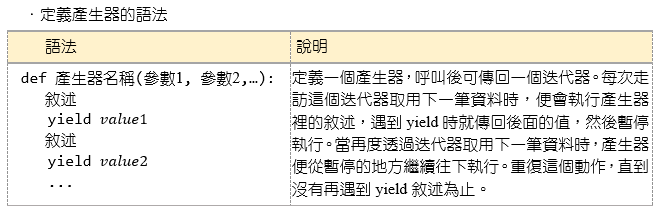

In [ ]:
def gen_test():
    a=5
    yield  a
    b=a+2
    yield  b  
    yield  b**2

In [ ]:
gi=gen_test()    # 建立一個產生器

In [ ]:
next(gi)

5

In [ ]:
next(gi)

7

In [ ]:
next(gi)

49

In [ ]:
next(gi)

StopIteration: 

In [ ]:
gi=gen_test()   # 重新建立一個產生器
for i in gi:
    print(i)

5
7
49


<font color=#DFFF00>☘ </font> 產生器最大的好處是節省記憶空間 （和 for 迴圈一次產生所有元素比較）

In [ ]:
def squ(n):   # 計算所有小於 n 的整數的平方
    lst=[]
    for i in range(1,n+1):
        lst.append(i**2)
    return lst

In [ ]:
squ(9)    # 計算結果會生成一個 list，會耗掉儲存空間

[1, 4, 9, 16, 25, 36, 49, 64, 81]

In [ ]:
def squ_gen(n):   # 利用產生器來完成一樣的工作
    for i in range(1,n+1):
        yield i**2 

In [ ]:
gi=squ_gen(9)      # 建立產生器物件
print(next(gi))
print(next(gi))

1
4


In [ ]:
list(gi)    # 一次提取出產生器裡剩餘的元素

[9, 16, 25, 36, 49, 64, 81]

# Python Comprehension 的設計動機

Python 的 **Comprehension（推導式）**，其設計動機主要是：**以更簡潔、直觀且具有表達力的方式，描述如何從既有的 Iterable 建立新的資料集合。**

它不只是簡化程式碼，也反映了 Functional Programming（FP）中 Data Transformation（資料轉換）的重要思想。

## 1. 為什麼需要 Comprehension？

假設我們有一個 List：

```python
numbers = [1, 2, 3, 4, 5]
```

希望將每個元素平方，並建立一個新的 List。

### 傳統寫法：使用 for loop

```python
numbers = [1, 2, 3, 4, 5]

result = []

for x in numbers:
    result.append(x ** 2)

print(result)
```

輸出：

```text
[1, 4, 9, 16, 25]
```

這種寫法需要：

1. 建立一個空 List。
2. 使用 `for` 逐一取得元素。
3. 計算平方。
4. 使用 `append()` 加入新 List。

### Comprehension 寫法

```python
numbers = [1, 2, 3, 4, 5]

result = [x ** 2 for x in numbers]

print(result)
```

輸出：

```text
[1, 4, 9, 16, 25]
```

只需要一行，就能表達完整的資料轉換。

**條件判斷**

在串列推導式裡可以加入條件判斷，就能只處理需要處理的元素，例如想建立一個從 1 到 10 的偶數串列，可以這樣寫：
```python
[num for num in range(1, 11) if num % 2 == 0]
[2, 4, 6, 8, 10]
```
看到這裡，不知道是否還記得資訊數數學導論集合構式set builder的寫法嗎？我們可以試著用串列推導式來改寫：

數字集合1 = { x | x > 0 且 x < 10 且 x 為偶數 }
```python
[n for n in range(1, 10) if n % 2 == 0]
[2, 4, 6, 8]
```
數字集合2 = { 2n | n 為 1 ~ 4 的自然數 }
```python
[2 * n for n in range(1, 5)]
[2, 4, 6, 8]
```
所以如果把條件判斷也加上去的話，推導式的完整型態會是：
```python
[ 結果 for 個體 in 集合 if 條件判斷 ]
```
**多層串列推導式？**

for 迴圈寫一層不夠可以寫兩層，串列推導式也可以寫出多個層次，《九九乘法表》為例：

九九乘法表
```python
for i in range(1, 10):
    for j in range(1, 10):
        print(f"{i} x {j} = {i * j}")
```
改用串列推導式來寫的話：
```python
multiplication_table = [f"{i} x {j} = {i * j}" for j in range(1, 10) for i in range(1, 10)]
print("\n".join(multiplication_table))
```
程式碼的確是只有一行，但這一行看起來有點複雜，以程式碼可讀性的角度來看，對我來說這樣的寫法並沒有比較清楚易懂。
所以如果串列推導式可能會寫得太複雜的話，倒不如用一般的 for 迴圈來寫就好。
在過去的經驗當中，單層的串列推導式通常寫起來會很開心，第二層開始就會突然變的複雜不少，第三層... 嗯，沒事不要寫第三層！

串列推導式的應用範圍非常廣，只要想建立有規則的串列，都可以考慮用串列推導式來寫。

若程式如下：

```python
for num in range(10):
    hey = "hello"
    print(num)

print(num)
print(hey)
```

則：

| 變數 | Scope |
|--------|--------|
| `num` | Global（若程式寫在最外層） |
| `hey` | Global（若程式寫在最外層） |

它們**不是 local variable**，因為 `for` 迴圈不會建立新的作用域（scope）。

若放在函式內：

```python
def f():
    for num in range(10):
        hey = "hello"
        print(num)

    print(num)
    print(hey)
```

則：

| 變數 | Scope |
|--------|--------|
| `num` | Local |
| `hey` | Local |

因為函式（function）才會建立新的作用域。

換言之，在 Python 中：

```text
for      不建立 Scope
while    不建立 Scope
if       不建立 Scope
```

而：

```text
function 建立 Scope
class    建立 Scope
module   建立 Scope
```
個人認為這是個不太好的設計，還好這個問題在串列推導式不會發生：
```python
[n for n in range(5)]
[0, 1, 2, 3, 4]
n
Traceback (most recent call last):
  File "<stdin>", line 1, in <module>
NameError: name 'n' is not defined
```
可以看到在推導式裡宣告的 n 在結束之後是不能取用的。不過在 Python 2 的話就不是這樣囉!

## 2. Comprehension 的核心動機

可以從三個角度理解。

### (1) Declarative Style：宣告式風格

傳統 `for loop` 比較著重描述執行步驟（How）。

```python
result = []

for x in numbers:
    result.append(x ** 2)
```

Comprehension 則比較著重描述希望得到什麼結果（What）。

```python
result = [x ** 2 for x in numbers]
```

也就是說：

- Imperative Programming：描述如何執行。
- Declarative Programming：描述希望得到什麼。

### (2) Data Transformation：資料轉換

Comprehension 很適合描述資料轉換。

例如，將所有數字平方：

```python
squares = [x ** 2 for x in range(10)]
```

只保留偶數：

```python
evens = [x for x in range(10) if x % 2 == 0]
```

將數字平方後，只保留偶數：

```python
result = [x ** 2 for x in range(10) if x % 2 == 0]
```

這裡可以看到兩個重要操作：

- `for`：取得資料。
- `if`：篩選資料。

這與 Functional Programming 中的 `map()` 和 `filter()` 思想相當接近。

### (3) Reduce Boilerplate：減少樣板程式碼

傳統寫法需要額外建立 List、呼叫 `append()`，並維護迴圈。

Comprehension 將這些重複性的程式結構整合成一個表達式，使程式碼更精簡。

## 3. Python Comprehension 的四種類型

| 類型 | 語法 | 產生結果 |
|---|---|---|
| List Comprehension | `[expr for x in iterable]` | List |
| Set Comprehension | `{expr for x in iterable}` | Set |
| Dictionary Comprehension | `{k: v for x in iterable}` | Dictionary |
| Generator Expression | `(expr for x in iterable)` | Generator |

例如：

```python
numbers = [1, 2, 2, 3, 4]

# List Comprehension
result1 = [x ** 2 for x in numbers]

# Set Comprehension
result2 = {x ** 2 for x in numbers}

# Dictionary Comprehension
result3 = {x: x ** 2 for x in numbers}

# Generator Expression
result4 = (x ** 2 for x in numbers)
```

特別注意：

前三種會建立相應的資料集合，而 Generator Expression 則是逐步產生資料，具有 Lazy Evaluation 的特性。

## 4. Comprehension 與 Functional Programming 的關係

這是教學上值得強調的部分。

Comprehension 可以用來表達與 `map()`、`filter()` 類似的資料處理。

| Comprehension | Functional Programming | 功能 |
|---|---|---|
| `[f(x) for x in data]` | `map(f, data)` | 資料轉換 |
| `[x for x in data if p(x)]` | `filter(p, data)` | 條件篩選 |
| `[f(x) for x in data if p(x)]` | `map(f, filter(p, data))` | 先篩選，再轉換 |
| `(f(x) for x in data)` | Lazy Mapping | 惰性資料轉換 |

例如：

```python
numbers = [1, 2, 3, 4, 5, 6]

# Comprehension
result1 = [x ** 2 for x in numbers if x % 2 == 0]

# map + filter
result2 = list(
    map(
        lambda x: x ** 2,
        filter(lambda x: x % 2 == 0, numbers)
    )
)

print(result1)
print(result2)
```

兩者結果相同：

```text
[4, 16, 36]
[4, 16, 36]
```

## 5. Comprehension 與 Lazy Evaluation 的差異

這個地方很容易讓學生混淆。

```python
numbers = range(10)

# Eager Evaluation
result1 = [x ** 2 for x in numbers]

# Lazy Evaluation
result2 = (x ** 2 for x in numbers)
```

| 比較 | List Comprehension | Generator Expression |
|---|---|---|
| 求值方式 | Eager | Lazy |
| 計算時機 | 建立時計算全部元素 | 需要時才計算 |
| 記憶體 | 儲存完整 List | 逐步產生元素 |
| 回傳型態 | List | Generator |
| 適合情境 | 需要完整資料集合 | 大型資料或串流處理 |

## 6. 總結：Comprehension 的設計精神

可以用一句話總結：

**Comprehension 的核心動機，是將資料集合的建立與轉換，從傳統的命令式迴圈，提升為更簡潔的宣告式表達。**

從 Python 與 FP 的觀點來看，可以將幾個概念串聯起來：

1. `for loop`：逐步描述資料處理過程。
2. `map()`、`filter()`：將資料轉換與篩選抽象化。
3. Comprehension：以宣告式語法描述資料集合的建立。
4. Generator Expression：結合 Comprehension 的表達方式與 Lazy Evaluation。

這也帶出一個值得思考的問題：

**當我們只需要描述資料如何轉換時，是否一定需要自己撰寫迴圈、建立空 List，再逐一呼叫 `append()`？**

這正是 Python Comprehension 想要解決的問題。

# List Comprehension 的優勢

List Comprehension 的主要優勢並不是降低時間複雜度，而是改善程式碼的表達方式（Expressiveness）、可讀性（Readability），以及在某些情況下提升執行效率。

如果從演算法與程式語言的角度來看，可以分成五個面向。

## 1. 時間複雜度：兩者基本相同

例如，從 1 到 10，找出偶數並平方。

**傳統 for loop**

```python
result = []

for x in range(1, 11):
    if x % 2 == 0:
        result.append(x ** 2)
```

**List Comprehension**

```python
result = [x ** 2 for x in range(1, 11) if x % 2 == 0]
```

兩者的時間複雜度都是：

$$
T(n)=O(n)
$$

空間複雜度也都是：

$$
S(n)=O(n)
$$

因此，List Comprehension 並沒有改變演算法的漸近複雜度（Asymptotic Complexity）。

## 2. 執行效率：Python 實作上的差異

雖然時間複雜度相同，但實際執行時間可能不同。

原因在於 Python 的內部實作方式。

| 比較項目 | For Loop | List Comprehension |
|---|---|---|
| 迴圈控制 | Python bytecode 執行 | 專門的 comprehension bytecode |
| append 操作 | 每次呼叫 `append()` | 內部直接建立並加入元素 |
| 區域變數 | 使用一般迴圈變數 | 有自己的 comprehension scope |
| 執行效率 | 通常較慢 | 通常較快 |

List Comprehension 減少了部分 Python 層級的操作，因此在某些情況下可以有較好的執行效率。

但要注意：

**這是 Python Interpreter 的實作優化，不代表 List Comprehension 使用了更好的演算法。**

## 3. 表達能力：Declarative vs. Imperative

這是值得在教學中強調的地方。

傳統 for loop 偏向 Imperative Programming（命令式程式設計）。

```python
result = []

for x in numbers:
    if x > 0:
        result.append(x * 2)
```

程式設計師告訴電腦：

1. 建立一個空 List。
2. 逐一取出元素。
3. 判斷元素是否大於零。
4. 將符合條件的元素乘以二。
5. 加入 List。

List Comprehension 則更接近 Declarative Programming（宣告式程式設計）。

```python
result = [x * 2 for x in numbers if x > 0]
```

程式設計師直接描述：

> 我要一個 List，內容是所有大於零的元素乘以二。

兩者描述的是相同的計算，但抽象層次不同。

## 4. 與 Functional Programming 的關係

List Comprehension 也很適合用來理解 Functional Programming（FP）的思想。

例如：

```python
numbers = [1, 2, 3, 4, 5]

result = [x * x for x in numbers if x % 2 == 0]
```

可以拆解成兩個概念：

- Filter：篩選符合條件的元素。
- Map：將符合條件的元素轉換成平方。

使用 Python 的 `filter()` 和 `map()`：

```python
result = list(
    map(
        lambda x: x * x,
        filter(lambda x: x % 2 == 0, numbers)
    )
)
```

兩者的計算結果相同。

不過，List Comprehension 通常更容易閱讀，也避免了多層函數呼叫的視覺負擔。

## 5. 從軟體設計的角度比較

| 面向 | For Loop | List Comprehension |
|---|---|---|
| 時間複雜度 | $O(n)$ | $O(n)$ |
| 空間複雜度 | $O(n)$ | $O(n)$ |
| 程式風格 | Imperative | Declarative |
| 表達重點 | 如何執行（How） | 想要什麼結果（What） |
| 可讀性 | 適合複雜流程 | 適合簡單轉換與篩選 |
| 執行效率 | 通常稍慢 | 某些情況較快 |
| 除錯 | 容易逐步追蹤 | 不適合複雜除錯 |

## 6. 不要為了簡潔而使用 List Comprehension

例如：

```python
result = [
    process(x)
    for x in data
    if condition1(x)
    and condition2(x)
]
```

如果邏輯逐漸複雜，傳統 for loop 反而更容易維護。

另外，如果資料量很大，而且不需要一次建立完整 List，可以考慮 Generator Expression：

```python
result = (
    x * x
    for x in numbers
    if x % 2 == 0
)
```

這時候就有不同的空間複雜度：

| 方法 | 時間複雜度 | 額外空間複雜度 |
|---|---|---|
| For Loop 建立 List | $O(n)$ | $O(n)$ |
| List Comprehension | $O(n)$ | $O(n)$ |
| Generator Expression | $O(n)$（完整消耗時） | $O(1)$（不計算輸出資料的儲存空間） |

## 7. 總結

可以將這三種寫法放在一起理解：

- **For Loop：** 強調控制流程（Control Flow）。
- **List Comprehension：** 強調資料轉換（Data Transformation）。
- **Generator Expression：** 強調 Lazy Evaluation（延遲求值）。

不會誤以為 List Comprehension 只是一種比較簡短的 for loop，而能進一步理解 Python 如何從命令式程式設計走向函數式與宣告式的程式設計思想。

**核心觀念：**

List Comprehension 的價值不在於改變演算法的時間複雜度，而在於提高程式碼的表達能力，讓程式設計師更直接地描述資料轉換的目的。

從觀念說起，建立0-5 的串列

In [1]:
xlst = []     
xlst.append(0)
xlst.append(1)
xlst.append(2)
xlst.append(3)
xlst.append(4)
xlst.append(5)
print(xlst)  
              

[0, 1, 2, 3, 4, 5]


In [ ]:
# 如果要讓程式設計更有效率，讀者可以使用—個for 迴圈和range() 。
xlst = []         
for n in range(6):
    xlst.append(n)
print(xlst)       

In [ ]:
# 或是直接使用list()將range(n) 當作是參數。
xlst = list(range(6))
print(xlst)          

上述方法均可以完成工作，但是如果要成為真正的Python 工程師，建議是使用串列推導式(list comprehension) 的觀念。在說明實例前先看串列推導式的語法：
```python
新串列＝[ 運算式 for 項目 in 可迭代物件]
```
上述語法觀念是，將每個可迭代物件套入運算式，每次產生一個串列元素。
如果將串列推導式的觀念應用在上述實例，整個內容如下：
```python
xlst = [ n for n in range(6)]
```
上述第1 個n 是產生串列的值，也可以想成迴圏結果的值，第2 個n 是for 迴圈的—部份，用於迭代range(6) 內容。

In [ ]:
xlst = [ n for n in range(6)]
print(xlst)                  

In [ ]:
n = int(input("請輸入整數:"))                
if n > 10 : n = 10               # 最大值是10
squares = [num ** 2 for num in range(1, n+1)]
print(squares)                               

**含有條件式的串列推導**

這時語法如下：
```python
新串列＝［ 運算式 for 項目 in 可迭代物件 if 條件式］
```

<font color=#DB9B1A>- 串列推導式 - </font>

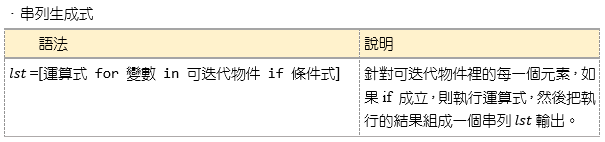

In [2]:
nums=[3,5,-1,4,9]

In [3]:
# select only positive elements

squ=[i for i in nums if i>0]
print(squ)

[3, 5, 4, 9]


In [4]:
# set the negative values to zero, using list comprehension 
nums=[7,9,-8,-2,9,3]
non_z=[i if i>0 else 0 for i in nums]
print(non_z)

[7, 9, 0, 0, 9, 3]


In [5]:
# select only positive elements, and square even numbers
nums=[3,6,-6,4,9]
squ=[i**2 if i%2==0 else i for i in nums if i>0]
print(squ)

[3, 36, 16, 9]


In [6]:
fruits=['apple',
        'kiwi',
        'gava',
        'orange']

In [7]:
# using list compresension
selection=[fruit for fruit in fruits if 'a' in fruit]
print(selection)

['apple', 'gava', 'orange']


In [8]:
# 將帶有字母 a 的字串取出，並將它們轉成大寫
selection=[fruit.upper() for fruit in fruits if 'a' in fruit]
print(selection)


['APPLE', 'GAVA', 'ORANGE']


In [9]:
# 巢狀的串列推導式
size=['big','small']
color=['red','green','blue']

In [10]:
# 利用兩個for迴圈將 size 和 color 兩個串列的元素組合成序對
lst=[]
for s in size:
    for c in color:
        lst.append((s,c))
lst

[('big', 'red'),
 ('big', 'green'),
 ('big', 'blue'),
 ('small', 'red'),
 ('small', 'green'),
 ('small', 'blue')]

In [11]:
# 改用串列生成式
[(s,c) for s in size for c in color]

[('big', 'red'),
 ('big', 'green'),
 ('big', 'blue'),
 ('small', 'red'),
 ('small', 'green'),
 ('small', 'blue')]

In [ ]:
nest_list = [[1],
             [17, 19],
             [12,5,7,39]]

In [ ]:
# flatten nested list, using for loop
new_list=[]
for lst in nest_list:
    for n in lst:
        new_list.append(n)
new_list

[1, 17, 19, 12, 5, 7, 39]

In [ ]:
# flatten nested list, using nested list comprehension
[n for lst in nest_list for n in lst]

[1, 17, 19, 12, 5, 7, 39]

In [ ]:
# selects elements with value greater than 10
[n for lst in nest_list for n in lst if n>10]

[17, 19, 12, 39]

In [ ]:
# same above,but further set elements with value greater than 20 to 20
[n if n<=20 else 20 for lst in nest_list for n in lst if n>10]

[17, 19, 12, 20]


<font color=#DFFF00>☘ </font> 利用類似串列推導式的語法來建立產生器 （generator using list comprehension）

In [ ]:
lst=[i**2 for i in range(1,11)]

In [ ]:
lst

[1, 4, 9, 16, 25, 36, 49, 64, 81, 100]

In [ ]:
gen=(i**2 for i in range(1,11))  # 用圓括號掛起來

In [ ]:
print(next(gen))
print(next(gen))
print(next(gen))

1
4
9


In [ ]:
for i in gen:
    print(f'{i:4d}',end='')

  16  25  36  49  64  81 100

#### 元組的定義

串列在定義時是將元素放在中括號內，元組的定義則時將元素放在小括號＂ （） ＂內，下列是元組的語法格式。
```python
X = (元素1, ..., 元素n) #x 是假設的元組名稱
```
基本上元組的每一筆資料稱元素，元素可以是整數、字串或串列等，這些元素放在小括號（）內，彼此用逗號","隔開，最右邊的元素n 的","可有可無。如果要列印元組內容，可以使用print()函數，將元組名稱當作變數名稱即可。

如果元組內的元素只有一個，在定義時需在元素右邊加上逗號(", ")。
```python
X = (元素1, ) #只有一個元素的元組
```

In [12]:
# 定義與列印元組，最後使用type() 列出元組資料型態。
numbers1 = (1, 2, 3, 4, 5)      # 定義元組元素是整數        
fruits = ('apple', 'orange')    # 定義元組元素是字串        
mixed = ('James', 50)           # 定義元組元素是不同型態資料
val_tuple = (10,)               # 只有一個元素的元祖        
print(numbers1)                                             
print(fruits)                                               
print(mixed)                                                
print(val_tuple)                                            
# 列出元組資料型態                                          
print("元組mixed資料型態是: ",type(mixed))                  

(1, 2, 3, 4, 5)
('apple', 'orange')
('James', 50)
(10,)
元組mixed資料型態是:  <class 'tuple'>


另外—個簡便建立元組有多個元素的方法是，用等號，右邊有一系列元素，元素彼此用逗號隔開。（打包）

In [14]:
ｘ = 5, 6
type(x)
ｘ

(5, 6)

#### 讀取元組元素
定義元組時是使用小括號＂（ ） ＂， 如果想要讀取元組內容和串列是—樣的用中括號＂［］＂ 。
在Python 中元組元素是從索引值0 開始配置。
所以如果是元組的第一筆元素， 索引值是0, 第二筆元素索引值是1, 其他依此類推，如下所示：
```python
x[i]  #讀取索引i的元組元素
```

In [ ]:
numbers1 = (1, 2, 3, 4, 5)      # 定義元組元素是整數
fruits = ('apple', 'orange')    # 定義元組元素是字串
val_tuple = (10,)               # 只有一個元素的元祖
print(numbers1[0])              # 以中括號索引值讀取元素內容
print(numbers1[4])
print(fruits[0],fruits[1])
print(val_tuple[0])
x, y = ('apple', 'orange')      
print(x,y)
x, y = fruits
print(x,y)

In [ ]:
# 使用for 迴圈走訪所有元組元素， 用法與串列相同。
keys = ('magic', 'xaab', 9099)      # 定義元組元素是字串與數字
for key in keys:                                              
    print(key)                                                

In [15]:
# 修改元組內容產生錯誤的實例
fruits = ('apple', 'orange')        # 定義元組元素是字串      
print(fruits[0])                    # 列印元組fruits[0]       
fruits[0] = 'watermelon'            # 將元素內容改為watermelon
print(fruits[0])                    # 列印元組fruits[0]       

apple


TypeError: 'tuple' object does not support item assignment

In [ ]:
# 用重新定義方式修改元組元素內容。
# 沒有修改 tuple 的內容，而是讓變數 fruits 重新指向另一個 tuple 物件
fruits = ('apple', 'orange')        # 定義元組元素是水果
print("原始fruits元組元素")                             
for fruit in fruits:                                    
    print(fruit)                                        
                                                        
                                                        
fruits = ('watermelon', 'grape')    # 定義新的元組元素  
print("\n新的fruits元組元素")                           
for fruit in fruits:                                    
    print(fruit)                                        

原始fruits元組元素
apple
orange

新的fruits元組元素
watermelon
grape


In [17]:
# 字串也是 immutable。
name = "Jack"
name = "Mary"
name[0] = 'M'

TypeError: 'str' object does not support item assignment

Dictionary Comprehension

新字典＝｛ 鍵運算式：值運算式 for 運算式 in  可迭代物件｝

In [ ]:
# 使用字典生成式記錄單字 Jack Pan，每個字母出現的次數。
word = 'Jack Pan'                                                   
alphabetCount = {alphabet:word.count(alphabet) for alphabet in word}
print(alphabetCount)                                                

{'J': 1, 'a': 2, 'c': 1, 'k': 1, ' ': 1, 'P': 1, 'n': 1}


只需—列程式碼（第3 列）就將－個單字每個字母的出現次數列出來，這就是Python 奧妙的地方。
上述程式的執行原理是將每個單字出現的次數當作是鍵的值，是懂Python 的程式設計師會使用的方式。

In [2]:
song = """Are you sleeping, are you sleeping, Brother John, Brother John?
Morning bells are ringing, morning bells are ringing.                    
Ding ding dong, Ding ding dong."""                                       
#mydict = {}                         # 省略,空字典未來儲存單字計數結果   
print("原始歌曲")                                                        
print(song)                                                              
                                                                         
                                                                         
# 以下是將歌曲大寫字母全部改成小寫                                       
songLower = song.lower()            # 歌曲改為小寫                       
print("小寫歌曲")                                                        
print(songLower)                                                         
                                                                         
                                                                         
# 將歌曲的標點符號用空字元取代                                           
for ch in songLower:                                                     
    if ch in ".,?":                                                      
        songLower = songLower.replace(ch,'')                             
print("不再有標點符號的歌曲")                                            
print(songLower)                                                         
                                                                         
                                                                         
# 將歌曲字串轉成串列                                                     
songList = songLower.split()                                             
print("以下是歌曲串列")                                                  
print(songList)                     # 列印歌曲串列                       
                                                                         
                                                                         
# 將歌曲串列處理成字典                                                   
mydict = {wd:songList.count(wd) for wd in songList}                      
print("以下是最後執行結果")                                              
print(mydict)                       # 列印字典                           

原始歌曲
Are you sleeping, are you sleeping, Brother John, Brother John?
Morning bells are ringing, morning bells are ringing.                    
Ding ding dong, Ding ding dong.
小寫歌曲
are you sleeping, are you sleeping, brother john, brother john?
morning bells are ringing, morning bells are ringing.                    
ding ding dong, ding ding dong.
不再有標點符號的歌曲
are you sleeping are you sleeping brother john brother john
morning bells are ringing morning bells are ringing                    
ding ding dong ding ding dong
以下是歌曲串列
['are', 'you', 'sleeping', 'are', 'you', 'sleeping', 'brother', 'john', 'brother', 'john', 'morning', 'bells', 'are', 'ringing', 'morning', 'bells', 'are', 'ringing', 'ding', 'ding', 'dong', 'ding', 'ding', 'dong']
以下是最後執行結果
{'are': 4, 'you': 2, 'sleeping': 2, 'brother': 2, 'john': 2, 'morning': 2, 'bells': 2, 'ringing': 2, 'ding': 4, 'dong': 2}


In [3]:
# 星座字典的設計，這個程式會要求輸入星座，如果所輸入的星座正確則輸出此星座的時間區間和本月運勢，如果所輸入的星座錯誤，則輸出星座輸入錯誤。
season = {'水瓶座':'1月20日 - 2月18日, 需警惕小人',      
          '雙魚座':'2月19日 - 3月20日, 凌亂中找立足',    
          '白羊座':'3月21日 - 4月19日, 運勢比較低迷',    
          '金牛座':'4月20日 - 5月20日, 財運較佳',        
          '雙子座':'5月21日 - 6月21日, 運勢好可錦上添花',
          '巨蟹座':'6月22日 - 7月22日, 不可鬆懈大意',    
          '獅子座':'7月23日 - 8月22日, 會有成就感',      
          '處女座':'8月23日 - 9月22日, 會有挫折感',      
          '天秤座':'9月23日 - 10月23日, 運勢給力',       
          '天蠍座':'10月24日 - 11月22日, 中規中矩',      
          '射手座':'11月23日 - 12月21日, 可羨煞眾人',    
          '魔羯座':'12月22日 - 1月19日, 需保有謙虛',     
          }                                              
                                                         
                                                         
wd = input("請輸入欲查詢的星座 : ")                      
if wd in season:                                         
    print(wd, " 本月運勢 : ", season[wd])                
else:                                                    
    print("星座輸入錯誤")                                

水瓶座  本月運勢 :  1月20日 - 2月18日, 需警惕小人


#### 集合

集合（Set）是一種用來儲存不重複元素的資料型別。集合中的元素沒有固定順序（unordered），而且重複的元素在建立集合時會被自動移除。因此，集合中不允許存在重複元素。

```python
集合型別＝{元素l, 元素2, ...}
```
或
```python
集合型別＝ set(iterable)
```
或 集合生成式(set compresention)
```python
新集合＝｛運算式 for 運算式 in 可迭代項目｝
```


https://docs.python.org/3/builtins/stdtypes.html#set-types-set-frozenset

字串(string)、串列(list)、元組(tuple)、字典(dict)等都是iterable

In [6]:
fruits = {'apple', 'orange', 'apple', 'banana'}
print(fruits)

{'orange', 'apple', 'banana'}


In [4]:
A = set([1, 2, 2, 3])
print(A)

{1, 2, 3}


In [ ]:
# 空集合
s = set() 
print(s)

# 注意：{}建立的是空字典（dictionary），而不是空集合。

set()


In [7]:
A = set(['Python', 'Python', 'Java','C'])
print(A)

{'Python', 'Java', 'C'}


In [1]:
A = {n for n in range(1,100,2)}
print(type(A))                 
print(A)                       

<class 'set'>
{1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 33, 35, 37, 39, 41, 43, 45, 47, 49, 51, 53, 55, 57, 59, 61, 63, 65, 67, 69, 71, 73, 75, 77, 79, 81, 83, 85, 87, 89, 91, 93, 95, 97, 99}


In [2]:
A = {n for n in range(1,100,2) if n % 11 == 0}
print(type(A))                                
print(A)                                      

<class 'set'>
{33, 99, 11, 77, 55}


In [3]:
# 使用集合觀念重新設計：原先要使用串列生成式，然後將串列改為集合，現在可以直接用集合生成式完成
word = 'Jack Pan'                                                        
alphabetCount = {alphabet:word.count(alphabet) for alphabet in set(word)}
print(alphabetCount)                                                     

{' ': 1, 'c': 1, 'J': 1, 'a': 2, 'k': 1, 'n': 1, 'P': 1}


**雞尾酒的實例**

雞尾酒是酒精飲料，由基酒和—些飲料調製而成，下列是—些常見的雞尾酒飲料以及它的配方。

- 藍色夏威夷佬(Blue Hawaiian):蘭姆酒(rum)、甜酒(sweet wine)、椰奶(coconut cream)、鳯梨汁(pineapple juice)、檸檬汁(lemon jui ce) 。
- 薑昧莫西多(Ginger Mojito):蘭姆酒(rum)、薑(ginger)、薄荷葉(mint leaves)、萊姆汁(lime juice)、薑汁汽水(ginger soda) 。
- 紐約客(New Yorker):威士忌(whiskey)、紅酒(red wine)、檸檬汁(lemon juice)、糖水(sugar syrup) 。
- 血腥瑪莉(Bloody Mary):伏特加(vodka)、檸檬汁(lemon juice)、番茄汁(tomato juice)、酸辣醬(tabasco)、少量鹽(little salt) 。

為上述雞尾酒建立一個字典，上述字典的鍵(key)是字串，也就是雞尾酒的名稱，字典的值是集合，內容是各種雞尾酒的材料配方。這個程式會列出
含有伏特加配方的酒，利含有檸檬汁的酒、含有蘭姆酒但沒有薑的酒。

下面述程式用in 測試指定的雞尾酒材料配方是否在所傳回字典值(value)的formulas 集合內，另外程式第26 列則是將formulas 與集合元素，Cream、Tabasco做交集（＆），如果formulas 內沒有這些配方結果會是False，經過not就會是True，則可以列印name 。

In [ ]:

cocktail = {                                                                     
    'Blue Hawaiian':{'Rum','Sweet Wine','Cream','Pineapple Juice','Lemon Juice'},
    'Ginger Mojito':{'Rum','Ginger','Mint Leaves','Lime Juice','Ginger Soda'},   
    'New Yorker':{'Whiskey','Red Wine','Lemon Juice','Sugar Syrup'},             
    'Bloody Mary':{'Vodka','Lemon Juice','Tomato Juice','Tabasco','little Sale'} 
    }                                                                            
# 列出含有Vodka的酒                                                              
print("含有Vodka的酒 : ")                                                        
for name, formulas in cocktail.items():                                          
    if 'Vodka' in formulas:                                                      
        print(name)                                                              
# 列出含有Lemon Juice的酒                                                        
print("含有Lemon Juice的酒 : ")                                                  
for name, formulas in cocktail.items():                                          
    if 'Lemon Juice' in formulas:                                                
        print(name)                                                              
# 列出含有Rum但是沒有薑的酒                                                      
print("含有Rum但是沒有薑的酒 : ")                                                
for name, formulas in cocktail.items():                                          
    if 'Rum' in formulas and not ('Ginger' in formulas):                         
        print(name)                                                              
# 列出含有Lemon Juice但是沒有Cream或是Tabasco的酒                                
print("含有Lemon Juice但是沒有Cream或是Tabasco的酒 : ")                          
for name, formulas in cocktail.items():                                          
    if 'Lemon Juice' in formulas and not formulas & {'Cream', 'Tabasco'}:        
        print(name)                                                              

含有Vodka的酒 : 
Bloody Mary
含有Lemon Juice的酒 : 
Blue Hawaiian
New Yorker
Bloody Mary
含有Rum但是沒有薑的酒 : 
Blue Hawaiian
含有Lemon Juice但是沒有Cream或是Tabasco的酒 : 
New Yorker
